In [1]:
import os
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

In [2]:
DATASET1 = "/kaggle/input/datasets/forst12/x-ray-lung"

DATASET2 = "/kaggle/input/datasets/forst12/lung-x-ray-image"

DATASET3 = "/kaggle/input/datasets/forst12/cxr8-subset/SUBSETS"

In [3]:
BASE_OUTPUT = "/kaggle/working/PDVSF_RESULTS"

OUTPUTS = {

    "Dataset1":
    os.path.join(BASE_OUTPUT, "Dataset1_Kaggle"),

    "Dataset2":
    os.path.join(BASE_OUTPUT, "Dataset2_Mendeley"),

    "Dataset3":
    os.path.join(BASE_OUTPUT, "Dataset3_CXR8")
}


SUBFOLDERS = [

    "Dataset_Analysis",
    "ROI",
    "Preprocessing",
    "G1",
    "G2",
    "G3",
    "G4",
    "PDVSF",
    "Models",
    "Final_Results"
]

for dataset in OUTPUTS.values():

    os.makedirs(dataset, exist_ok=True)

    for folder in SUBFOLDERS:
        os.makedirs(os.path.join(dataset, folder), exist_ok=True)

print("Folders created successfully.")

Folders created successfully.


In [4]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")


def load_folder_dataset(dataset_path):

    image_paths = []
    labels = []

    classes = sorted([
        d for d in os.listdir(dataset_path)
        if os.path.isdir(os.path.join(dataset_path, d))
    ])

    for cls in classes:

        cls_path = os.path.join(dataset_path, cls)

        for img in os.listdir(cls_path):

            if img.lower().endswith(IMAGE_EXTENSIONS):

                image_paths.append(os.path.join(cls_path, img))
                labels.append(cls)

    return pd.DataFrame({

        "Image": image_paths,
        "Label": labels
    })

In [5]:
def load_cxr8_dataset(base_path):

    train_csv = os.path.join(base_path, "prop_train.csv")
    test_csv = os.path.join(base_path, "prop_test.csv")

    train = pd.read_csv(train_csv)
    test = pd.read_csv(test_csv)

    train["Split"] = "Train"
    test["Split"] = "Test"

    df = pd.concat([train, test], ignore_index=True)

    image_folder = os.path.join(base_path, "Images")

    df["Image"] = df["Image Index"].apply(

        lambda x: os.path.join(image_folder, x)
    )

    df.rename(columns={"label":"Label"}, inplace=True)

    return df[["Image","Label","Split"]]

In [6]:
df1 = load_folder_dataset(DATASET1)

df2 = load_folder_dataset(DATASET2)

df3 = load_cxr8_dataset(DATASET3)

print(df1.shape)
print(df2.shape)
print(df3.shape)

(6743, 2)
(3475, 2)
(14991, 3)


In [7]:
def dataset_statistics(df, output_folder, dataset_name):

    stats = df["Label"].value_counts().sort_index()

    stats.to_csv(

        os.path.join(
            output_folder,
            "Dataset_Analysis",
            "Class_Distribution.csv"
        )
    )

    print(dataset_name)
    print(stats)

    return stats

In [8]:
stats1 = dataset_statistics(df1, OUTPUTS["Dataset1"], "Dataset1")

stats2 = dataset_statistics(df2, OUTPUTS["Dataset2"], "Dataset2")

stats3 = dataset_statistics(df3, OUTPUTS["Dataset3"], "Dataset3")

Dataset1
Label
00 Anatomia Normal                                                                           1340
01 Processos Inflamatórios Pulmonares (Pneumonia)                                            1060
02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)          678
03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)                           629
04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)        644
05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)           594
06 Lesões Encapsuladas (Abscessos, Nódulos, Cistos, Massas Tumorais, Metastases)              658
07 Alterações de Mediastino (Pericardite, Malformações Arteriovenosas, Linfonodomegalias)     596
08 Alterações do Tórax (Atelectasias, Malformações, Agenesia, Hipoplasias)                    544
Name: count, dtype: int64
Dataset2
Label
Lung_Opacity       1125
Normal             1250
Viral Pneumoni

In [9]:
stats1 = dataset_statistics(df1, OUTPUTS["Dataset1"], "Dataset1")
stats2 = dataset_statistics(df2, OUTPUTS["Dataset2"], "Dataset2")
stats3 = dataset_statistics(df3, OUTPUTS["Dataset3"], "Dataset3")

Dataset1
Label
00 Anatomia Normal                                                                           1340
01 Processos Inflamatórios Pulmonares (Pneumonia)                                            1060
02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)          678
03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)                           629
04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)        644
05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)           594
06 Lesões Encapsuladas (Abscessos, Nódulos, Cistos, Massas Tumorais, Metastases)              658
07 Alterações de Mediastino (Pericardite, Malformações Arteriovenosas, Linfonodomegalias)     596
08 Alterações do Tórax (Atelectasias, Malformações, Agenesia, Hipoplasias)                    544
Name: count, dtype: int64
Dataset2
Label
Lung_Opacity       1125
Normal             1250
Viral Pneumoni

In [10]:
print(type(stats1))
print(type(stats2))
print(type(stats3))

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


In [11]:
def plot_distribution(stats, output_folder, title):

    plt.figure(figsize=(12,6))

    stats.plot(

        kind="bar",
        color="steelblue",
        edgecolor="black"
    )

    plt.ylabel("Number of Images")

    plt.xlabel("Classes")

    plt.title(title)

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            output_folder,
            "Dataset_Analysis",
            "Class_Distribution.png"
        ),
        dpi=600
    )

    plt.close()

In [12]:
print(stats1)

Label
00 Anatomia Normal                                                                           1340
01 Processos Inflamatórios Pulmonares (Pneumonia)                                            1060
02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)          678
03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)                           629
04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)        644
05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)           594
06 Lesões Encapsuladas (Abscessos, Nódulos, Cistos, Massas Tumorais, Metastases)              658
07 Alterações de Mediastino (Pericardite, Malformações Arteriovenosas, Linfonodomegalias)     596
08 Alterações do Tórax (Atelectasias, Malformações, Agenesia, Hipoplasias)                    544
Name: count, dtype: int64


In [13]:
plot_distribution(
    stats1,
    OUTPUTS["Dataset1"],
    "Dataset1 Class Distribution"
)

plot_distribution(
    stats2,
    OUTPUTS["Dataset2"],
    "Dataset2 Class Distribution"
)

plot_distribution(
    stats3,
    OUTPUTS["Dataset3"],
    "Dataset3 Class Distribution"
)

In [14]:
def show_random_images(df, output_folder, title):

    samples = df.sample(9, random_state=42)

    plt.figure(figsize=(10,10))

    for i, (_, row) in enumerate(samples.iterrows()):

        img = cv2.imread(row["Image"])

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(3,3,i+1)

        plt.imshow(img)

        plt.title(row["Label"], fontsize=8)

        plt.axis("off")

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            output_folder,
            "Dataset_Analysis",
            "Random_Samples.png"
        ),
        dpi=600
    )

    plt.close()

In [15]:
show_random_images(
    df1,
    OUTPUTS["Dataset1"],
    "Dataset1"
)

show_random_images(
    df2,
    OUTPUTS["Dataset2"],
    "Dataset2"
)

show_random_images(
    df3,
    OUTPUTS["Dataset3"],
    "Dataset3"
)

In [16]:
# ==========================================================
# DATASET SUMMARY TABLE
# ==========================================================

import os
import cv2
import pandas as pd


def get_first_image_resolution(image_paths):
    """
    Returns original image resolution as Width×Height
    """
    for img_path in image_paths:
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            if img is not None:
                h, w = img.shape[:2]
                return f"{w} × {h}"
    return "Unknown"


# ==========================================================
# Dataset 1
# ==========================================================

d1_num_classes = df1["Label"].nunique()
d1_total_images = len(df1)

d1_train = int(0.8 * d1_total_images)
d1_test  = d1_total_images - d1_train

d1_resolution = get_first_image_resolution(df1["Image"].tolist())


# ==========================================================
# Dataset 2
# ==========================================================

d2_num_classes = df2["Label"].nunique()
d2_total_images = len(df2)

d2_train = int(0.8 * d2_total_images)
d2_test  = d2_total_images - d2_train

d2_resolution = get_first_image_resolution(df2["Image"].tolist())


# ==========================================================
# Dataset 3
# ==========================================================

d3_num_classes = df3["Label"].nunique()

d3_total_images = len(df3)

d3_train = len(df3[df3["Split"]=="Train"])
d3_test  = len(df3[df3["Split"]=="Test"])

d3_resolution = get_first_image_resolution(df3["Image"].tolist())


# ==========================================================
# CREATE SUMMARY TABLE
# ==========================================================

summary = pd.DataFrame({

    "Metric":[

        "Number of Classes",
        "Number of Images",
        "Training Images",
        "Testing Images",
        "Original Image Resolution"

    ],

    "Dataset 1 (Kaggle)": [

        d1_num_classes,
        d1_total_images,
        d1_train,
        d1_test,
        d1_resolution

    ],

    "Dataset 2 (Mendeley)": [

        d2_num_classes,
        d2_total_images,
        d2_train,
        d2_test,
        d2_resolution

    ],

    "Dataset 3 (CXR8)": [

        d3_num_classes,
        d3_total_images,
        d3_train,
        d3_test,
        d3_resolution

    ]

})

print(summary)

                      Metric Dataset 1 (Kaggle) Dataset 2 (Mendeley)  \
0          Number of Classes                  9                    3   
1           Number of Images               6743                 3475   
2            Training Images               5394                 2780   
3             Testing Images               1349                  695   
4  Original Image Resolution          450 × 450            299 × 299   

  Dataset 3 (CXR8)  
0               15  
1            14991  
2            11992  
3             2999  
4      1024 × 1024  


In [17]:
# ==========================================================
# SAVE
# ==========================================================

summary.to_csv(
    os.path.join(BASE_OUTPUT, "Dataset_Summary_Table.csv"),
    index=False
)

summary.to_excel(
    os.path.join(BASE_OUTPUT, "Dataset_Summary_Table.xlsx"),
    index=False
)

print("Dataset Summary Table Saved Successfully.")

Dataset Summary Table Saved Successfully.


In [18]:
import os
import cv2
import numpy as np
import pandas as pd

from collections import Counter


def analyse_dataset(df):

    widths = []
    heights = []
    channels = []
    formats = []

    for img_path in df["Image"]:

        if not os.path.exists(img_path):
            continue

        img = cv2.imread(img_path)

        if img is None:
            continue

        h,w = img.shape[:2]

        heights.append(h)
        widths.append(w)

        if len(img.shape)==2:
            channels.append(1)
        else:
            channels.append(img.shape[2])

        formats.append(os.path.splitext(img_path)[1].lower())

    return {

        "num_images":len(widths),

        "min_width":np.min(widths),
        "max_width":np.max(widths),
        "avg_width":np.mean(widths),

        "min_height":np.min(heights),
        "max_height":np.max(heights),
        "avg_height":np.mean(heights),

        "formats":Counter(formats),

        "channels":Counter(channels)
    }

In [19]:
profile1 = analyse_dataset(df1)

profile2 = analyse_dataset(df2)

profile3 = analyse_dataset(df3)

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


In [20]:
dataset_table = pd.DataFrame({

"Metric":[

"Number of Classes",

"Number of Images",

"Training Images",

"Testing Images",

"Minimum Width",

"Maximum Width",

"Average Width",

"Minimum Height",

"Maximum Height",

"Average Height",

"Image Format",

"Color Channels",

"Average Images/Class"

],

"Dataset1":[

d1_num_classes,

d1_total_images,

d1_train,

d1_test,

profile1["min_width"],

profile1["max_width"],

round(profile1["avg_width"],2),

profile1["min_height"],

profile1["max_height"],

round(profile1["avg_height"],2),

",".join(profile1["formats"].keys()),

",".join(map(str,profile1["channels"].keys())),

round(d1_total_images/d1_num_classes,2)

],

"Dataset2":[

d2_num_classes,

d2_total_images,

d2_train,

d2_test,

profile2["min_width"],

profile2["max_width"],

round(profile2["avg_width"],2),

profile2["min_height"],

profile2["max_height"],

round(profile2["avg_height"],2),

",".join(profile2["formats"].keys()),

",".join(map(str,profile2["channels"].keys())),

round(d2_total_images/d2_num_classes,2)

],

"Dataset3":[

d3_num_classes,

d3_total_images,

d3_train,

d3_test,

profile3["min_width"],

profile3["max_width"],

round(profile3["avg_width"],2),

profile3["min_height"],

profile3["max_height"],

round(profile3["avg_height"],2),

",".join(profile3["formats"].keys()),

",".join(map(str,profile3["channels"].keys())),

round(d3_total_images/d3_num_classes,2)

]

})

In [21]:
dataset_table.to_csv(

os.path.join(BASE_OUTPUT,

"Dataset_Statistics.csv"),

index=False)

dataset_table.to_excel(

os.path.join(BASE_OUTPUT,

"Dataset_Statistics.xlsx"),

index=False)

In [22]:
def plot_resolution(df, save_path):

    widths=[]
    heights=[]

    for img_path in df["Image"]:

        img=cv2.imread(img_path)

        if img is None:
            continue

        h,w=img.shape[:2]

        widths.append(w)

        heights.append(h)

    plt.figure(figsize=(8,6))

    plt.scatter(widths,heights,
                s=10,
                alpha=0.6)

    plt.xlabel("Width")

    plt.ylabel("Height")

    plt.title("Image Resolution Distribution")

    plt.tight_layout()

    plt.savefig(save_path,dpi=600)

    plt.close()

In [23]:
plot_resolution(

df1,

os.path.join(

OUTPUTS["Dataset1"],

"Dataset_Analysis",

"Image_Size_Distribution.png"))

plot_resolution(

df2,

os.path.join(

OUTPUTS["Dataset2"],

"Dataset_Analysis",

"Image_Size_Distribution.png"))

plot_resolution(

df3,

os.path.join(

OUTPUTS["Dataset3"],

"Dataset_Analysis",

"Image_Size_Distribution.png"))

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


In [24]:
def plot_image_formats(profile, save_path):

    plt.figure(figsize=(5,5))

    plt.bar(

        profile["formats"].keys(),

        profile["formats"].values()

    )

    plt.xlabel("Format")

    plt.ylabel("Images")

    plt.title("Image Format Distribution")

    plt.tight_layout()

    plt.savefig(save_path,dpi=600)

    plt.close()

In [25]:
# ==========================================================
# IMAGE FORMAT DISTRIBUTION
# ==========================================================

plot_image_formats(
    profile1,
    os.path.join(
        OUTPUTS["Dataset1"],
        "Dataset_Analysis",
        "Image_Format_Distribution.png"
    )
)

plot_image_formats(
    profile2,
    os.path.join(
        OUTPUTS["Dataset2"],
        "Dataset_Analysis",
        "Image_Format_Distribution.png"
    )
)

plot_image_formats(
    profile3,
    os.path.join(
        OUTPUTS["Dataset3"],
        "Dataset_Analysis",
        "Image_Format_Distribution.png"
    )
)

print("✓ Image format distribution graphs saved successfully.")

✓ Image format distribution graphs saved successfully.


In [26]:
def plot_image_formats(profile, output_folder):

    formats = pd.DataFrame({
        "Format": list(profile["formats"].keys()),
        "Count": list(profile["formats"].values())
    })

    # Save CSV
    formats.to_csv(
        os.path.join(output_folder, "Image_Format_Distribution.csv"),
        index=False
    )

    # Plot
    plt.figure(figsize=(5,5))

    plt.bar(
        formats["Format"],
        formats["Count"],
        edgecolor="black"
    )

    plt.xlabel("Image Format")
    plt.ylabel("Number of Images")
    plt.title("Image Format Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(output_folder, "Image_Format_Distribution.png"),
        dpi=600
    )

    plt.close()

In [27]:
plot_image_formats(
    profile1,
    os.path.join(OUTPUTS["Dataset1"], "Dataset_Analysis")
)

plot_image_formats(
    profile2,
    os.path.join(OUTPUTS["Dataset2"], "Dataset_Analysis")
)

plot_image_formats(
    profile3,
    os.path.join(OUTPUTS["Dataset3"], "Dataset_Analysis")
)

In [28]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from multiprocessing import Pool, cpu_count

In [29]:
# ==========================================================
# STEP 2 : ROI OUTPUT FOLDERS
# ==========================================================

ROI_SUBFOLDERS = [
    "ROI_Images",
    "ROI_Visualizations",
    "Statistics",
    "Plots",
    "Logs"
]

for dataset in OUTPUTS.values():

    roi_dir = os.path.join(dataset, "ROI")

    for folder in ROI_SUBFOLDERS:
        os.makedirs(os.path.join(roi_dir, folder), exist_ok=True)

print("ROI folders created successfully.")

ROI folders created successfully.


In [30]:
# ==========================================================
# ROI CONFIGURATION
# ==========================================================

ROI_SIZE = (128, 128)

MIN_CONTOUR_AREA = 500

SAVE_VISUALIZATION_PER_CLASS = 5

RANDOM_STATE = 42

In [31]:
# ==========================================================
# UNIVERSAL ROI EXTRACTION
# ==========================================================

def extract_roi(
    image_path,
    output_size=ROI_SIZE,
    min_contour_area=MIN_CONTOUR_AREA
):
    """
    Binary Thresholding-based ROI Extraction

    Returns:
        dict containing ROI image and metadata
    """

    img = cv2.imread(image_path)

    if img is None:

        return {
            "success": False,
            "reason": "Image not readable"
        }

    original = img.copy()

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    valid_contours = [
        c for c in contours
        if cv2.contourArea(c) >= min_contour_area
    ]

    contour_img = original.copy()

    if len(valid_contours) == 0:

        roi = cv2.resize(original, output_size)

        return {

            "success": False,

            "roi": roi,

            "binary": binary,

            "contour_image": contour_img,

            "bbox": None,

            "roi_area": 0,

            "roi_width": 0,

            "roi_height": 0,

            "coverage": 0,

            "contour_count": 0
        }

    largest = max(
        valid_contours,
        key=cv2.contourArea
    )

    cv2.drawContours(
        contour_img,
        [largest],
        -1,
        (0,255,0),
        2
    )

    x,y,w,h = cv2.boundingRect(largest)

    cv2.rectangle(
        contour_img,
        (x,y),
        (x+w,y+h),
        (255,0,0),
        2
    )

    roi = original[y:y+h, x:x+w]

    roi = cv2.resize(
        roi,
        output_size
    )

    roi_area = cv2.contourArea(largest)

    image_area = original.shape[0] * original.shape[1]

    coverage = (roi_area / image_area) * 100

    return {

        "success": True,

        "roi": roi,

        "binary": binary,

        "contour_image": contour_img,

        "bbox": (x,y,w,h),

        "roi_area": roi_area,

        "roi_width": w,

        "roi_height": h,

        "coverage": coverage,

        "contour_count": len(valid_contours),

        "original_width": original.shape[1],

        "original_height": original.shape[0]
    }

In [32]:
# ==========================================================
# ROI VISUALIZATION
# ==========================================================

def save_roi_visualization(
    original,
    binary,
    contour_image,
    roi,
    save_path
):
    """
    Save ROI extraction pipeline visualization.
    """

    plt.figure(figsize=(14,4))

    # Original
    plt.subplot(1,4,1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    # Binary
    plt.subplot(1,4,2)
    plt.imshow(binary, cmap="gray")
    plt.title("Binary")
    plt.axis("off")

    # Contour
    plt.subplot(1,4,3)
    plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
    plt.title("Detected ROI")
    plt.axis("off")

    # ROI
    plt.subplot(1,4,4)
    plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
    plt.title("Extracted ROI")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

In [33]:
# ==========================================================
# STEP 2.4 : STREAMING MULTIPROCESSING ROI WORKER
# ==========================================================

import os
import csv
import gc
import cv2
import pandas as pd
from multiprocessing import Pool
from tqdm import tqdm


def process_single_image(args):
    """
    Process one image and return only lightweight metadata.
    No image arrays are returned to save RAM.
    """

    image_path, label, roi_image_root = args

    result = extract_roi(image_path)

    image_name = os.path.basename(image_path)

    class_folder = os.path.join(
        roi_image_root,
        str(label)
    )

    os.makedirs(class_folder, exist_ok=True)

    roi_path = os.path.join(
        class_folder,
        image_name
    )

    # Save ROI immediately
    cv2.imwrite(
        roi_path,
        result["roi"]
    )

    return {

        "Image_Name": image_name,

        "Image_Path": image_path,

        "ROI_Path": roi_path,

        "Label": label,

        "Success": result["success"],

        "Original_Width": result.get("original_width",0),

        "Original_Height": result.get("original_height",0),

        "ROI_Width": result.get("roi_width",0),

        "ROI_Height": result.get("roi_height",0),

        "ROI_Area": result.get("roi_area",0),

        "Coverage": result.get("coverage",0),

        "Contour_Count": result.get("contour_count",0)

    }

In [34]:
# ==========================================================
# STEP 2.5 : STREAMING PARALLEL ROI EXTRACTION
# ==========================================================

def process_dataset_parallel(
    dataframe,
    output_folder,
    dataset_name,
    workers=4
):

    print(f"\nProcessing {dataset_name}")
    print(f"Using {workers} CPU cores")

    roi_root = os.path.join(output_folder,"ROI")

    roi_image_folder = os.path.join(
        roi_root,
        "ROI_Images"
    )

    os.makedirs(
        roi_image_folder,
        exist_ok=True
    )

    metadata_csv = os.path.join(
        roi_root,
        "ROI_Metadata.csv"
    )

    tasks = [

        (
            row["Image"],
            row["Label"],
            roi_image_folder
        )

        for _,row in dataframe.iterrows()

    ]

    with open(
        metadata_csv,
        "w",
        newline=""
    ) as csvfile:

        writer = None

        with Pool(workers) as pool:

            for result in tqdm(

                pool.imap(
                    process_single_image,
                    tasks,
                    chunksize=32
                ),

                total=len(tasks)

            ):

                if writer is None:

                    writer = csv.DictWriter(
                        csvfile,
                        fieldnames=result.keys()
                    )

                    writer.writeheader()

                writer.writerow(result)

    gc.collect()

    print("Metadata Saved:",metadata_csv)

    return metadata_csv

In [35]:
# ==========================================================
# STEP 2.6 : RUN DATASET 1
# ==========================================================

metadata1 = process_dataset_parallel(

    df1,

    OUTPUTS["Dataset1"],

    "Dataset 1"

)

gc.collect()


Processing Dataset 1
Using 4 CPU cores


100%|██████████| 6743/6743 [00:08<00:00, 809.51it/s]


Metadata Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Metadata.csv


0

In [36]:
# ==========================================================
# STEP 2.7 : RUN DATASET 2
# ==========================================================

metadata2 = process_dataset_parallel(

    df2,

    OUTPUTS["Dataset2"],

    "Dataset 2"

)

gc.collect()


Processing Dataset 2
Using 4 CPU cores


100%|██████████| 3475/3475 [00:02<00:00, 1248.56it/s]


Metadata Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Metadata.csv


0

In [37]:
# ==========================================================
# STEP 2.8 : RUN DATASET 3
# ==========================================================

metadata3 = process_dataset_parallel(

    df3,

    OUTPUTS["Dataset3"],

    "Dataset 3"

)

gc.collect()

print("\nROI Extraction Completed.")


Processing Dataset 3
Using 4 CPU cores


100%|██████████| 14991/14991 [01:43<00:00, 145.31it/s]

Metadata Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Metadata.csv

ROI Extraction Completed.


In [38]:
# ==========================================================
# STEP 2.9 : LOAD ROI METADATA
# ==========================================================

import os
import pandas as pd

def load_roi_metadata(output_folder):

    metadata_path = os.path.join(
        output_folder,
        "ROI",
        "ROI_Metadata.csv"
    )

    if not os.path.exists(metadata_path):
        raise FileNotFoundError(f"{metadata_path} not found.")

    df = pd.read_csv(metadata_path)

    return df

In [39]:
# ==========================================================
# STEP 2.10 : ROI STATISTICS
# ==========================================================

def generate_roi_statistics(df, output_folder):

    statistics = df.copy()

    statistics["ROI_Pixel_Count"] = (
        statistics["ROI_Width"] *
        statistics["ROI_Height"]
    )

    statistics["ROI_Aspect_Ratio"] = (
        statistics["ROI_Width"] /
        statistics["ROI_Height"].replace(0,1)
    )

    statistics["Coverage"] = statistics["Coverage"].round(2)

    save_path = os.path.join(
        output_folder,
        "ROI",
        "ROI_Statistics.csv"
    )

    statistics.to_csv(
        save_path,
        index=False
    )

    print("Saved:", save_path)

    return statistics

In [40]:
# ==========================================================
# STEP 2.11 : ROI SUMMARY
# ==========================================================

def generate_roi_summary(df, output_folder):

    total_images = len(df)

    successful = int(df["Success"].sum())

    failed = total_images - successful

    summary = pd.DataFrame({

        "Metric":[

            "Total Images",

            "Successful ROI",

            "Failed ROI",

            "Success Rate (%)",

            "Average ROI Width",

            "Average ROI Height",

            "Average ROI Area",

            "Average Coverage (%)",

            "Average Contours"

        ],

        "Value":[

            total_images,

            successful,

            failed,

            round(successful/total_images*100,2),

            round(df["ROI_Width"].mean(),2),

            round(df["ROI_Height"].mean(),2),

            round(df["ROI_Area"].mean(),2),

            round(df["Coverage"].mean(),2),

            round(df["Contour_Count"].mean(),2)

        ]

    })

    save_path = os.path.join(
        output_folder,
        "ROI",
        "ROI_Summary.csv"
    )

    summary.to_csv(
        save_path,
        index=False
    )

    print("Saved:", save_path)

    return summary

In [41]:
# ==========================================================
# STEP 2.12 : ROI FAILURE LOG
# ==========================================================

def generate_roi_failures(df, output_folder):

    failures = df[df["Success"] == False]

    save_path = os.path.join(
        output_folder,
        "ROI",
        "ROI_Failures.csv"
    )

    failures.to_csv(
        save_path,
        index=False
    )

    print(f"Failed Images : {len(failures)}")

    return failures

In [42]:
# ==========================================================
# ROI AREA HISTOGRAM
# ==========================================================

import matplotlib.pyplot as plt

def plot_roi_area(df, output_folder):

    plt.figure(figsize=(8,5))

    plt.hist(
        df["ROI_Area"],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel("ROI Area")

    plt.ylabel("Number of Images")

    plt.title("Distribution of ROI Area")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Area_Histogram.png"
        ),
        dpi=600
    )

    plt.close()

In [43]:
# ==========================================================
# ROI COVERAGE HISTOGRAM
# ==========================================================

def plot_roi_coverage(df, output_folder):

    plt.figure(figsize=(8,5))

    plt.hist(
        df["Coverage"],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel("Coverage (%)")

    plt.ylabel("Number of Images")

    plt.title("ROI Coverage Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Coverage_Histogram.png"
        ),
        dpi=600
    )

    plt.close()

In [44]:
# ==========================================================
# ROI SAMPLE GRID
# ==========================================================

import random

def generate_roi_sample_grid(df, output_folder, samples=16):

    sample_df = df.sample(
        min(samples, len(df)),
        random_state=42
    )

    plt.figure(figsize=(10,10))

    for i, (_, row) in enumerate(sample_df.iterrows()):

        img = cv2.imread(row["ROI_Path"])

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        plt.subplot(4,4,i+1)

        plt.imshow(img)

        plt.title(row["Label"], fontsize=8)

        plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Sample_Grid.png"
        ),
        dpi=600
    )

    plt.close()

In [45]:
# ==========================================================
# STEP 2.14 : ROI VERIFICATION REPORT
# ==========================================================

def generate_roi_report(summary, output_folder):

    report_path = os.path.join(
        output_folder,
        "ROI",
        "ROI_Verification_Report.txt"
    )

    with open(report_path,"w") as f:

        f.write("="*60+"\n")
        f.write("ROI EXTRACTION VERIFICATION REPORT\n")
        f.write("="*60+"\n\n")

        for _, row in summary.iterrows():

            f.write(
                f"{row['Metric']}: {row['Value']}\n"
            )

    print("Saved:", report_path)

In [46]:
roi_df = load_roi_metadata(OUTPUTS["Dataset1"])

roi_statistics = generate_roi_statistics(roi_df, OUTPUTS["Dataset1"])

roi_summary = generate_roi_summary(roi_df, OUTPUTS["Dataset1"])

generate_roi_failures(roi_df, OUTPUTS["Dataset1"])

plot_roi_area(roi_df, OUTPUTS["Dataset1"])

plot_roi_coverage(roi_df, OUTPUTS["Dataset1"])

generate_roi_sample_grid(roi_df, OUTPUTS["Dataset1"])

generate_roi_report(roi_summary, OUTPUTS["Dataset1"])

Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Summary.csv
Failed Images : 0
Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Verification_Report.txt


In [47]:
roi_df = load_roi_metadata(OUTPUTS["Dataset2"])

roi_statistics = generate_roi_statistics(roi_df, OUTPUTS["Dataset2"])

roi_summary = generate_roi_summary(roi_df, OUTPUTS["Dataset2"])

generate_roi_failures(roi_df, OUTPUTS["Dataset2"])

plot_roi_area(roi_df, OUTPUTS["Dataset2"])

plot_roi_coverage(roi_df, OUTPUTS["Dataset2"])

generate_roi_sample_grid(roi_df, OUTPUTS["Dataset2"])

generate_roi_report(roi_summary, OUTPUTS["Dataset2"])

Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Summary.csv
Failed Images : 0
Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Verification_Report.txt


In [48]:
roi_df = load_roi_metadata(OUTPUTS["Dataset3"])

roi_statistics = generate_roi_statistics(roi_df, OUTPUTS["Dataset3"])

roi_summary = generate_roi_summary(roi_df, OUTPUTS["Dataset3"])

generate_roi_failures(roi_df, OUTPUTS["Dataset3"])

plot_roi_area(roi_df, OUTPUTS["Dataset3"])

plot_roi_coverage(roi_df, OUTPUTS["Dataset3"])

generate_roi_sample_grid(roi_df, OUTPUTS["Dataset3"])

generate_roi_report(roi_summary, OUTPUTS["Dataset3"])

Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Summary.csv
Failed Images : 0
Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Verification_Report.txt


In [49]:
# ==========================================================
# STEP 2.17 : ROI WIDTH vs HEIGHT SCATTER PLOT
# ==========================================================

import os
import matplotlib.pyplot as plt

def plot_roi_scatter(df, output_folder):

    plt.figure(figsize=(8,6))

    plt.scatter(
        df["ROI_Width"],
        df["ROI_Height"],
        alpha=0.5,
        s=12,
        edgecolors="none"
    )

    plt.xlabel("ROI Width (pixels)")
    plt.ylabel("ROI Height (pixels)")
    plt.title("ROI Width vs Height Distribution")

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Width_Height_Scatter.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ ROI Scatter Plot Saved")

In [50]:
# ==========================================================
# STEP 2.18 : CLASS-WISE ROI COVERAGE BOXPLOT
# ==========================================================

# ==========================================================
# STEP 2.18 : CLASSWISE COVERAGE (IMPROVED)
# ==========================================================

def plot_classwise_coverage(df, output_folder):

    plt.figure(figsize=(14,7))

    df.boxplot(
        column="Coverage",
        by="Label",
        rot=45,
        grid=False
    )

    plt.suptitle("")

    plt.title("Class-wise ROI Coverage")

    plt.xlabel("Disease Class")

    plt.ylabel("Coverage (%)")

    plt.xticks(fontsize=9)

    plt.subplots_adjust(bottom=0.30)

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Classwise_Coverage_Boxplot.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

    print("✓ Class-wise Coverage Boxplot Saved")

In [51]:
# ==========================================================
# STEP 2.19 : ROI SUCCESS PIE CHART
# ==========================================================

# ==========================================================
# STEP 2.19 : ROI SUCCESS PIE CHART (FIXED)
# ==========================================================

def plot_roi_success(df, output_folder):

    success = int(df["Success"].sum())
    failed = len(df) - success

    values = []
    labels = []

    if success > 0:
        values.append(success)
        labels.append("Successful")

    if failed > 0:
        values.append(failed)
        labels.append("Failed")

    plt.figure(figsize=(6,6))

    plt.pie(
        values,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("ROI Extraction Success Rate")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Success_Rate.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ ROI Success Pie Chart Saved")

In [52]:
# ==========================================================
# STEP 2.20 : ROI AREA vs COVERAGE
# ==========================================================

def plot_area_vs_coverage(df, output_folder):

    plt.figure(figsize=(8,6))

    plt.scatter(
        df["ROI_Area"],
        df["Coverage"],
        alpha=0.5,
        s=12,
        edgecolors="none"
    )

    plt.xlabel("ROI Area")

    plt.ylabel("Coverage (%)")

    plt.title("ROI Area vs Coverage")

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "ROI",
            "Plots",
            "ROI_Area_vs_Coverage.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ ROI Area vs Coverage Plot Saved")

In [53]:
# ==========================================================
# STEP 2.15 : RUN ROI ANALYSIS FOR ALL DATASETS
# ==========================================================

DATASETS = {
    "Dataset1": OUTPUTS["Dataset1"],
    "Dataset2": OUTPUTS["Dataset2"],
    "Dataset3": OUTPUTS["Dataset3"]
}

overall_summary = []

for dataset_name, dataset_path in DATASETS.items():

    print("=" * 70)
    print(f"Processing {dataset_name}")
    print("=" * 70)

    # ------------------------------------------------------
    # Load Metadata
    # ------------------------------------------------------
    roi_df = load_roi_metadata(dataset_path)

    # ------------------------------------------------------
    # Statistics
    # ------------------------------------------------------
    roi_statistics = generate_roi_statistics(
        roi_df,
        dataset_path
    )

    # ------------------------------------------------------
    # Summary
    # ------------------------------------------------------
    roi_summary = generate_roi_summary(
        roi_df,
        dataset_path
    )

    # ------------------------------------------------------
    # Failure Log
    # ------------------------------------------------------
    generate_roi_failures(
        roi_df,
        dataset_path
    )

    # ------------------------------------------------------
    # Figures
    # ------------------------------------------------------
    plot_roi_area(
        roi_df,
        dataset_path
    )

    plot_roi_coverage(
        roi_df,
        dataset_path
    )

    generate_roi_sample_grid(
        roi_df,
        dataset_path
    )
    plot_roi_scatter(
    roi_df,
    dataset_path
    )
    plot_classwise_coverage(
    roi_df,
    dataset_path
    )
    plot_roi_success(
    roi_df,
    dataset_path
    )
    plot_area_vs_coverage(
    roi_df,
    dataset_path
    )
    # ------------------------------------------------------
    # Verification Report
    # ------------------------------------------------------
    generate_roi_report(
        roi_summary,
        dataset_path
    )

    # ------------------------------------------------------
    # Store Overall Summary
    # ------------------------------------------------------
    summary_dict = dict(zip(
        roi_summary["Metric"],
        roi_summary["Value"]
    ))

    summary_dict["Dataset"] = dataset_name

    overall_summary.append(summary_dict)

print("\nAll ROI analysis completed successfully.")

Processing Dataset1
Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Summary.csv
Failed Images : 0
✓ ROI Scatter Plot Saved
✓ Class-wise Coverage Boxplot Saved
✓ ROI Success Pie Chart Saved
✓ ROI Area vs Coverage Plot Saved
Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/ROI/ROI_Verification_Report.txt
Processing Dataset2
Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Summary.csv
Failed Images : 0
✓ ROI Scatter Plot Saved
✓ Class-wise Coverage Boxplot Saved
✓ ROI Success Pie Chart Saved
✓ ROI Area vs Coverage Plot Saved
Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/ROI/ROI_Verification_Report.txt
Processing Dataset3
Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Statistics.csv
Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/ROI/ROI_Summary.csv
Failed Images : 0
✓ ROI Scatter Plo

<Figure size 1400x700 with 0 Axes>

<Figure size 1400x700 with 0 Axes>

<Figure size 1400x700 with 0 Axes>

In [54]:
# ==========================================================
# STEP 2.16 : OVERALL ROI COMPARISON
# ==========================================================

overall_df = pd.DataFrame(overall_summary)

columns = [
    "Dataset",
    "Total Images",
    "Successful ROI",
    "Failed ROI",
    "Success Rate (%)",
    "Average ROI Width",
    "Average ROI Height",
    "Average ROI Area",
    "Average Coverage (%)",
    "Average Contours"
]

overall_df = overall_df[columns]

overall_df.to_csv(
    os.path.join(
        BASE_OUTPUT,
        "ROI_Overall_Comparison.csv"
    ),
    index=False
)

overall_df.to_excel(
    os.path.join(
        BASE_OUTPUT,
        "ROI_Overall_Comparison.xlsx"
    ),
    index=False
)

print(overall_df)
print("\nROI Overall Comparison Saved Successfully.")

    Dataset  Total Images  Successful ROI  Failed ROI  Success Rate (%)  \
0  Dataset1        6743.0          6743.0         0.0             100.0   
1  Dataset2        3475.0          3475.0         0.0             100.0   
2  Dataset3       14991.0         14991.0         0.0             100.0   

   Average ROI Width  Average ROI Height  Average ROI Area  \
0             436.73              436.72         132947.64   
1             264.35              276.47          48457.99   
2             998.59              993.69         712554.69   

   Average Coverage (%)  Average Contours  
0                 66.75              1.42  
1                 54.20              1.38  
2                 67.95              2.10  

ROI Overall Comparison Saved Successfully.


In [55]:
# ==========================================================
# STEP 3.1 : PREPROCESSING OUTPUT FOLDERS
# ==========================================================

PREPROCESS_SUBFOLDERS = [

    "Preprocessed_Images",

    "Visualization",

    "Statistics",

    "Plots"

]

for dataset in OUTPUTS.values():

    preprocess_dir = os.path.join(
        dataset,
        "Preprocessing"
    )

    os.makedirs(
        preprocess_dir,
        exist_ok=True
    )

    for folder in PREPROCESS_SUBFOLDERS:

        os.makedirs(
            os.path.join(preprocess_dir, folder),
            exist_ok=True
        )

print("Preprocessing folders created successfully.")

Preprocessing folders created successfully.


In [56]:
# ==========================================================
# STEP 3.2 : PREPROCESSING CONFIGURATION
# ==========================================================

# Fast Non Local Means

FNLM_H = 10

FNLM_TEMPLATE = 7

FNLM_SEARCH = 21

# CLAHE

CLAHE_CLIP = 2.0

CLAHE_GRID = (8,8)

SAVE_VISUALIZATION_PER_CLASS = 5

In [57]:
# ==========================================================
# STEP 3.3 : FNLM + CLAHE (UPDATED)
# ==========================================================

def preprocess_image(image_path):

    img = cv2.imread(image_path)

    if img is None:
        return None

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2GRAY
    )

    # ---------------------------------------
    # Fast Non Local Means
    # ---------------------------------------

    denoised = cv2.fastNlMeansDenoising(

        gray,

        None,

        h=FNLM_H,

        templateWindowSize=FNLM_TEMPLATE,

        searchWindowSize=FNLM_SEARCH

    )

    # ---------------------------------------
    # CLAHE
    # ---------------------------------------

    clahe = cv2.createCLAHE(

        clipLimit=CLAHE_CLIP,

        tileGridSize=CLAHE_GRID

    )

    enhanced = clahe.apply(denoised)

    # ---------------------------------------
    # Difference Image
    # ---------------------------------------

    difference = cv2.absdiff(
        gray,
        enhanced
    )

    return {

        "original": gray,

        "denoised": denoised,

        "enhanced": enhanced,

        "difference": difference

    }

In [58]:
# ==========================================================
# STEP 3.4 : IMAGE QUALITY METRICS
# ==========================================================

import numpy as np
from scipy.stats import entropy

def calculate_image_metrics(image):

    image = image.astype(np.uint8)

    # Mean Intensity
    mean_intensity = float(np.mean(image))

    # Standard Deviation
    std_intensity = float(np.std(image))

    # RMS Contrast
    rms_contrast = float(np.sqrt(np.mean((image - mean_intensity) ** 2)))

    # Sharpness (Laplacian Variance)
    sharpness = float(
        cv2.Laplacian(
            image,
            cv2.CV_64F
        ).var()
    )

    # Entropy
    hist = cv2.calcHist(
        [image],
        [0],
        None,
        [256],
        [0,256]
    )

    hist = hist.ravel()

    hist = hist / hist.sum()

    image_entropy = float(
        entropy(
            hist + 1e-10,
            base=2
        )
    )

    return {

        "Mean_Intensity": mean_intensity,

        "Std_Intensity": std_intensity,

        "RMS_Contrast": rms_contrast,

        "Sharpness": sharpness,

        "Entropy": image_entropy

    }

In [59]:
# ==========================================================
# STEP 3.5 : PREPROCESSING WORKER
# ==========================================================

def process_preprocessing_image(args):

    row, preprocess_folder = args

    image = preprocess_image(
        row["ROI_Path"]
    )

    if image is None:
        return None

    label = row["Label"]

    image_name = row["Image_Name"]

    class_folder = os.path.join(
        preprocess_folder,
        "Preprocessed_Images",
        str(label)
    )

    os.makedirs(
        class_folder,
        exist_ok=True
    )

    save_path = os.path.join(
        class_folder,
        image_name
    )

    cv2.imwrite(
        save_path,
        image["enhanced"]
    )

    metrics = calculate_image_metrics(
        image["enhanced"]
    )

    return {

        "Image_Name": image_name,

        "Label": label,

        "Input_ROI": row["ROI_Path"],

        "Preprocessed_Path": save_path,

        **metrics

    }

In [60]:
# ==========================================================
# STEP 3.6 : STREAMING PREPROCESSING
# ==========================================================

import csv
import gc
from multiprocessing import Pool
from tqdm import tqdm

def preprocess_dataset(

    output_folder,

    workers=4

):

    roi_metadata = load_roi_metadata(
        output_folder
    )

    preprocess_folder = os.path.join(

        output_folder,

        "Preprocessing"

    )

    metadata_csv = os.path.join(

        preprocess_folder,

        "Preprocessing_Metadata.csv"

    )

    tasks = [

        (row, preprocess_folder)

        for _, row in roi_metadata.iterrows()

    ]

    with open(
        metadata_csv,
        "w",
        newline=""
    ) as csvfile:

        writer = None

        with Pool(workers) as pool:

            for result in tqdm(

                pool.imap(
                    process_preprocessing_image,
                    tasks,
                    chunksize=32
                ),

                total=len(tasks)

            ):

                if result is None:
                    continue

                if writer is None:

                    writer = csv.DictWriter(

                        csvfile,

                        fieldnames=result.keys()

                    )

                    writer.writeheader()

                writer.writerow(result)

    gc.collect()

    print(
        "Saved:",
        metadata_csv
    )

    return metadata_csv

In [61]:
# ==========================================================
# STEP 3.7 : PREPROCESS DATASET 1
# ==========================================================

preprocess_dataset(

    OUTPUTS["Dataset1"]

)

gc.collect()

100%|██████████| 6743/6743 [01:08<00:00, 98.05it/s] 


Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/Preprocessing/Preprocessing_Metadata.csv


0

In [62]:
preprocess_dataset(

    OUTPUTS["Dataset2"]

)

gc.collect()

100%|██████████| 3475/3475 [00:35<00:00, 98.55it/s] 

Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/Preprocessing/Preprocessing_Metadata.csv


0

In [63]:
preprocess_dataset(

    OUTPUTS["Dataset3"]

)

gc.collect()

100%|██████████| 14991/14991 [02:35<00:00, 96.48it/s] 


Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/Preprocessing/Preprocessing_Metadata.csv


0

In [64]:
# ==========================================================
# STEP 3.8 : PREPROCESSING VISUALIZATION
# ==========================================================

def save_preprocessing_visualization(

    original,

    denoised,

    enhanced,

    difference,

    save_path

):

    plt.figure(figsize=(16,4))

    plt.subplot(1,4,1)

    plt.imshow(
        original,
        cmap="gray"
    )

    plt.title("ROI")

    plt.axis("off")

    plt.subplot(1,4,2)

    plt.imshow(
        denoised,
        cmap="gray"
    )

    plt.title("FNLM")

    plt.axis("off")

    plt.subplot(1,4,3)

    plt.imshow(
        enhanced,
        cmap="gray"
    )

    plt.title("CLAHE")

    plt.axis("off")

    plt.subplot(1,4,4)

    plt.imshow(
        difference,
        cmap="gray"
    )

    plt.title("Difference")

    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

In [65]:
# ==========================================================
# STEP 3.9 : SAVE PREPROCESSING EXAMPLES
# ==========================================================

from collections import defaultdict

def generate_preprocessing_examples(output_folder):

    roi_metadata = load_roi_metadata(output_folder)

    visualization_folder = os.path.join(
        output_folder,
        "Preprocessing",
        "Visualization"
    )

    counter = defaultdict(int)

    for _, row in roi_metadata.iterrows():

        label = row["Label"]

        if counter[label] >= SAVE_VISUALIZATION_PER_CLASS:
            continue

        result = preprocess_image(
            row["ROI_Path"]
        )

        save_path = os.path.join(

            visualization_folder,

            f"{label}_{counter[label]+1}.png"

        )

        save_preprocessing_visualization(

            result["original"],

            result["denoised"],

            result["enhanced"],

            result["difference"],

            save_path

        )

        counter[label] += 1

    print("✓ Preprocessing visualizations saved.")

In [66]:
# ==========================================================
# STEP 3.10 : PREPROCESSING SUMMARY
# ==========================================================

def generate_preprocessing_summary(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "Preprocessing",

            "Preprocessing_Metadata.csv"

        )

    )

    summary = pd.DataFrame({

        "Metric":[

            "Images Processed",

            "Mean Intensity",

            "Standard Deviation",

            "RMS Contrast",

            "Sharpness",

            "Entropy"

        ],

        "Value":[

            len(metadata),

            metadata["Mean_Intensity"].mean(),

            metadata["Std_Intensity"].mean(),

            metadata["RMS_Contrast"].mean(),

            metadata["Sharpness"].mean(),

            metadata["Entropy"].mean()

        ]

    })

    summary.to_csv(

        os.path.join(

            output_folder,

            "Preprocessing",

            "Preprocessing_Summary.csv"

        ),

        index=False

    )

    return summary

In [67]:
# ==========================================================
# STEP 3.11 : VERIFICATION REPORT
# ==========================================================

def generate_preprocessing_report(

    summary,

    output_folder

):

    report = os.path.join(

        output_folder,

        "Preprocessing",

        "Verification_Report.txt"

    )

    with open(report,"w") as f:

        f.write("="*60+"\n")

        f.write("PREPROCESSING REPORT\n")

        f.write("="*60+"\n\n")

        for _, row in summary.iterrows():

            f.write(

                f"{row['Metric']} : {row['Value']}\n"

            )

    print("✓ Verification Report Saved")

In [68]:
# ==========================================================
# STEP 3.12 : RUN PREPROCESSING ANALYSIS
# ==========================================================

DATASETS = {

    "Dataset1":OUTPUTS["Dataset1"],

    "Dataset2":OUTPUTS["Dataset2"],

    "Dataset3":OUTPUTS["Dataset3"]

}

overall_preprocessing = []

for name,path in DATASETS.items():

    print("="*70)

    print(name)

    print("="*70)

    preprocess_dataset(path)

    generate_preprocessing_examples(path)

    summary = generate_preprocessing_summary(path)

    generate_preprocessing_report(

        summary,

        path

    )

    row = dict(zip(

        summary["Metric"],

        summary["Value"]

    ))

    row["Dataset"] = name

    overall_preprocessing.append(row)

print("\n✓ STEP 3 Completed Successfully")

Dataset1


100%|██████████| 6743/6743 [01:08<00:00, 97.78it/s] 


Saved: /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle/Preprocessing/Preprocessing_Metadata.csv
✓ Preprocessing visualizations saved.
✓ Verification Report Saved
Dataset2


100%|██████████| 3475/3475 [00:35<00:00, 98.23it/s] 


Saved: /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley/Preprocessing/Preprocessing_Metadata.csv
✓ Preprocessing visualizations saved.
✓ Verification Report Saved
Dataset3


100%|██████████| 14991/14991 [02:35<00:00, 96.40it/s] 


Saved: /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8/Preprocessing/Preprocessing_Metadata.csv
✓ Preprocessing visualizations saved.
✓ Verification Report Saved

✓ STEP 3 Completed Successfully


In [69]:
# ==========================================================
# STEP 4.1 : G1 OUTPUT FOLDERS
# ==========================================================

G1_SUBFOLDERS = [

    "Feature_CSV",

    "Flow_Maps",

    "Visualization",

    "Statistics",

    "Plots"

]

for dataset in OUTPUTS.values():

    g1_dir = os.path.join(dataset, "G1")

    os.makedirs(g1_dir, exist_ok=True)

    for folder in G1_SUBFOLDERS:

        os.makedirs(
            os.path.join(g1_dir, folder),
            exist_ok=True
        )

print("G1 folders created successfully.")

G1 folders created successfully.


In [70]:
# ==========================================================
# STEP 4.2 : G1 CONFIGURATION
# ==========================================================

FLOW_SIZE = (8,8)

SAVE_FLOW_EXAMPLES = 5

In [71]:
# ==========================================================
# STEP 4.3 : DEEP PIXEL FLOW FEATURE EXTRACTION
# ==========================================================

def extract_g1_features(image_path):

    img = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        return None

    # ----------------------------------------
    # Sobel Gradient
    # ----------------------------------------

    grad_x = cv2.Sobel(
        img,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    grad_y = cv2.Sobel(
        img,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    # ----------------------------------------
    # Magnitude & Direction
    # ----------------------------------------

    magnitude = cv2.magnitude(
        grad_x,
        grad_y
    )

    direction = cv2.phase(
        grad_x,
        grad_y,
        angleInDegrees=True
    )

    # ----------------------------------------
    # Normalize
    # ----------------------------------------

    magnitude = cv2.normalize(

        magnitude,

        None,

        0,

        255,

        cv2.NORM_MINMAX

    )

    magnitude = magnitude.astype(np.uint8)

    # ----------------------------------------
    # 64-D Feature
    # ----------------------------------------

    feature_map = cv2.resize(

        magnitude,

        FLOW_SIZE,

        interpolation=cv2.INTER_AREA

    )

    features = feature_map.flatten()

    return {

        "magnitude": magnitude,

        "direction": direction,

        "feature_map": feature_map,

        "features": features

    }

In [72]:
# ==========================================================
# STEP 4.4 : G1 GRADIENT STATISTICS
# ==========================================================

def calculate_g1_statistics(magnitude):

    magnitude = magnitude.astype(np.float32)

    stats = {

        "Gradient_Mean":
            float(np.mean(magnitude)),

        "Gradient_STD":
            float(np.std(magnitude)),

        "Gradient_Max":
            float(np.max(magnitude)),

        "Gradient_Min":
            float(np.min(magnitude)),

        "Gradient_Energy":
            float(np.sum(np.square(magnitude))),

        "Gradient_Entropy":
            float(entropy(
                cv2.calcHist(
                    [magnitude.astype(np.uint8)],
                    [0],
                    None,
                    [256],
                    [0,256]
                ).ravel() + 1e-10,
                base=2
            ))

    }

    return stats

In [73]:
# ==========================================================
# STEP 4.5 : FLOW VISUALIZATION
# ==========================================================

def save_g1_visualization(

    original,

    magnitude,

    direction,

    feature_map,

    save_path

):

    plt.figure(figsize=(16,4))

    plt.subplot(1,4,1)
    plt.imshow(original,cmap="gray")
    plt.title("Preprocessed ROI")
    plt.axis("off")

    plt.subplot(1,4,2)
    plt.imshow(magnitude,cmap="jet")
    plt.title("Gradient Magnitude")
    plt.axis("off")

    plt.subplot(1,4,3)
    plt.imshow(direction,cmap="hsv")
    plt.title("Gradient Direction")
    plt.axis("off")

    plt.subplot(1,4,4)
    plt.imshow(feature_map,cmap="viridis")
    plt.title("8×8 Feature Map")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

In [74]:
# ==========================================================
# STEP 4.6 : GENERIC FEATURE WORKER
# ==========================================================

def process_feature_image(args):

    row, extractor, statistics_function = args

    result = extractor(row["Preprocessed_Path"])

    if result is None:
        return None

    # FIX
    stats = statistics_function(result["magnitude"])

    feature_row = {

        "Image_Name": row["Image_Name"],

        "Label": row["Label"],

        "Feature_Vector": result["features"],

        "Statistics": stats

    }

    return feature_row

In [75]:
# ==========================================================
# STEP 4.7 : GENERIC FEATURE EXTRACTION ENGINE
# ==========================================================

import csv
import gc

def extract_feature_dataset(

        output_folder,

        feature_name,

        extractor,

        statistics_function,

        workers=4

):

    preprocess_csv = os.path.join(

        output_folder,

        "Preprocessing",

        "Preprocessing_Metadata.csv"

    )

    df = pd.read_csv(preprocess_csv)

    feature_root = os.path.join(

        output_folder,

        feature_name

    )

    feature_csv = os.path.join(

        feature_root,

        "Feature_CSV",

        f"{feature_name}_Features.csv"

    )

    metadata_csv = os.path.join(

        feature_root,

        "Statistics",

        f"{feature_name}_Metadata.csv"

    )

    tasks=[

        (

            row,

            extractor,

            statistics_function

        )

        for _,row in df.iterrows()

    ]

    with open(feature_csv,"w",newline="") as feature_file,\
         open(metadata_csv,"w",newline="") as meta_file:

        feature_writer=None

        meta_writer=None

        with Pool(workers) as pool:

            for result in tqdm(

                pool.imap(
                    process_feature_image,
                    tasks,
                    chunksize=32
                ),

                total=len(tasks)

            ):

                if result is None:
                    continue

                # -------------------
                # Feature CSV
                # -------------------

                feature_vector={

                    "Image_Name":result["Image_Name"],

                    "Label":result["Label"]

                }

                for i,value in enumerate(

                    result["Feature_Vector"]

                ):

                    feature_vector[

                        f"{feature_name}_{i+1}"

                    ]=float(value)

                # -------------------
                # Statistics CSV
                # -------------------

                statistics={

                    "Image_Name":result["Image_Name"],

                    "Label":result["Label"]

                }

                statistics.update(

                    result["Statistics"]

                )

                if feature_writer is None:

                    feature_writer=csv.DictWriter(

                        feature_file,

                        fieldnames=feature_vector.keys()

                    )

                    feature_writer.writeheader()

                if meta_writer is None:

                    meta_writer=csv.DictWriter(

                        meta_file,

                        fieldnames=statistics.keys()

                    )

                    meta_writer.writeheader()

                feature_writer.writerow(feature_vector)

                meta_writer.writerow(statistics)

    gc.collect()

    print(f"{feature_name} Extraction Completed")

In [76]:
extract_feature_dataset(

    OUTPUTS["Dataset1"],

    feature_name="G1",

    extractor=extract_g1_features,

    statistics_function=calculate_g1_statistics

)

100%|██████████| 6743/6743 [00:02<00:00, 2392.46it/s]


G1 Extraction Completed


In [77]:
extract_feature_dataset(

    OUTPUTS["Dataset2"],

    feature_name="G1",

    extractor=extract_g1_features,

    statistics_function=calculate_g1_statistics

)

100%|██████████| 3475/3475 [00:01<00:00, 2525.46it/s]


G1 Extraction Completed


In [78]:
extract_feature_dataset(

    OUTPUTS["Dataset3"],

    feature_name="G1",

    extractor=extract_g1_features,

    statistics_function=calculate_g1_statistics

)

100%|██████████| 14991/14991 [00:06<00:00, 2182.10it/s]


G1 Extraction Completed


In [79]:
# ==========================================================
# STEP 4.9 : G1 SUMMARY
# ==========================================================

def generate_featue_summary(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "G1",

            "Statistics",

            "G1_Metadata.csv"

        )

    )

    summary = pd.DataFrame({

        "Metric":[

            "Images",

            "Mean Gradient",

            "Gradient STD",

            "Gradient Energy",

            "Gradient Entropy"

        ],

        "Value":[

            len(metadata),

            metadata["Gradient_Mean"].mean(),

            metadata["Gradient_STD"].mean(),

            metadata["Gradient_Energy"].mean(),

            metadata["Gradient_Entropy"].mean()

        ]

    })

    summary.to_csv(

        os.path.join(

            output_folder,

            "G1",

            "G1_Summary.csv"

        ),

        index=False

    )

    return summary

In [80]:
# ==========================================================
# STEP 4.10 : G1 REPORT
# ==========================================================

def generate_g1_report(

        summary,

        output_folder):

    report = os.path.join(

        output_folder,

        "G1",

        "Verification_Report.txt"

    )

    with open(report,"w") as f:

        f.write("="*60+"\n")

        f.write("G1 FEATURE EXTRACTION REPORT\n")

        f.write("="*60+"\n\n")

        for _,row in summary.iterrows():

            f.write(

                f"{row['Metric']} : {row['Value']}\n"

            )

    print("✓ G1 Report Saved")

In [81]:
import os
import pandas as pd

def generate_feature_summary(output_folder, feature_name="G1"):

    metadata_file = os.path.join(
        output_folder,
        feature_name,
        "Statistics",
        f"{feature_name}_Metadata.csv"
    )

    metadata = pd.read_csv(metadata_file)

    summary = pd.DataFrame({

        "Metric":[
            "Total Images",
            "Gradient Mean",
            "Gradient Standard Deviation",
            "Gradient Maximum",
            "Gradient Minimum",
            "Gradient Energy",
            "Gradient Entropy"
        ],

        "Value":[
            len(metadata),
            metadata["Gradient_Mean"].mean(),
            metadata["Gradient_STD"].mean(),
            metadata["Gradient_Max"].mean(),
            metadata["Gradient_Min"].mean(),
            metadata["Gradient_Energy"].mean(),
            metadata["Gradient_Entropy"].mean()
        ]

    })

    summary.to_csv(

        os.path.join(
            output_folder,
            feature_name,
            f"{feature_name}_Summary.csv"
        ),

        index=False

    )

    return summary

In [82]:
def generate_feature_report(summary,
                            output_folder,
                            feature_name="G1"):

    report_file = os.path.join(
        output_folder,
        feature_name,
        "Verification_Report.txt"
    )

    with open(report_file,"w") as f:

        f.write("="*70+"\n")
        f.write(f"{feature_name} FEATURE EXTRACTION REPORT\n")
        f.write("="*70+"\n\n")

        for _,row in summary.iterrows():

            f.write(f"{row['Metric']} : {row['Value']}\n")

    print(f"{feature_name} report saved.")

In [83]:
# ==========================================================
# STEP 4.11 : EXECUTE G1 SUMMARY
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],
    "Dataset2": OUTPUTS["Dataset2"],
    "Dataset3": OUTPUTS["Dataset3"]

}

overall_g1 = []

for name, path in DATASETS.items():

    print(f"\nProcessing {name}")

    summary = generate_feature_summary(
        path,
        feature_name="G1"
    )

    generate_feature_report(
        summary,
        path,
        feature_name="G1"
    )

    row = dict(zip(
        summary["Metric"],
        summary["Value"]
    ))

    row["Dataset"] = name

    overall_g1.append(row)

overall_g1 = pd.DataFrame(overall_g1)

overall_g1.to_csv(
    os.path.join(
        BASE_OUTPUT,
        "G1_Overall_Comparison.csv"
    ),
    index=False
)

print("\nSTEP 4 Completed Successfully")
display(overall_g1)


Processing Dataset1
G1 report saved.

Processing Dataset2
G1 report saved.

Processing Dataset3
G1 report saved.

STEP 4 Completed Successfully


,Total Images,Gradient Mean,Gradient Standard Deviation,Gradient Maximum,Gradient Minimum,Gradient Energy,Gradient Entropy,Dataset
0,6743.0,28.891700,29.860439,254.857630,0.0,2.986371e+07,6.198285,Dataset1
1,3475.0,26.567338,27.900277,254.856115,0.0,2.862146e+07,5.951983,Dataset2
2,14991.0,20.565818,24.309729,254.834768,0.0,1.762097e+07,5.704667,Dataset3


In [84]:
# ==========================================================
# STEP 4.12.1 : SAVE G1 VISUALIZATION
# ==========================================================

def save_g1_visualization(
        original,
        magnitude,
        direction,
        feature_map,
        save_path):

    plt.figure(figsize=(14,4))

    plt.subplot(141)
    plt.imshow(original,cmap="gray")
    plt.title("Preprocessed ROI")
    plt.axis("off")

    plt.subplot(142)
    plt.imshow(magnitude,cmap="jet")
    plt.title("Gradient Magnitude")
    plt.axis("off")

    plt.subplot(143)
    plt.imshow(direction,cmap="hsv")
    plt.title("Gradient Direction")
    plt.axis("off")

    plt.subplot(144)
    plt.imshow(feature_map,cmap="viridis")
    plt.title("8×8 Feature Map")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

In [85]:
# ==========================================================
# STEP 4.12.2 : GENERATE SAMPLE VISUALIZATIONS
# ==========================================================

from collections import defaultdict

def generate_g1_visualizations(
        output_folder,
        samples_per_class=5):

    preprocess_csv = os.path.join(
        output_folder,
        "Preprocessing",
        "Preprocessing_Metadata.csv"
    )

    df = pd.read_csv(preprocess_csv)

    save_folder = os.path.join(
        output_folder,
        "G1",
        "Visualization"
    )

    counter = defaultdict(int)

    for _, row in df.iterrows():

        label = str(row["Label"])

        if counter[label] >= samples_per_class:
            continue

        result = extract_g1_features(
            row["Preprocessed_Path"]
        )

        if result is None:
            continue

        original = cv2.imread(
            row["Preprocessed_Path"],
            cv2.IMREAD_GRAYSCALE
        )

        save_path = os.path.join(
            save_folder,
            f"{label}_{counter[label]+1}.png"
        )

        save_g1_visualization(
            original,
            result["magnitude"],
            result["direction"],
            result["feature_map"],
            save_path
        )

        counter[label] += 1

    print("✓ G1 Visualization Completed")

In [86]:
# ==========================================================
# STEP 4.13.1 : GRADIENT MEAN HISTOGRAM
# ==========================================================

def plot_gradient_mean(output_folder):

    metadata = pd.read_csv(

        os.path.join(
            output_folder,
            "G1",
            "Statistics",
            "G1_Metadata.csv"
        )
    )

    plt.figure(figsize=(7,5))

    plt.hist(
        metadata["Gradient_Mean"],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel("Gradient Mean")

    plt.ylabel("Images")

    plt.title("Gradient Mean Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G1",
            "Plots",
            "Gradient_Mean_Histogram.png"
        ),
        dpi=600
    )

    plt.close()

In [87]:
def plot_gradient_energy(output_folder):

    metadata = pd.read_csv(

        os.path.join(
            output_folder,
            "G1",
            "Statistics",
            "G1_Metadata.csv"
        )
    )

    plt.figure(figsize=(7,5))

    plt.hist(
        metadata["Gradient_Energy"],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel("Gradient Energy")

    plt.ylabel("Images")

    plt.title("Gradient Energy Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G1",
            "Plots",
            "Gradient_Energy_Histogram.png"
        ),
        dpi=600
    )

    plt.close()

In [88]:
def plot_gradient_entropy(output_folder):

    metadata = pd.read_csv(

        os.path.join(
            output_folder,
            "G1",
            "Statistics",
            "G1_Metadata.csv"
        )
    )

    plt.figure(figsize=(7,5))

    plt.hist(
        metadata["Gradient_Entropy"],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel("Gradient Entropy")

    plt.ylabel("Images")

    plt.title("Gradient Entropy Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G1",
            "Plots",
            "Gradient_Entropy_Histogram.png"
        ),
        dpi=600
    )

    plt.close()

In [89]:
# ==========================================================
# STEP 4.14 : G1 PUBLICATION FIGURES
# ==========================================================

DATASETS = {
    "Dataset1": OUTPUTS["Dataset1"],
    "Dataset2": OUTPUTS["Dataset2"],
    "Dataset3": OUTPUTS["Dataset3"]
}

for name, path in DATASETS.items():

    print(f"\nGenerating publication figures for {name}")

    generate_g1_visualizations(path)

    plot_gradient_mean(path)

    plot_gradient_energy(path)

    plot_gradient_entropy(path)

print("\n✓ G1 Publication Figures Completed")


Generating publication figures for Dataset1
✓ G1 Visualization Completed

Generating publication figures for Dataset2
✓ G1 Visualization Completed

Generating publication figures for Dataset3
✓ G1 Visualization Completed

✓ G1 Publication Figures Completed


In [90]:
# ==========================================================
# STEP 5.1 : G2 OUTPUT FOLDERS
# ==========================================================

import os

G2_SUBFOLDERS = [

    "Feature_CSV",

    "Statistics",

    "Plots",

    "Visualization"

]

for dataset in OUTPUTS.values():

    g2_root = os.path.join(dataset, "G2")

    os.makedirs(g2_root, exist_ok=True)

    for folder in G2_SUBFOLDERS:

        os.makedirs(

            os.path.join(g2_root, folder),

            exist_ok=True

        )

print("✓ G2 folders created successfully.")

✓ G2 folders created successfully.


In [91]:
# ==========================================================
# STEP 5.2 : G2 CONFIGURATION
# ==========================================================

from scipy.stats import skew
from scipy.stats import kurtosis
from scipy.stats import entropy

G2_FEATURE_NAMES = [

    "Mean",

    "Standard_Deviation",

    "Variance",

    "Skewness",

    "Kurtosis",

    "Entropy",

    "Energy",

    "RMS_Contrast"

]

In [92]:
# ==========================================================
# STEP 5.3 : G2 STATISTICAL FEATURE EXTRACTION
# ==========================================================

def extract_g2_features(image_path):

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        return None

    image = image.astype(np.float32)

    # --------------------------------------------------
    # Basic Statistics
    # --------------------------------------------------

    mean = float(np.mean(image))

    std = float(np.std(image))

    variance = float(np.var(image))

    skewness = float(
        skew(image.flatten())
    )

    kurt = float(
        kurtosis(image.flatten())
    )

    # --------------------------------------------------
    # Entropy
    # --------------------------------------------------

    hist = cv2.calcHist(
        [image.astype(np.uint8)],
        [0],
        None,
        [256],
        [0,256]
    )

    hist = hist.ravel()

    hist = hist / (hist.sum() + 1e-10)

    ent = float(
        entropy(
            hist,
            base=2
        )
    )

    # --------------------------------------------------
    # Energy
    # --------------------------------------------------

    energy = float(

        np.sum(

            np.square(

                image / 255.0

            )

        )

    )

    # --------------------------------------------------
    # RMS Contrast
    # --------------------------------------------------

    rms = float(

        np.sqrt(

            np.mean(

                (image - mean)**2

            )

        )

    )

    feature_vector = np.array([

        mean,

        std,

        variance,

        skewness,

        kurt,

        ent,

        energy,

        rms

    ])

    return {

        "features": feature_vector,

        "statistics":{

            "Mean":mean,

            "Standard_Deviation":std,

            "Variance":variance,

            "Skewness":skewness,

            "Kurtosis":kurt,

            "Entropy":ent,

            "Energy":energy,

            "RMS_Contrast":rms

        }

    }

In [93]:
# ==========================================================
# STEP 5.4 : G2 FEATURE EXTRACTION
# ==========================================================

import csv
from tqdm import tqdm

def extract_g2_dataset(output_folder):

    preprocess_csv = os.path.join(

        output_folder,

        "Preprocessing",

        "Preprocessing_Metadata.csv"

    )

    df = pd.read_csv(preprocess_csv)

    feature_csv = os.path.join(

        output_folder,

        "G2",

        "Feature_CSV",

        "G2_Features.csv"

    )

    metadata_csv = os.path.join(

        output_folder,

        "G2",

        "Statistics",

        "G2_Metadata.csv"

    )

    with open(feature_csv,"w",newline="") as feature_file,\
         open(metadata_csv,"w",newline="") as metadata_file:

        feature_writer=None

        metadata_writer=None

        for _,row in tqdm(df.iterrows(),
                          total=len(df),
                          desc="Extracting G2"):

            result = extract_g2_features(

                row["Preprocessed_Path"]

            )

            if result is None:
                continue

            # ------------------------------------
            # Feature Vector
            # ------------------------------------

            feature_row={

                "Image_Name":row["Image_Name"],

                "Label":row["Label"]

            }

            for i,value in enumerate(

                result["features"]

            ):

                feature_row[

                    f"G2_{i+1}"

                ]=value

            # ------------------------------------
            # Metadata
            # ------------------------------------

            metadata={

                "Image_Name":row["Image_Name"],

                "Label":row["Label"]

            }

            metadata.update(

                result["statistics"]

            )

            if feature_writer is None:

                feature_writer=csv.DictWriter(

                    feature_file,

                    fieldnames=feature_row.keys()

                )

                feature_writer.writeheader()

            if metadata_writer is None:

                metadata_writer=csv.DictWriter(

                    metadata_file,

                    fieldnames=metadata.keys()

                )

                metadata_writer.writeheader()

            feature_writer.writerow(

                feature_row

            )

            metadata_writer.writerow(

                metadata

            )

    print("✓ G2 Feature Extraction Completed")

In [94]:
# ==========================================================
# STEP 5.5 : RUN G2
# ==========================================================

DATASETS={

    "Dataset1":OUTPUTS["Dataset1"],

    "Dataset2":OUTPUTS["Dataset2"],

    "Dataset3":OUTPUTS["Dataset3"]

}

for name,path in DATASETS.items():

    print("\n"+"="*70)

    print(f"Processing {name}")

    print("="*70)

    extract_g2_dataset(path)

print("\n✓ G2 Extraction Completed")


Processing Dataset1


Extracting G2: 100%|██████████| 6743/6743 [00:14<00:00, 449.81it/s]


✓ G2 Feature Extraction Completed

Processing Dataset2


Extracting G2: 100%|██████████| 3475/3475 [00:07<00:00, 452.27it/s]


✓ G2 Feature Extraction Completed

Processing Dataset3


Extracting G2: 100%|██████████| 14991/14991 [00:35<00:00, 423.17it/s]

✓ G2 Feature Extraction Completed

✓ G2 Extraction Completed


In [95]:
# ==========================================================
# STEP 5.6 : GENERATE G2 SUMMARY
# ==========================================================

def generate_g2_summary(output_folder):

    metadata_file = os.path.join(
        output_folder,
        "G2",
        "Statistics",
        "G2_Metadata.csv"
    )

    df = pd.read_csv(metadata_file)

    summary = pd.DataFrame({

        "Metric":[

            "Total Images",

            "Mean",

            "Standard Deviation",

            "Variance",

            "Skewness",

            "Kurtosis",

            "Entropy",

            "Energy",

            "RMS Contrast"

        ],

        "Value":[

            len(df),

            round(df["Mean"].mean(),4),

            round(df["Standard_Deviation"].mean(),4),

            round(df["Variance"].mean(),4),

            round(df["Skewness"].mean(),4),

            round(df["Kurtosis"].mean(),4),

            round(df["Entropy"].mean(),4),

            round(df["Energy"].mean(),4),

            round(df["RMS_Contrast"].mean(),4)

        ]

    })

    save_path = os.path.join(
        output_folder,
        "G2",
        "G2_Summary.csv"
    )

    summary.to_csv(save_path,index=False)

    print("✓ G2 Summary Saved")

    return summary

In [96]:
# ==========================================================
# STEP 5.7 : G2 REPORT
# ==========================================================

def generate_g2_report(summary,
                       output_folder):

    report_file = os.path.join(

        output_folder,

        "G2",

        "Verification_Report.txt"

    )

    with open(report_file,"w") as f:

        f.write("="*70+"\n")

        f.write("G2 FEATURE EXTRACTION REPORT\n")

        f.write("="*70+"\n\n")

        for _,row in summary.iterrows():

            f.write(

                f"{row['Metric']} : {row['Value']}\n"

            )

    print("✓ G2 Report Saved")

In [97]:
# ==========================================================
# STEP 5.8 : EXECUTE G2 SUMMARY
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

overall_g2 = []

for dataset_name, output_folder in DATASETS.items():

    print("\n"+"="*70)

    print(f"Processing {dataset_name}")

    print("="*70)

    summary = generate_g2_summary(output_folder)

    generate_g2_report(

        summary,

        output_folder

    )

    row = {

        "Dataset": dataset_name,

        "Total Images":
            summary.loc[summary["Metric"]=="Total Images","Value"].values[0],

        "Mean":
            summary.loc[summary["Metric"]=="Mean","Value"].values[0],

        "Standard Deviation":
            summary.loc[summary["Metric"]=="Standard Deviation","Value"].values[0],

        "Variance":
            summary.loc[summary["Metric"]=="Variance","Value"].values[0],

        "Skewness":
            summary.loc[summary["Metric"]=="Skewness","Value"].values[0],

        "Kurtosis":
            summary.loc[summary["Metric"]=="Kurtosis","Value"].values[0],

        "Entropy":
            summary.loc[summary["Metric"]=="Entropy","Value"].values[0],

        "Energy":
            summary.loc[summary["Metric"]=="Energy","Value"].values[0],

        "RMS Contrast":
            summary.loc[summary["Metric"]=="RMS Contrast","Value"].values[0]

    }

    overall_g2.append(row)

overall_g2 = pd.DataFrame(overall_g2)

overall_g2.to_csv(
    os.path.join(
        BASE_OUTPUT,
        "G2_Overall_Comparison.csv"
    ),
    index=False
)

overall_g2.to_excel(
    os.path.join(
        BASE_OUTPUT,
        "G2_Overall_Comparison.xlsx"
    ),
    index=False
)

print("\n✓ G2 Completed Successfully")

display(overall_g2)


Processing Dataset1
✓ G2 Summary Saved
✓ G2 Report Saved

Processing Dataset2
✓ G2 Summary Saved
✓ G2 Report Saved

Processing Dataset3
✓ G2 Summary Saved
✓ G2 Report Saved

✓ G2 Completed Successfully


,Dataset,Total Images,Mean,Standard Deviation,Variance,Skewness,Kurtosis,Entropy,Energy,RMS Contrast
0,Dataset1,6743.0,167.5363,57.1008,3397.2458,-0.6111,-0.5176,7.4383,7995.2439,57.1008
1,Dataset2,3475.0,161.0739,46.9138,2289.9929,-0.4463,-0.4818,7.2372,7174.2710,46.9138
2,Dataset3,14991.0,159.8339,64.7174,4315.9603,-0.6978,-0.3341,7.5012,7620.1747,64.7174


In [98]:
# ==========================================================
# STEP 5.10.1 : SAVE G2 VISUALIZATION
# ==========================================================

def save_g2_visualization(image,
                          statistics,
                          save_path):

    plt.figure(figsize=(10,4))

    plt.subplot(121)

    plt.imshow(image,cmap="gray")

    plt.title("Preprocessed ROI")

    plt.axis("off")

    plt.subplot(122)

    plt.hist(
        image.ravel(),
        bins=50,
        edgecolor="black"
    )

    plt.title("Pixel Intensity Histogram")

    text = ""

    for key,value in statistics.items():

        text += f"{key}: {value:.2f}\n"

    plt.gcf().text(

        0.73,

        0.5,

        text,

        fontsize=9,

        family="monospace"

    )

    plt.tight_layout()

    plt.savefig(

        save_path,

        dpi=600,

        bbox_inches="tight"

    )

    plt.close()

In [99]:
# ==========================================================
# STEP 5.10.2 : GENERATE G2 VISUALIZATIONS
# ==========================================================

from collections import defaultdict

def generate_g2_visualizations(
        output_folder,
        samples_per_class=5):

    preprocess = pd.read_csv(

        os.path.join(
            output_folder,
            "Preprocessing",
            "Preprocessing_Metadata.csv"
        )
    )

    counter = defaultdict(int)

    save_folder = os.path.join(

        output_folder,

        "G2",

        "Visualization"

    )

    for _,row in preprocess.iterrows():

        label = str(row["Label"])

        if counter[label] >= samples_per_class:

            continue

        result = extract_g2_features(

            row["Preprocessed_Path"]

        )

        image = cv2.imread(

            row["Preprocessed_Path"],

            cv2.IMREAD_GRAYSCALE

        )

        save_g2_visualization(

            image,

            result["statistics"],

            os.path.join(

                save_folder,

                f"{label}_{counter[label]+1}.png"

            )

        )

        counter[label] += 1

    print("✓ G2 Visualization Completed")

In [100]:
# ==========================================================
# G2 : MEAN HISTOGRAM
# ==========================================================

def plot_g2_mean(output_folder):

    df = pd.read_csv(

        os.path.join(

            output_folder,

            "G2",

            "Statistics",

            "G2_Metadata.csv"

        )

    )

    plt.figure(figsize=(7,5))

    plt.hist(

        df["Mean"],

        bins=30,

        edgecolor="black"

    )

    plt.xlabel("Mean Intensity")

    plt.ylabel("Images")

    plt.title("Mean Intensity Distribution")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "G2",

            "Plots",

            "Mean_Histogram.png"

        ),

        dpi=600

    )

    plt.close()

In [101]:
def plot_g2_entropy(output_folder):

    df = pd.read_csv(

        os.path.join(

            output_folder,

            "G2",

            "Statistics",

            "G2_Metadata.csv"

        )

    )

    plt.figure(figsize=(7,5))

    plt.hist(

        df["Entropy"],

        bins=30,

        edgecolor="black"

    )

    plt.xlabel("Entropy")

    plt.ylabel("Images")

    plt.title("Entropy Distribution")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "G2",

            "Plots",

            "Entropy_Histogram.png"

        ),

        dpi=600

    )

    plt.close()

In [102]:
def plot_g2_energy(output_folder):

    df = pd.read_csv(

        os.path.join(

            output_folder,

            "G2",

            "Statistics",

            "G2_Metadata.csv"

        )

    )

    plt.figure(figsize=(7,5))

    plt.hist(

        df["Energy"],

        bins=30,

        edgecolor="black"

    )

    plt.xlabel("Energy")

    plt.ylabel("Images")

    plt.title("Energy Distribution")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "G2",

            "Plots",

            "Energy_Histogram.png"

        ),

        dpi=600

    )

    plt.close()

In [103]:
def plot_g2_contrast(output_folder):

    df = pd.read_csv(

        os.path.join(

            output_folder,

            "G2",

            "Statistics",

            "G2_Metadata.csv"

        )

    )

    plt.figure(figsize=(7,5))

    plt.hist(

        df["RMS_Contrast"],

        bins=30,

        edgecolor="black"

    )

    plt.xlabel("RMS Contrast")

    plt.ylabel("Images")

    plt.title("Contrast Distribution")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "G2",

            "Plots",

            "Contrast_Histogram.png"

        ),

        dpi=600

    )

    plt.close()

In [104]:
# ==========================================================
# STEP 5.12 : G2 PUBLICATION FIGURES
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name,path in DATASETS.items():

    print(f"\nGenerating G2 figures for {name}")

    generate_g2_visualizations(path)

    plot_g2_mean(path)

    plot_g2_entropy(path)

    plot_g2_energy(path)

    plot_g2_contrast(path)

print("\n✓ G2 Publication Figures Completed")


Generating G2 figures for Dataset1
✓ G2 Visualization Completed

Generating G2 figures for Dataset2
✓ G2 Visualization Completed

Generating G2 figures for Dataset3
✓ G2 Visualization Completed

✓ G2 Publication Figures Completed


In [105]:
# ==========================================================
# STEP 5.13 : G2 FEATURE CORRELATION HEATMAP
# ==========================================================

def plot_g2_correlation(output_folder):

    metadata = pd.read_csv(
        os.path.join(
            output_folder,
            "G2",
            "Statistics",
            "G2_Metadata.csv"
        )
    )

    features = [
        "Mean",
        "Standard_Deviation",
        "Variance",
        "Skewness",
        "Kurtosis",
        "Entropy",
        "Energy",
        "RMS_Contrast"
    ]

    corr = metadata[features].corr()

    plt.figure(figsize=(8,7))

    plt.imshow(corr, interpolation="nearest")

    plt.colorbar()

    plt.xticks(
        range(len(features)),
        features,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(features)),
        features
    )

    plt.title("G2 Feature Correlation Heatmap")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G2",
            "Plots",
            "Correlation_Heatmap.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ Correlation Heatmap Saved")

In [106]:
# ==========================================================
# STEP 5.14 : PCA VISUALIZATION
# ==========================================================

from sklearn.decomposition import PCA

def plot_g2_pca(output_folder):

    df = pd.read_csv(
        os.path.join(
            output_folder,
            "G2",
            "Feature_CSV",
            "G2_Features.csv"
        )
    )

    X = df.iloc[:,2:].values
    labels = df["Label"].astype(str)

    pca = PCA(n_components=2)

    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(7,6))

    unique_labels = sorted(labels.unique())

    for lbl in unique_labels:

        idx = labels == lbl

        plt.scatter(
            X_pca[idx,0],
            X_pca[idx,1],
            s=10,
            alpha=0.7,
            label=lbl
        )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA Projection of G2 Features")

    plt.legend(
        fontsize=7,
        loc="best"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G2",
            "Plots",
            "PCA_Projection.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ PCA Plot Saved")

In [107]:
# ==========================================================
# STEP 5.15 : ENTROPY BOXPLOT
# ==========================================================

def plot_g2_entropy_boxplot(output_folder):

    df = pd.read_csv(
        os.path.join(
            output_folder,
            "G2",
            "Statistics",
            "G2_Metadata.csv"
        )
    )

    labels = sorted(df["Label"].unique())

    data = [
        df[df["Label"] == lbl]["Entropy"]
        for lbl in labels
    ]

    plt.figure(figsize=(10,5))

    plt.boxplot(
        data,
        labels=labels,
        patch_artist=True
    )

    plt.xticks(rotation=45)

    plt.ylabel("Entropy")

    plt.title("Class-wise Entropy Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G2",
            "Plots",
            "Entropy_Boxplot.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ Entropy Boxplot Saved")

In [108]:
# ==========================================================
# STEP 5.16 : ENERGY BOXPLOT
# ==========================================================

def plot_g2_energy_boxplot(output_folder):

    df = pd.read_csv(
        os.path.join(
            output_folder,
            "G2",
            "Statistics",
            "G2_Metadata.csv"
        )
    )

    labels = sorted(df["Label"].unique())

    data = [
        df[df["Label"] == lbl]["Energy"]
        for lbl in labels
    ]

    plt.figure(figsize=(10,5))

    plt.boxplot(
        data,
        labels=labels,
        patch_artist=True
    )

    plt.xticks(rotation=45)

    plt.ylabel("Energy")

    plt.title("Class-wise Energy Distribution")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_folder,
            "G2",
            "Plots",
            "Energy_Boxplot.png"
        ),
        dpi=600
    )

    plt.close()

    print("✓ Energy Boxplot Saved")

In [109]:
# ==========================================================
# STEP 5.17 : EXECUTE G2 ANALYSIS
# ==========================================================

DATASETS = {
    "Dataset1": OUTPUTS["Dataset1"],
    "Dataset2": OUTPUTS["Dataset2"],
    "Dataset3": OUTPUTS["Dataset3"]
}

for name, path in DATASETS.items():

    print("\n" + "="*70)
    print(f"Generating Advanced G2 Analysis : {name}")
    print("="*70)

    plot_g2_correlation(path)
    plot_g2_pca(path)
    plot_g2_entropy_boxplot(path)
    plot_g2_energy_boxplot(path)

print("\n✓ G2 Advanced Analysis Completed")


Generating Advanced G2 Analysis : Dataset1
✓ Correlation Heatmap Saved
✓ PCA Plot Saved


/tmp/ipykernel_58/890799390.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(
/tmp/ipykernel_58/890799390.py:37: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


✓ Entropy Boxplot Saved


/tmp/ipykernel_58/117595696.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(
/tmp/ipykernel_58/117595696.py:37: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


✓ Energy Boxplot Saved

Generating Advanced G2 Analysis : Dataset2
✓ Correlation Heatmap Saved
✓ PCA Plot Saved


...

✓ Energy Boxplot Saved

Generating Advanced G2 Analysis : Dataset3
✓ Correlation Heatmap Saved
✓ PCA Plot Saved


/tmp/ipykernel_58/890799390.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


✓ Entropy Boxplot Saved


/tmp/ipykernel_58/117595696.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


✓ Energy Boxplot Saved

✓ G2 Advanced Analysis Completed


In [110]:
# ==========================================================
# STEP 5.18 : G2 FEATURE STATISTICS TABLE
# ==========================================================

def generate_g2_statistics_table(output_folder):

    metadata_file = os.path.join(
        output_folder,
        "G2",
        "Statistics",
        "G2_Metadata.csv"
    )

    df = pd.read_csv(metadata_file)

    feature_columns = [

        "Mean",
        "Standard_Deviation",
        "Variance",
        "Skewness",
        "Kurtosis",
        "Entropy",
        "Energy",
        "RMS_Contrast"

    ]

    rows = []

    for feature in feature_columns:

        values = df[feature]

        rows.append({

            "Feature": feature,

            "Mean": round(values.mean(),4),

            "Std": round(values.std(),4),

            "Minimum": round(values.min(),4),

            "Q1": round(values.quantile(0.25),4),

            "Median": round(values.median(),4),

            "Q3": round(values.quantile(0.75),4),

            "Maximum": round(values.max(),4)

        })

    statistics = pd.DataFrame(rows)

    save_csv = os.path.join(

        output_folder,

        "G2",

        "Feature_Statistics_Table.csv"

    )

    save_excel = os.path.join(

        output_folder,

        "G2",

        "Feature_Statistics_Table.xlsx"

    )

    statistics.to_csv(

        save_csv,

        index=False

    )

    statistics.to_excel(

        save_excel,

        index=False

    )

    print("✓ Feature Statistics Table Saved")

    return statistics

In [111]:
# ==========================================================
# STEP 5.19 : GENERATE G2 STATISTICS TABLE
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n"+"="*70)

    print(f"Generating Statistics Table : {name}")

    print("="*70)

    generate_g2_statistics_table(path)

print("\n✓ G2 COMPLETED SUCCESSFULLY")


Generating Statistics Table : Dataset1
✓ Feature Statistics Table Saved

Generating Statistics Table : Dataset2
✓ Feature Statistics Table Saved

Generating Statistics Table : Dataset3
✓ Feature Statistics Table Saved

✓ G2 COMPLETED SUCCESSFULLY


In [112]:
# ==========================================================
# STEP 6.1 : G3 OUTPUT FOLDERS
# ==========================================================

import os

G3_SUBFOLDERS = [

    "Feature_CSV",

    "Statistics",

    "Plots",

    "Visualization"

]

for dataset in OUTPUTS.values():

    g3_root = os.path.join(dataset, "G3")

    os.makedirs(g3_root, exist_ok=True)

    for folder in G3_SUBFOLDERS:

        os.makedirs(
            os.path.join(g3_root, folder),
            exist_ok=True
        )

print("✓ G3 folders created successfully.")

✓ G3 folders created successfully.


In [113]:
# ==========================================================
# STEP 6.2 : G3 CONFIGURATION
# ==========================================================

from skimage.feature import local_binary_pattern

LBP_RADIUS = 1

LBP_POINTS = 8 * LBP_RADIUS

LBP_METHOD = "uniform"

LTP_THRESHOLD = 5

In [114]:
# ==========================================================
# STEP 6.3 : LBP FEATURE
# ==========================================================

def extract_lbp(image):

    lbp = local_binary_pattern(

        image,

        P=LBP_POINTS,

        R=LBP_RADIUS,

        method=LBP_METHOD

    )

    hist, _ = np.histogram(

        lbp.ravel(),

        bins=np.arange(0, LBP_POINTS + 3),

        range=(0, LBP_POINTS + 2)

    )

    hist = hist.astype(np.float32)

    hist /= (hist.sum() + 1e-10)

    energy = float(np.sum(hist**2))

    entropy_value = float(
        entropy(hist + 1e-10, base=2)
    )

    return {

        "image": lbp,

        "histogram": hist,

        "energy": energy,

        "entropy": entropy_value

    }

In [115]:
# ==========================================================
# STEP 6.4 : LTP FEATURE
# ==========================================================

def extract_ltp(image, threshold=LTP_THRESHOLD):

    image = image.astype(np.int16)

    center = image[1:-1,1:-1]

    neighbors = [

        image[:-2,:-2],
        image[:-2,1:-1],
        image[:-2,2:],
        image[1:-1,2:],
        image[2:,2:],
        image[2:,1:-1],
        image[2:,:-2],
        image[1:-1,:-2]

    ]

    positive = np.zeros_like(center,dtype=np.uint8)

    negative = np.zeros_like(center,dtype=np.uint8)

    for i,n in enumerate(neighbors):

        positive |= ((n-center)>=threshold).astype(np.uint8)<<i

        negative |= ((center-n)>=threshold).astype(np.uint8)<<i

    positive_energy = float(
        np.mean(
            positive.astype(np.float32)**2
        )
    )

    negative_energy = float(
        np.mean(
            negative.astype(np.float32)**2
        )
    )

    return {

        "positive": positive,

        "negative": negative,

        "positive_energy": positive_energy,

        "negative_energy": negative_energy

    }

In [116]:
# ==========================================================
# STEP 6.5 : FAST ORIENTATION DESCRIPTOR
# ==========================================================

def extract_orientation_descriptor(image):

    image = image.astype(np.float32)

    gx = cv2.Sobel(image, cv2.CV_32F,1,0,ksize=3)
    gy = cv2.Sobel(image, cv2.CV_32F,0,1,ksize=3)

    angle = cv2.phase(
        gx,
        gy,
        angleInDegrees=True
    )

    hist,_ = np.histogram(
        angle,
        bins=8,
        range=(0,360)
    )

    hist = hist.astype(np.float32)

    hist /= (hist.sum()+1e-10)

    return{

        "energy":float(np.sum(hist**2)),

        "entropy":float(entropy(hist+1e-10,base=2))

    }

In [117]:
# ==========================================================
# STEP 6.6 : FAST LOCAL HYBRID DESCRIPTOR
# ==========================================================

def extract_local_hybrid_descriptor(image):

    image=image.astype(np.float32)

    mean_map=cv2.blur(image,(3,3))

    sq_mean=cv2.blur(image**2,(3,3))

    variance=np.maximum(

        sq_mean-mean_map**2,

        0

    )

    std_map=np.sqrt(variance)

    maximum=cv2.dilate(

        image,

        np.ones((3,3),np.uint8)

    )

    minimum=cv2.erode(

        image,

        np.ones((3,3),np.uint8)

    )

    contrast_map=maximum-minimum

    homogeneity=1.0/(1.0+variance)

    return{

        "mean":float(mean_map.mean()),

        "std":float(std_map.mean()),

        "contrast":float(contrast_map.mean()),

        "homogeneity":float(homogeneity.mean())

    }

In [118]:
# ==========================================================
# STEP 6.7 : FAST G3 FEATURE EXTRACTION
# ==========================================================

def extract_g3_features(image_path):

    # ------------------------------------------------------
    # Read Image
    # ------------------------------------------------------

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        return None

    image = image.astype(np.uint8)

    # ------------------------------------------------------
    # LBP
    # ------------------------------------------------------

    lbp = extract_lbp(image)

    # ------------------------------------------------------
    # LTP
    # ------------------------------------------------------

    ltp = extract_ltp(image)

    # ------------------------------------------------------
    # Orientation Descriptor
    # ------------------------------------------------------

    orient = extract_orientation_descriptor(image)

    # ------------------------------------------------------
    # Hybrid Neighbor Descriptor
    # ------------------------------------------------------

    hybrid = extract_local_hybrid_descriptor(image)

    # ------------------------------------------------------
    # Final Feature Vector (10 Features)
    # ------------------------------------------------------

    feature_vector = np.array(

        [

            lbp["energy"],

            lbp["entropy"],

            ltp["positive_energy"],

            ltp["negative_energy"],

            orient["energy"],

            orient["entropy"],

            hybrid["mean"],

            hybrid["std"],

            hybrid["contrast"],

            hybrid["homogeneity"]

        ],

        dtype=np.float32

    )

    # ------------------------------------------------------
    # Statistics Dictionary
    # ------------------------------------------------------

    statistics = {

        "LBP_Energy": float(lbp["energy"]),

        "LBP_Entropy": float(lbp["entropy"]),

        "LTP_Positive_Energy": float(
            ltp["positive_energy"]
        ),

        "LTP_Negative_Energy": float(
            ltp["negative_energy"]
        ),

        "Orientation_Energy": float(
            orient["energy"]
        ),

        "Orientation_Entropy": float(
            orient["entropy"]
        ),

        "Hybrid_Mean": float(
            hybrid["mean"]
        ),

        "Hybrid_STD": float(
            hybrid["std"]
        ),

        "Hybrid_Contrast": float(
            hybrid["contrast"]
        ),

        "Hybrid_Homogeneity": float(
            hybrid["homogeneity"]
        )

    }

    # ------------------------------------------------------
    # Return
    # ------------------------------------------------------

    return {

        "features": feature_vector,

        "statistics": statistics

    }

In [119]:
# ==========================================================
# STEP 6.8 : FAST G3 FEATURE EXTRACTION
# ==========================================================

import os
import csv
import pandas as pd
from tqdm import tqdm

def extract_g3_dataset(output_folder):

    # ------------------------------------------------------
    # Load preprocessing metadata
    # ------------------------------------------------------

    preprocess_csv = os.path.join(
        output_folder,
        "Preprocessing",
        "Preprocessing_Metadata.csv"
    )

    df = pd.read_csv(preprocess_csv)

    # ------------------------------------------------------
    # Convert dataframe columns to lists (faster)
    # ------------------------------------------------------

    image_names = df["Image_Name"].tolist()
    labels = df["Label"].tolist()
    image_paths = df["Preprocessed_Path"].tolist()

    # ------------------------------------------------------
    # Output files
    # ------------------------------------------------------

    feature_csv = os.path.join(
        output_folder,
        "G3",
        "Feature_CSV",
        "G3_Features.csv"
    )

    metadata_csv = os.path.join(
        output_folder,
        "G3",
        "Statistics",
        "G3_Metadata.csv"
    )

    # ------------------------------------------------------
    # Open output CSV files
    # ------------------------------------------------------

    with open(feature_csv, "w", newline="") as feature_file, \
         open(metadata_csv, "w", newline="") as metadata_file:

        feature_writer = None
        metadata_writer = None

        # --------------------------------------------------
        # Iterate through images
        # --------------------------------------------------

        iterator = zip(
            image_names,
            labels,
            image_paths
        )

        for image_name, label, image_path in tqdm(
            iterator,
            total=len(image_paths),
            desc="Extracting G3"
        ):

            result = extract_g3_features(image_path)

            if result is None:
                continue

            # ----------------------------------------------
            # Feature Vector
            # ----------------------------------------------

            feature_row = {

                "Image_Name": image_name,

                "Label": label

            }

            for idx, value in enumerate(result["features"], start=1):

                feature_row[f"G3_{idx}"] = float(value)

            # ----------------------------------------------
            # Metadata
            # ----------------------------------------------

            metadata_row = {

                "Image_Name": image_name,

                "Label": label

            }

            metadata_row.update(result["statistics"])

            # ----------------------------------------------
            # Write Header Once
            # ----------------------------------------------

            if feature_writer is None:

                feature_writer = csv.DictWriter(

                    feature_file,

                    fieldnames=list(feature_row.keys())

                )

                feature_writer.writeheader()

            if metadata_writer is None:

                metadata_writer = csv.DictWriter(

                    metadata_file,

                    fieldnames=list(metadata_row.keys())

                )

                metadata_writer.writeheader()

            # ----------------------------------------------
            # Write Rows
            # ----------------------------------------------

            feature_writer.writerow(feature_row)

            metadata_writer.writerow(metadata_row)

    print(f"✓ G3 Feature Extraction Completed : {output_folder}")

In [120]:
# ==========================================================
# STEP 6.9 : RUN G3
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "="*70)
    print(f"Processing {name}")
    print("="*70)

    extract_g3_dataset(path)

print("\n✓ G3 Feature Extraction Completed")


Processing Dataset1


Extracting G3: 100%|██████████| 6743/6743 [00:34<00:00, 195.85it/s]


✓ G3 Feature Extraction Completed : /kaggle/working/PDVSF_RESULTS/Dataset1_Kaggle

Processing Dataset2


Extracting G3: 100%|██████████| 3475/3475 [00:17<00:00, 194.20it/s]


✓ G3 Feature Extraction Completed : /kaggle/working/PDVSF_RESULTS/Dataset2_Mendeley

Processing Dataset3


Extracting G3: 100%|██████████| 14991/14991 [01:19<00:00, 188.75it/s]

✓ G3 Feature Extraction Completed : /kaggle/working/PDVSF_RESULTS/Dataset3_CXR8

✓ G3 Feature Extraction Completed


In [121]:
# ==========================================================
# STEP 6.9 : GENERATE G3 SUMMARY
# ==========================================================

import os
import pandas as pd

def generate_g3_summary(output_folder):

    metadata_file = os.path.join(
        output_folder,
        "G3",
        "Statistics",
        "G3_Metadata.csv"
    )

    df = pd.read_csv(metadata_file)

    feature_columns = [

        "LBP_Energy",
        "LBP_Entropy",
        "LTP_Positive_Energy",
        "LTP_Negative_Energy",
        "Orientation_Energy",
        "Orientation_Entropy",
        "Hybrid_Mean",
        "Hybrid_STD",
        "Hybrid_Contrast",
        "Hybrid_Homogeneity"

    ]

    summary = []

    for feature in feature_columns:

        summary.append({

            "Feature": feature,

            "Mean": round(df[feature].mean(),4),

            "Std": round(df[feature].std(),4),

            "Minimum": round(df[feature].min(),4),

            "Maximum": round(df[feature].max(),4)

        })

    summary = pd.DataFrame(summary)

    save_path = os.path.join(

        output_folder,

        "G3",

        "G3_Summary.csv"

    )

    summary.to_csv(save_path,index=False)

    print("✓ G3 Summary Saved")

    return summary

In [122]:
# ==========================================================
# STEP 6.10 : G3 VERIFICATION REPORT
# ==========================================================

def generate_g3_report(summary,
                       output_folder):

    report = os.path.join(

        output_folder,

        "G3",

        "Verification_Report.txt"

    )

    with open(report,"w") as f:

        f.write("="*70+"\n")

        f.write("G3 FEATURE EXTRACTION REPORT\n")

        f.write("="*70+"\n\n")

        f.write(

            f"Total Features : {len(summary)}\n\n"

        )

        for _,row in summary.iterrows():

            f.write(

                f"{row['Feature']}\n"

            )

            f.write(

                f"Mean : {row['Mean']}\n"

            )

            f.write(

                f"Std : {row['Std']}\n"

            )

            f.write(

                f"Minimum : {row['Minimum']}\n"

            )

            f.write(

                f"Maximum : {row['Maximum']}\n"

            )

            f.write("\n")

    print("✓ Verification Report Saved")

In [123]:
# ==========================================================
# STEP 6.11 : FEATURE STATISTICS TABLE
# ==========================================================

def generate_g3_statistics_table(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "G3",

            "Statistics",

            "G3_Metadata.csv"

        )

    )

    features = metadata.columns[2:]

    rows=[]

    for feature in features:

        values = metadata[feature]

        rows.append({

            "Feature":feature,

            "Mean":round(values.mean(),4),

            "Std":round(values.std(),4),

            "Minimum":round(values.min(),4),

            "Q1":round(values.quantile(.25),4),

            "Median":round(values.median(),4),

            "Q3":round(values.quantile(.75),4),

            "Maximum":round(values.max(),4)

        })

    table = pd.DataFrame(rows)

    csv_path = os.path.join(

        output_folder,

        "G3",

        "Feature_Statistics_Table.csv"

    )

    excel_path = os.path.join(

        output_folder,

        "G3",

        "Feature_Statistics_Table.xlsx"

    )

    table.to_csv(csv_path,index=False)

    table.to_excel(excel_path,index=False)

    print("✓ Statistics Table Saved")

In [124]:
# ==========================================================
# STEP 6.12 : EXECUTE G3 REPORTS
# ==========================================================

DATASETS={

    "Dataset1":OUTPUTS["Dataset1"],

    "Dataset2":OUTPUTS["Dataset2"],

    "Dataset3":OUTPUTS["Dataset3"]

}

overall=[]

for name,path in DATASETS.items():

    print("\n"+"="*70)

    print(f"Processing {name}")

    print("="*70)

    summary = generate_g3_summary(path)

    generate_g3_report(

        summary,

        path

    )

    generate_g3_statistics_table(path)

    row={

        "Dataset":name,

        "Total Features":len(summary)

    }

    overall.append(row)

overall = pd.DataFrame(overall)

overall.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "G3_Overall_Comparison.csv"

    ),

    index=False

)

overall.to_excel(

    os.path.join(

        BASE_OUTPUT,

        "G3_Overall_Comparison.xlsx"

    ),

    index=False

)

print("\n✓ G3 Reports Completed")

display(overall)


Processing Dataset1
✓ G3 Summary Saved
✓ Verification Report Saved
✓ Statistics Table Saved

Processing Dataset2
✓ G3 Summary Saved
✓ Verification Report Saved
✓ Statistics Table Saved

Processing Dataset3
✓ G3 Summary Saved
✓ Verification Report Saved
✓ Statistics Table Saved

✓ G3 Reports Completed


,Dataset,Total Features
0,Dataset1,10
1,Dataset2,10
2,Dataset3,10


In [125]:
# ==========================================================
# STEP 6.13 : SAVE G3 VISUALIZATION
# ==========================================================

def save_g3_visualization(
        image,
        lbp,
        ltp_pos,
        ltp_neg,
        orientation,
        save_path):

    plt.figure(figsize=(18,3))

    plt.subplot(151)
    plt.imshow(image,cmap="gray")
    plt.title("ROI")
    plt.axis("off")

    plt.subplot(152)
    plt.imshow(lbp,cmap="gray")
    plt.title("LBP")
    plt.axis("off")

    plt.subplot(153)
    plt.imshow(ltp_pos,cmap="gray")
    plt.title("LTP (+)")
    plt.axis("off")

    plt.subplot(154)
    plt.imshow(ltp_neg,cmap="gray")
    plt.title("LTP (-)")
    plt.axis("off")

    plt.subplot(155)
    plt.imshow(orientation,cmap="hsv")
    plt.title("Orientation")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

In [126]:
# ==========================================================
# STEP 6.13 : GENERATE SAMPLE VISUALIZATION
# ==========================================================

from collections import defaultdict

def generate_g3_visualizations(
        output_folder,
        samples_per_class=5):

    preprocess = pd.read_csv(

        os.path.join(

            output_folder,

            "Preprocessing",

            "Preprocessing_Metadata.csv"

        )
    )

    counter = defaultdict(int)

    save_folder = os.path.join(

        output_folder,

        "G3",

        "Visualization"

    )

    for row in preprocess.itertuples(index=False):

        label = str(row.Label)

        if counter[label] >= samples_per_class:
            continue

        image = cv2.imread(
            row.Preprocessed_Path,
            cv2.IMREAD_GRAYSCALE
        )

        lbp = extract_lbp(image)

        ltp = extract_ltp(image)

        gx = cv2.Sobel(image,cv2.CV_32F,1,0)
        gy = cv2.Sobel(image,cv2.CV_32F,0,1)

        orientation = cv2.phase(
            gx,
            gy,
            angleInDegrees=True
        )

        save_g3_visualization(

            image,

            lbp["image"],

            ltp["positive"],

            ltp["negative"],

            orientation,

            os.path.join(

                save_folder,

                f"{label}_{counter[label]+1}.png"

            )

        )

        counter[label]+=1

    print("✓ G3 Visualization Completed")

In [127]:
# ==========================================================
# STEP 6.14.1 : GENERIC FEATURE HISTOGRAM
# ==========================================================

import matplotlib.pyplot as plt
import os

def plot_feature_histogram(
        dataframe,
        feature_name,
        output_folder,
        feature_group="G3"):

    plt.figure(figsize=(7,5))

    plt.hist(
        dataframe[feature_name],
        bins=30,
        edgecolor="black"
    )

    plt.xlabel(feature_name)

    plt.ylabel("Number of Images")

    plt.title(f"{feature_name} Distribution")

    plt.grid(alpha=0.3)

    plt.tight_layout()

    save_path = os.path.join(

        output_folder,

        feature_group,

        "Plots",

        f"{feature_name}_Histogram.png"

    )

    plt.savefig(
        save_path,
        dpi=600
    )

    plt.close()

In [128]:
# ==========================================================
# STEP 6.14.2 : GENERATE ALL G3 HISTOGRAMS
# ==========================================================

def generate_g3_histograms(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "G3",

            "Statistics",

            "G3_Metadata.csv"

        )

    )

    feature_columns = [

        "LBP_Energy",
        "LBP_Entropy",

        "LTP_Positive_Energy",
        "LTP_Negative_Energy",

        "Orientation_Energy",
        "Orientation_Entropy",

        "Hybrid_Mean",
        "Hybrid_STD",
        "Hybrid_Contrast",
        "Hybrid_Homogeneity"

    ]

    for feature in feature_columns:

        plot_feature_histogram(

            metadata,

            feature,

            output_folder,

            "G3"

        )

    print("✓ Histograms Generated")

In [129]:
# ==========================================================
# STEP 6.15 : GENERIC CORRELATION HEATMAP
# ==========================================================

def plot_correlation_heatmap(

        dataframe,

        feature_columns,

        output_folder,

        feature_group):

    corr = dataframe[feature_columns].corr()

    plt.figure(figsize=(10,8))

    image = plt.imshow(

        corr,

        interpolation="nearest"

    )

    plt.colorbar(image)

    plt.xticks(

        range(len(feature_columns)),

        feature_columns,

        rotation=90

    )

    plt.yticks(

        range(len(feature_columns)),

        feature_columns

    )

    # Show correlation values
    for i in range(len(feature_columns)):
        for j in range(len(feature_columns)):

            plt.text(

                j,

                i,

                f"{corr.iloc[i,j]:.2f}",

                ha="center",

                va="center",

                fontsize=7,

                color="black"

            )

    plt.title(

        f"{feature_group} Correlation Heatmap"

    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            feature_group,

            "Plots",

            "Correlation_Heatmap.png"

        ),

        dpi=600

    )

    plt.close()

In [130]:
# ==========================================================
# STEP 6.16 : GENERIC PCA
# ==========================================================

from sklearn.decomposition import PCA

def plot_feature_pca(

        dataframe,

        feature_columns,

        label_column,

        output_folder,

        feature_group):

    X = dataframe[feature_columns].values

    labels = dataframe[label_column].astype(str)

    pca = PCA(

        n_components=2,

        random_state=42

    )

    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(8,6))

    for label in sorted(labels.unique()):

        mask = labels == label

        plt.scatter(

            X_pca[mask,0],

            X_pca[mask,1],

            s=10,

            alpha=0.7,

            label=label

        )

    plt.xlabel("PC1")

    plt.ylabel("PC2")

    plt.title(f"{feature_group} PCA Projection")

    plt.legend(fontsize=7)

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            feature_group,

            "Plots",

            "PCA_Projection.png"

        ),

        dpi=600

    )

    plt.close()

In [131]:
# ==========================================================
# STEP 6.17 : GENERATE ALL G3 PUBLICATION PLOTS
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "="*70)

    print(f"Generating Publication Plots : {name}")

    print("="*70)

    generate_g3_visualizations(path)

    generate_g3_histograms(path)

    metadata = pd.read_csv(

        os.path.join(

            path,

            "G3",

            "Statistics",

            "G3_Metadata.csv"

        )

    )

    features = list(metadata.columns[2:])

    plot_correlation_heatmap(

        metadata,

        features,

        path,

        "G3"

    )

    plot_feature_pca(

        metadata,

        features,

        "Label",

        path,

        "G3"

    )

print("\n✓ G3 Publication Figures Completed")


Generating Publication Plots : Dataset1
✓ G3 Visualization Completed
✓ Histograms Generated

Generating Publication Plots : Dataset2
✓ G3 Visualization Completed
✓ Histograms Generated

Generating Publication Plots : Dataset3
✓ G3 Visualization Completed
✓ Histograms Generated

✓ G3 Publication Figures Completed


In [132]:
# ==========================================================
# STEP 7.1 : G4 OUTPUT FOLDERS
# ==========================================================

import os

G4_SUBFOLDERS = [

    "Feature_CSV",

    "Statistics",

    "Plots",

    "Visualization"

]

for dataset in OUTPUTS.values():

    g4_root = os.path.join(dataset, "G4")

    os.makedirs(g4_root, exist_ok=True)

    for folder in G4_SUBFOLDERS:

        os.makedirs(

            os.path.join(
                g4_root,
                folder
            ),

            exist_ok=True

        )

print("✓ G4 folders created.")

✓ G4 folders created.


In [133]:
# ==========================================================
# STEP 7.2 : G4 CONFIGURATION
# ==========================================================

import torch
import torchvision.models as models
import torchvision.transforms as transforms

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"

)

print("Using Device :", DEVICE)

IMAGE_SIZE = 128

BATCH_SIZE = 64

Using Device : cuda


In [134]:
# ==========================================================
# STEP 7.3 : LOAD DENSENET121
# ==========================================================

from torchvision.models import (
    DenseNet121_Weights
)

weights = DenseNet121_Weights.DEFAULT

densenet = models.densenet121(

    weights=weights

)

# Remove classifier
feature_extractor = torch.nn.Sequential(

    densenet.features,

    torch.nn.ReLU(inplace=True),

    torch.nn.AdaptiveAvgPool2d((1,1))

)

feature_extractor.eval()

feature_extractor.to(DEVICE)

print("✓ DenseNet121 Loaded")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 187MB/s]


✓ DenseNet121 Loaded


In [135]:
import torchvision

print(torchvision.__version__)

0.25.0+cu128


In [136]:
# ==========================================================
# STEP 7.4 : IMAGE TRANSFORM
# ==========================================================

from torchvision import transforms

transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize((128,128)),

    transforms.Grayscale(num_output_channels=3),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[0.485, 0.456, 0.406],

        std=[0.229, 0.224, 0.225]

    )

])

print("✓ Image Transform Ready")

✓ Image Transform Ready


In [137]:
# ==========================================================
# STEP 7.5 : G4 DATASET
# ==========================================================

from torch.utils.data import Dataset

class G4Dataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = cv2.imread(
            row.Preprocessed_Path,
            cv2.IMREAD_GRAYSCALE
        )

        image = transform(image)

        return (

            image,

            row.Image_Name,

            row.Label

        )

In [138]:
# ==========================================================
# STEP 7.6 : G4 DATALOADER
# ==========================================================

from torch.utils.data import DataLoader

def build_dataloader(metadata_csv):

    df = pd.read_csv(metadata_csv)

    dataset = G4Dataset(df)

    loader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=False,

        num_workers=2,
        pin_memory=torch.cuda.is_available()

    )

    return loader

In [139]:
# ==========================================================
# STEP 7.7 : BATCH DENSENET FEATURE EXTRACTION
# ==========================================================

import csv
from tqdm import tqdm

def extract_g4_features(output_folder):

    metadata_csv = os.path.join(
        output_folder,
        "Preprocessing",
        "Preprocessing_Metadata.csv"
    )

    loader = build_dataloader(metadata_csv)

    save_csv = os.path.join(
        output_folder,
        "G4",
        "Feature_CSV",
        "G4_1024_Features.csv"
    )

    header = (
        ["Image_Name", "Label"] +
        [f"F{i+1}" for i in range(1024)]
    )

    with open(save_csv, "w", newline="") as f:

        writer = csv.writer(f)

        writer.writerow(header)

        feature_extractor.eval()

        with torch.inference_mode():

            for images, names, labels in tqdm(
                loader,
                desc="Extracting G4"
            ):

                images = images.to(
                    DEVICE,
                    non_blocking=True
                )

                features = feature_extractor(images)

                features = features.squeeze(-1).squeeze(-1)

                features = features.cpu().numpy()

                for i in range(len(names)):

                    row = [

                        names[i],

                        labels[i]

                    ]

                    row.extend(

                        features[i].tolist()

                    )

                    writer.writerow(row)

    print("✓ 1024-D Features Saved")

In [140]:
# ==========================================================
# STEP 7.8 : RUN G4 EXTRACTION
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "=" * 70)
    print(f"Processing {name}")
    print("=" * 70)

    extract_g4_features(path)

print("\n✓ G4 1024-D Extraction Completed")


Processing Dataset1


Extracting G4: 100%|██████████| 106/106 [00:16<00:00,  6.53it/s]


✓ 1024-D Features Saved

Processing Dataset2


Extracting G4: 100%|██████████| 55/55 [00:07<00:00,  7.07it/s]


✓ 1024-D Features Saved

Processing Dataset3


Extracting G4: 100%|██████████| 235/235 [00:32<00:00,  7.13it/s]


✓ 1024-D Features Saved

✓ G4 1024-D Extraction Completed


In [141]:
# ==========================================================
# STEP 7.9 : PCA REDUCTION (1024 → 64)
# ==========================================================

from sklearn.decomposition import PCA
import joblib
import pandas as pd
import os

def reduce_g4_features(output_folder, n_components=64):

    input_csv = os.path.join(
        output_folder,
        "G4",
        "Feature_CSV",
        "G4_1024_Features.csv"
    )

    df = pd.read_csv(input_csv)

    image_names = df["Image_Name"]
    labels = df["Label"]

    X = df.iloc[:, 2:].values

    print(f"Original Feature Shape : {X.shape}")

    pca = PCA(
        n_components=n_components,
        random_state=42
    )

    X_reduced = pca.fit_transform(X)

    print(f"Reduced Feature Shape : {X_reduced.shape}")

    reduced_df = pd.DataFrame(
        X_reduced,
        columns=[f"G4_{i+1}" for i in range(n_components)]
    )

    reduced_df.insert(0, "Label", labels)
    reduced_df.insert(0, "Image_Name", image_names)

    save_csv = os.path.join(
        output_folder,
        "G4",
        "Feature_CSV",
        "G4_Features.csv"
    )

    reduced_df.to_csv(save_csv, index=False)

    model_path = os.path.join(
        output_folder,
        "G4",
        "PCA_Model.joblib"
    )

    joblib.dump(pca, model_path)

    variance_path = os.path.join(
        output_folder,
        "G4",
        "Explained_Variance.csv"
    )

    variance_df = pd.DataFrame({
        "Principal_Component": [f"PC{i+1}" for i in range(n_components)],
        "Explained_Variance_Ratio": pca.explained_variance_ratio_,
        "Cumulative_Variance": pca.explained_variance_ratio_.cumsum()
    })

    variance_df.to_csv(variance_path, index=False)

    print("✓ PCA Model Saved")
    print("✓ Reduced Features Saved")
    print("✓ Explained Variance Saved")

In [142]:
# ==========================================================
# STEP 7.10 : RUN PCA
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],
    "Dataset2": OUTPUTS["Dataset2"],
    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "="*70)
    print(f"PCA Processing : {name}")
    print("="*70)

    reduce_g4_features(path)

print("\n✓ G4 PCA Completed")


PCA Processing : Dataset1
Original Feature Shape : (6743, 1024)
Reduced Feature Shape : (6743, 64)
✓ PCA Model Saved
✓ Reduced Features Saved
✓ Explained Variance Saved

PCA Processing : Dataset2
Original Feature Shape : (3475, 1024)
Reduced Feature Shape : (3475, 64)
✓ PCA Model Saved
✓ Reduced Features Saved
✓ Explained Variance Saved

PCA Processing : Dataset3
Original Feature Shape : (14991, 1024)
Reduced Feature Shape : (14991, 64)
✓ PCA Model Saved
✓ Reduced Features Saved
✓ Explained Variance Saved

✓ G4 PCA Completed


In [143]:
# ==========================================================
# STEP 7.11 : GENERATE G4 METADATA
# ==========================================================

import shutil
import os

def generate_g4_metadata(output_folder):

    source = os.path.join(

        output_folder,

        "G4",

        "Feature_CSV",

        "G4_Features.csv"

    )

    destination = os.path.join(

        output_folder,

        "G4",

        "Statistics",

        "G4_Metadata.csv"

    )

    shutil.copyfile(

        source,

        destination

    )

    print("✓ G4 Metadata Saved")

In [144]:
# ==========================================================
# STEP 7.12 : G4 SUMMARY
# ==========================================================

def generate_g4_summary(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "G4",

            "Statistics",

            "G4_Metadata.csv"

        )

    )

    rows=[]

    for feature in metadata.columns[2:]:

        values=metadata[feature]

        rows.append({

            "Feature":feature,

            "Mean":round(values.mean(),4),

            "Std":round(values.std(),4),

            "Minimum":round(values.min(),4),

            "Maximum":round(values.max(),4)

        })

    summary=pd.DataFrame(rows)

    save=os.path.join(

        output_folder,

        "G4",

        "G4_Summary.csv"

    )

    summary.to_csv(

        save,

        index=False

    )

    print("✓ Summary Saved")

    return summary

In [145]:
# ==========================================================
# STEP 7.13 : G4 STATISTICS TABLE
# ==========================================================

def generate_g4_statistics_table(output_folder):

    metadata=pd.read_csv(

        os.path.join(

            output_folder,

            "G4",

            "Statistics",

            "G4_Metadata.csv"

        )

    )

    rows=[]

    for feature in metadata.columns[2:]:

        values=metadata[feature]

        rows.append({

            "Feature":feature,

            "Mean":round(values.mean(),4),

            "Std":round(values.std(),4),

            "Minimum":round(values.min(),4),

            "Q1":round(values.quantile(.25),4),

            "Median":round(values.median(),4),

            "Q3":round(values.quantile(.75),4),

            "Maximum":round(values.max(),4)

        })

    table=pd.DataFrame(rows)

    table.to_csv(

        os.path.join(

            output_folder,

            "G4",

            "Feature_Statistics_Table.csv"

        ),

        index=False

    )

    table.to_excel(

        os.path.join(

            output_folder,

            "G4",

            "Feature_Statistics_Table.xlsx"

        ),

        index=False

    )

    print("✓ Statistics Table Saved")

In [146]:
# ==========================================================
# STEP 7.14 : VERIFICATION REPORT
# ==========================================================

def generate_g4_report(

        summary,

        output_folder):

    report=os.path.join(

        output_folder,

        "G4",

        "Verification_Report.txt"

    )

    with open(report,"w") as f:

        f.write("="*70+"\n")

        f.write("G4 FEATURE EXTRACTION REPORT\n")

        f.write("="*70+"\n\n")

        for _,row in summary.iterrows():

            f.write(

                f"{row['Feature']}\n"

            )

            f.write(

                f"Mean : {row['Mean']}\n"

            )

            f.write(

                f"Std : {row['Std']}\n"

            )

            f.write(

                f"Minimum : {row['Minimum']}\n"

            )

            f.write(

                f"Maximum : {row['Maximum']}\n\n"

            )

    print("✓ Verification Report Saved")

In [147]:
# ==========================================================
# STEP 7.15 : EXECUTE G4 REPORTS
# ==========================================================

DATASETS={

"Dataset1":OUTPUTS["Dataset1"],

"Dataset2":OUTPUTS["Dataset2"],

"Dataset3":OUTPUTS["Dataset3"]

}

for name,path in DATASETS.items():

    print("\n"+"="*70)

    print(f"Processing {name}")

    print("="*70)

    generate_g4_metadata(path)

    summary=generate_g4_summary(path)

    generate_g4_statistics_table(path)

    generate_g4_report(

        summary,

        path

    )

print("\n✓ G4 Reports Completed")


Processing Dataset1
✓ G4 Metadata Saved
✓ Summary Saved
✓ Statistics Table Saved
✓ Verification Report Saved

Processing Dataset2
✓ G4 Metadata Saved
✓ Summary Saved
✓ Statistics Table Saved
✓ Verification Report Saved

Processing Dataset3
✓ G4 Metadata Saved
✓ Summary Saved
✓ Statistics Table Saved
✓ Verification Report Saved

✓ G4 Reports Completed


In [148]:
# ==========================================================
# STEP 7.16 : GENERATE G4 PUBLICATION PLOTS
# ==========================================================

import os
import pandas as pd

def generate_g4_plots(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "G4",

            "Statistics",

            "G4_Metadata.csv"

        )

    )

    feature_columns = list(metadata.columns[2:])

    # -----------------------------------------
    # Histograms
    # -----------------------------------------

    for feature in feature_columns:

        plot_feature_histogram(

            metadata,

            feature,

            output_folder,

            feature_group="G4"

        )

    print("✓ Histograms Saved")

    # -----------------------------------------
    # Correlation Heatmap
    # -----------------------------------------

    plot_correlation_heatmap(

        metadata,

        feature_columns,

        output_folder,

        "G4"

    )

    print("✓ Correlation Heatmap Saved")

    # -----------------------------------------
    # PCA Projection
    # -----------------------------------------

    plot_feature_pca(

        metadata,

        feature_columns,

        "Label",

        output_folder,

        "G4"

    )

    print("✓ PCA Projection Saved")

In [149]:
# ==========================================================
# STEP 7.17 : PCA EXPLAINED VARIANCE CURVE
# ==========================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

def plot_explained_variance(output_folder):

    variance = pd.read_csv(

        os.path.join(

            output_folder,

            "G4",

            "Explained_Variance.csv"

        )

    )

    plt.figure(figsize=(8,5))

    plt.plot(

        variance["Cumulative_Variance"],

        linewidth=2

    )

    plt.xlabel("Principal Components")

    plt.ylabel("Cumulative Explained Variance")

    plt.title("PCA Explained Variance")

    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "G4",

            "Plots",

            "Explained_Variance_Curve.png"

        ),

        dpi=600

    )

    plt.close()

    print("✓ Explained Variance Curve Saved")

In [150]:
# ==========================================================
# STEP 7.18 : EXECUTE G4 PLOTS
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "="*70)
    print(f"Generating G4 Plots : {name}")
    print("="*70)

    generate_g4_plots(path)

    plot_explained_variance(path)

print("\n✓ G4 Publication Plots Completed")


Generating G4 Plots : Dataset1
✓ Histograms Saved
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Explained Variance Curve Saved

Generating G4 Plots : Dataset2
✓ Histograms Saved
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Explained Variance Curve Saved

Generating G4 Plots : Dataset3
✓ Histograms Saved
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Explained Variance Curve Saved

✓ G4 Publication Plots Completed


In [151]:
# ==========================================================
# STEP 8.1 : PDVSF OUTPUT FOLDERS
# ==========================================================

import os

PDVSF_SUBFOLDERS = [

    "Feature_CSV",

    "Statistics",

    "Plots",

    "Visualization"

]

for dataset in OUTPUTS.values():

    root = os.path.join(

        dataset,

        "PDVSF"

    )

    os.makedirs(root,exist_ok=True)

    for folder in PDVSF_SUBFOLDERS:

        os.makedirs(

            os.path.join(root,folder),

            exist_ok=True

        )

print("✓ PDVSF folders created")

✓ PDVSF folders created


In [152]:
# ==========================================================
# STEP 8.2 : LOAD FEATURES
# ==========================================================

import pandas as pd

def load_feature_groups(output_folder):

    g1 = pd.read_csv(

        os.path.join(

            output_folder,

            "G1",

            "Feature_CSV",

            "G1_Features.csv"

        )

    )

    g2 = pd.read_csv(

        os.path.join(

            output_folder,

            "G2",

            "Feature_CSV",

            "G2_Features.csv"

        )

    )

    g3 = pd.read_csv(

        os.path.join(

            output_folder,

            "G3",

            "Feature_CSV",

            "G3_Features.csv"

        )

    )

    g4 = pd.read_csv(

        os.path.join(

            output_folder,

            "G4",

            "Feature_CSV",

            "G4_Features.csv"

        )

    )

    return g1,g2,g3,g4

In [153]:
# ==========================================================
# STEP 8.3 : VALIDATE FEATURE ORDER
# ==========================================================

def validate_alignment(g1,g2,g3,g4):

    names = [

        g1.Image_Name,

        g2.Image_Name,

        g3.Image_Name,

        g4.Image_Name

    ]

    labels = [

        g1.Label,

        g2.Label,

        g3.Label,

        g4.Label

    ]

    for i in range(1,4):

        assert (

            names[0].equals(names[i])

        ), "Image order mismatch"

        assert (

            labels[0].equals(labels[i])

        ), "Label mismatch"

    print("✓ Alignment Verified")

In [154]:
# ==========================================================
# STEP 8.4 : STANDARDIZE FEATURES
# ==========================================================

from sklearn.preprocessing import StandardScaler

def standardize_feature_groups(

        g1,

        g2,

        g3,

        g4):

    scaler1 = StandardScaler()

    scaler2 = StandardScaler()

    scaler3 = StandardScaler()

    scaler4 = StandardScaler()

    X1 = scaler1.fit_transform(

        g1.iloc[:,2:]

    )

    X2 = scaler2.fit_transform(

        g2.iloc[:,2:]

    )

    X3 = scaler3.fit_transform(

        g3.iloc[:,2:]

    )

    X4 = scaler4.fit_transform(

        g4.iloc[:,2:]

    )

    return X1,X2,X3,X4

In [155]:
# ==========================================================
# STEP 8.5 : GENERATE PDVSF FEATURES
# ==========================================================

import os
import numpy as np
import pandas as pd

def generate_pdvsf_features(output_folder):

    # ------------------------------------------------------
    # Load feature groups
    # ------------------------------------------------------

    g1, g2, g3, g4 = load_feature_groups(output_folder)

    # ------------------------------------------------------
    # Verify alignment
    # ------------------------------------------------------

    validate_alignment(g1, g2, g3, g4)

    # ------------------------------------------------------
    # Standardize each feature group independently
    # ------------------------------------------------------

    X1, X2, X3, X4 = standardize_feature_groups(
        g1,
        g2,
        g3,
        g4
    )

    # ------------------------------------------------------
    # Progressive Feature Fusion
    # ------------------------------------------------------

    fused = np.hstack([

        X1,

        X2,

        X3,

        X4

    ])

    print(f"PDVSF Shape : {fused.shape}")

    # ------------------------------------------------------
    # Create DataFrame
    # ------------------------------------------------------

    columns = [

        f"PDVSF_{i+1}"

        for i in range(fused.shape[1])

    ]

    pdvsf = pd.DataFrame(

        fused,

        columns=columns

    )

    pdvsf.insert(
        0,
        "Label",
        g1["Label"]
    )

    pdvsf.insert(
        0,
        "Image_Name",
        g1["Image_Name"]
    )

    save_csv = os.path.join(

        output_folder,

        "PDVSF",

        "Feature_CSV",

        "PDVSF_Features.csv"

    )

    pdvsf.to_csv(

        save_csv,

        index=False

    )

    print("✓ PDVSF Features Saved")

    return pdvsf

In [156]:
# ==========================================================
# STEP 8.6 : RUN PDVSF FEATURE FUSION
# ==========================================================

DATASETS = {

    "Dataset1": OUTPUTS["Dataset1"],

    "Dataset2": OUTPUTS["Dataset2"],

    "Dataset3": OUTPUTS["Dataset3"]

}

for name, path in DATASETS.items():

    print("\n" + "="*70)

    print(f"Generating PDVSF : {name}")

    print("="*70)

    generate_pdvsf_features(path)

print("\n✓ PDVSF Feature Fusion Completed")


Generating PDVSF : Dataset1
✓ Alignment Verified
PDVSF Shape : (6743, 146)
✓ PDVSF Features Saved

Generating PDVSF : Dataset2
✓ Alignment Verified
PDVSF Shape : (3475, 146)
✓ PDVSF Features Saved

Generating PDVSF : Dataset3
✓ Alignment Verified
PDVSF Shape : (14991, 146)
✓ PDVSF Features Saved

✓ PDVSF Feature Fusion Completed


In [157]:
# ==========================================================
# STEP 8.7 : GENERIC FEATURE ANALYSIS
# ==========================================================

import shutil

def analyze_feature_group(output_folder, group_name):

    feature_csv = os.path.join(
        output_folder,
        group_name,
        "Feature_CSV",
        f"{group_name}_Features.csv"
    )

    metadata_csv = os.path.join(
        output_folder,
        group_name,
        "Statistics",
        f"{group_name}_Metadata.csv"
    )

    # Metadata
    shutil.copyfile(feature_csv, metadata_csv)

    df = pd.read_csv(metadata_csv)

    features = df.columns[2:]

    rows = []

    for feature in features:

        values = df[feature]

        rows.append({

            "Feature": feature,

            "Mean": round(values.mean(), 4),

            "Std": round(values.std(), 4),

            "Minimum": round(values.min(), 4),

            "Median": round(values.median(), 4),

            "Maximum": round(values.max(), 4)

        })

    summary = pd.DataFrame(rows)

    summary.to_csv(

        os.path.join(

            output_folder,

            group_name,

            f"{group_name}_Summary.csv"

        ),

        index=False

    )

    summary.to_csv(

        os.path.join(

            output_folder,

            group_name,

            "Feature_Statistics_Table.csv"

        ),

        index=False

    )

    summary.to_excel(

        os.path.join(

            output_folder,

            group_name,

            "Feature_Statistics_Table.xlsx"

        ),

        index=False

    )

    report = os.path.join(

        output_folder,

        group_name,

        "Verification_Report.txt"

    )

    with open(report, "w") as f:

        f.write("="*70 + "\n")
        f.write(f"{group_name} FEATURE REPORT\n")
        f.write("="*70 + "\n\n")

        f.write(f"Number of Images : {len(df)}\n")
        f.write(f"Number of Features : {len(features)}\n\n")

        f.write(summary.to_string(index=False))

    print(f"✓ {group_name} Analysis Completed")

In [158]:
# ==========================================================
# STEP 8.8 : ANALYZE PDVSF
# ==========================================================

for name, path in DATASETS.items():

    print("\n" + "="*70)

    print(f"Analyzing PDVSF : {name}")

    print("="*70)

    analyze_feature_group(

        path,

        "PDVSF"

    )

print("\n✓ PDVSF Analysis Completed")


Analyzing PDVSF : Dataset1
✓ PDVSF Analysis Completed

Analyzing PDVSF : Dataset2
✓ PDVSF Analysis Completed

Analyzing PDVSF : Dataset3
✓ PDVSF Analysis Completed

✓ PDVSF Analysis Completed


In [159]:
# ==========================================================
# STEP 8.9 : PDVSF PUBLICATION PLOTS
# ==========================================================

import os
import matplotlib.pyplot as plt
import pandas as pd

def generate_pdvsf_plots(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "PDVSF",

            "Statistics",

            "PDVSF_Metadata.csv"

        )

    )

    feature_columns = list(metadata.columns[2:])

    # --------------------------------------------------
    # Correlation Heatmap
    # --------------------------------------------------

    plot_correlation_heatmap(

        metadata,

        feature_columns,

        output_folder,

        "PDVSF"

    )

    print("✓ Correlation Heatmap Saved")

    # --------------------------------------------------
    # PCA Projection
    # --------------------------------------------------

    plot_feature_pca(

        metadata,

        feature_columns,

        "Label",

        output_folder,

        "PDVSF"

    )

    print("✓ PCA Projection Saved")

In [160]:
# ==========================================================
# STEP 8.10 : FEATURE STATISTICS FIGURES
# ==========================================================

def generate_pdvsf_statistics_plots(output_folder):

    summary = pd.read_csv(

        os.path.join(

            output_folder,

            "PDVSF",

            "PDVSF_Summary.csv"

        )

    )

    # ----------------------------

    plt.figure(figsize=(12,4))

    plt.bar(

        summary["Feature"],

        summary["Mean"]

    )

    plt.xticks([])

    plt.ylabel("Mean")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "PDVSF",

            "Plots",

            "04_FeatureMean.png"

        ),

        dpi=600

    )

    plt.close()

    # ----------------------------

    plt.figure(figsize=(12,4))

    plt.bar(

        summary["Feature"],

        summary["Std"]

    )

    plt.xticks([])

    plt.ylabel("STD")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "PDVSF",

            "Plots",

            "05_FeatureSTD.png"

        ),

        dpi=600

    )

    plt.close()

    print("✓ Statistics Figures Saved")

In [161]:
# ==========================================================
# STEP 8.11 : BOXPLOT
# ==========================================================

def generate_pdvsf_boxplot(output_folder):

    metadata = pd.read_csv(

        os.path.join(

            output_folder,

            "PDVSF",

            "Statistics",

            "PDVSF_Metadata.csv"

        )

    )

    features = list(metadata.columns[2:21])

    plt.figure(figsize=(14,6))

    plt.boxplot(

        [metadata[f] for f in features],

        tick_labels=features,

        showfliers=False

    )

    plt.xticks(

        rotation=90,

        fontsize=8

    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            output_folder,

            "PDVSF",

            "Plots",

            "03_Boxplot_First20Features.png"

        ),

        dpi=600

    )

    plt.close()

    print("✓ Boxplot Saved")

In [162]:
# ==========================================================
# STEP 8.12 : GENERATE PDVSF FIGURES
# ==========================================================

DATASETS={

    "Dataset1":OUTPUTS["Dataset1"],

    "Dataset2":OUTPUTS["Dataset2"],

    "Dataset3":OUTPUTS["Dataset3"]

}

for name,path in DATASETS.items():

    print("\n"+"="*70)

    print(f"Generating PDVSF Figures : {name}")

    print("="*70)

    generate_pdvsf_plots(path)

    generate_pdvsf_statistics_plots(path)

    generate_pdvsf_boxplot(path)

print("\n✓ PDVSF Publication Figures Completed")


Generating PDVSF Figures : Dataset1
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Statistics Figures Saved
✓ Boxplot Saved

Generating PDVSF Figures : Dataset2
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Statistics Figures Saved
✓ Boxplot Saved

Generating PDVSF Figures : Dataset3
✓ Correlation Heatmap Saved
✓ PCA Projection Saved
✓ Statistics Figures Saved
✓ Boxplot Saved

✓ PDVSF Publication Figures Completed


In [163]:
# ==========================================================
# STEP 9.1 : GLOBAL CONFIGURATION
# ==========================================================

import os
import random
import warnings
import numpy as np

warnings.filterwarnings("ignore")

# ==========================================================
# Reproducibility
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ==========================================================
# Cross Validation
# ==========================================================

N_SPLITS = 5

# ==========================================================
# CPU Threads
# ==========================================================

N_JOBS = -1

# ==========================================================
# GPU Settings
# ==========================================================

USE_GPU = True

# ==========================================================
# Root Folder
# ==========================================================

BASE_OUTPUT = "/kaggle/working/PDVSF_RESULTS"

# ==========================================================
# Dataset Paths
# ==========================================================

DATASETS = {

    "Dataset1": os.path.join(
        BASE_OUTPUT,
        "Dataset1_Kaggle"
    ),

    "Dataset2": os.path.join(
        BASE_OUTPUT,
        "Dataset2_Mendeley"
    ),

    "Dataset3": os.path.join(
        BASE_OUTPUT,
        "Dataset3_CXR8"
    )

}

# ==========================================================
# Feature Sets
# ==========================================================

FEATURE_SETS = [

    "G1",

    "G2",

    "G3",

    "G4",

    "G1+G2",

    "G1+G2+G3",

    "G3+G4",

    "PDVSF"

]

# ==========================================================
# Models
# ==========================================================

MODEL_NAMES = [

    "SVM",

    "RandomForest",

    "XGBoost",

    "LightGBM",

    "LogisticRegression",

    "KNN",

    "MLP"

]

print("="*70)
print("STEP 9 CONFIGURATION LOADED")
print("="*70)

print(f"Datasets       : {len(DATASETS)}")
print(f"Feature Sets   : {len(FEATURE_SETS)}")
print(f"Models         : {len(MODEL_NAMES)}")
print(f"Cross Validation : {N_SPLITS}-Fold")
print(f"GPU Enabled    : {USE_GPU}")

STEP 9 CONFIGURATION LOADED
Datasets       : 3
Feature Sets   : 8
Models         : 7
Cross Validation : 5-Fold
GPU Enabled    : True


In [164]:
# ==========================================================
# STEP 9.2 : CREATE OUTPUT STRUCTURE
# ==========================================================

RESULT_FOLDERS = [

    "Fold_Results",

    "Models",

    "Confusion_Matrix",

    "ROC",

    "Precision_Recall",

    "Statistics"

]

for dataset_name, dataset_path in DATASETS.items():

    result_root = os.path.join(

        dataset_path,

        "Final_Results"

    )

    os.makedirs(result_root, exist_ok=True)

    for folder in RESULT_FOLDERS:

        os.makedirs(

            os.path.join(

                result_root,

                folder

            ),

            exist_ok=True

        )

overall_root = os.path.join(

    BASE_OUTPUT,

    "Overall_Results"

)

os.makedirs(overall_root, exist_ok=True)

print("✓ Output folders created successfully")

✓ Output folders created successfully


In [165]:
# ==========================================================
# STEP 9.3 : VERIFY FEATURE FILES
# ==========================================================

import os

required_files = [

    ("G1", "G1_Features.csv"),

    ("G2", "G2_Features.csv"),

    ("G3", "G3_Features.csv"),

    ("G4", "G4_Features.csv"),

    ("PDVSF", "PDVSF_Features.csv")

]

all_ok = True

for dataset_name, dataset_path in DATASETS.items():

    print("\n" + "="*60)
    print(dataset_name)
    print("="*60)

    for folder, filename in required_files:

        file_path = os.path.join(

            dataset_path,

            folder,

            "Feature_CSV",

            filename

        )

        if os.path.exists(file_path):

            print(f"✓ {folder}")

        else:

            print(f"✗ Missing : {folder}")

            all_ok = False

if all_ok:

    print("\n✓ All feature files verified successfully.")

else:

    print("\n⚠ Please fix the missing files before continuing.")


Dataset1
✓ G1
✓ G2
✓ G3
✓ G4
✓ PDVSF

Dataset2
✓ G1
✓ G2
✓ G3
✓ G4
✓ PDVSF

Dataset3
✓ G1
✓ G2
✓ G3
✓ G4
✓ PDVSF

✓ All feature files verified successfully.


In [166]:
# ==========================================================
# STEP 9.4 : LOAD ALL FEATURE GROUPS
# ==========================================================

import os
import pandas as pd
from sklearn.preprocessing import LabelEncoder

def load_feature_groups(dataset_path):

    feature_files = {

        "G1": "G1/G1_Feature_CSV/G1_Features.csv",
        "G2": "G2/Feature_CSV/G2_Features.csv",
        "G3": "G3/Feature_CSV/G3_Features.csv",
        "G4": "G4/Feature_CSV/G4_Features.csv",
        "PDVSF": "PDVSF/Feature_CSV/PDVSF_Features.csv"

    }

    features = {}

    encoder = LabelEncoder()

    fitted = False

    for name, relative_path in feature_files.items():

        file_path = os.path.join(dataset_path, relative_path)

        df = pd.read_csv(file_path)

        X = df.iloc[:, 2:].values

        labels = df["Label"].values

        if not fitted:

            y = encoder.fit_transform(labels)

            fitted = True

        else:

            y = encoder.transform(labels)

        features[name] = {

            "X": X,

            "y": y,

            "labels": labels,

            "image_names": df["Image_Name"].values

        }

    return features, encoder

In [167]:
# ==========================================================
# STEP 9.4 : LOAD ALL FEATURE GROUPS
# ==========================================================

import os
import pandas as pd
from sklearn.preprocessing import LabelEncoder

def load_feature_groups(dataset_path):

    feature_files = {

    "G1": os.path.join(
        "G1",
        "Feature_CSV",
        "G1_Features.csv"
    ),

    "G2": os.path.join(
        "G2",
        "Feature_CSV",
        "G2_Features.csv"
    ),

    "G3": os.path.join(
        "G3",
        "Feature_CSV",
        "G3_Features.csv"
    ),

    "G4": os.path.join(
        "G4",
        "Feature_CSV",
        "G4_Features.csv"
    ),

    "PDVSF": os.path.join(
        "PDVSF",
        "Feature_CSV",
        "PDVSF_Features.csv"
    )
    }

    features = {}

    encoder = LabelEncoder()

    fitted = False

    for name, relative_path in feature_files.items():

        file_path = os.path.join(dataset_path, relative_path)

        df = pd.read_csv(file_path)

        X = df.iloc[:, 2:].values

        labels = df["Label"].values

        if not fitted:

            y = encoder.fit_transform(labels)

            fitted = True

        else:

            y = encoder.transform(labels)

        features[name] = {

            "X": X,

            "y": y,

            "labels": labels,

            "image_names": df["Image_Name"].values

        }

    return features, encoder

In [168]:
# ==========================================================
# STEP 9.5 : BUILD FEATURE SETS
# ==========================================================

import numpy as np

def build_feature_sets(features):

    feature_sets = {}

    feature_sets["G1"] = features["G1"]["X"]

    feature_sets["G2"] = features["G2"]["X"]

    feature_sets["G3"] = features["G3"]["X"]

    feature_sets["G4"] = features["G4"]["X"]

    feature_sets["G1+G2"] = np.hstack([

        features["G1"]["X"],

        features["G2"]["X"]

    ])

    feature_sets["G1+G2+G3"] = np.hstack([

        features["G1"]["X"],

        features["G2"]["X"],

        features["G3"]["X"]

    ])

    feature_sets["G3+G4"] = np.hstack([

        features["G3"]["X"],

        features["G4"]["X"]

    ])

    feature_sets["PDVSF"] = features["PDVSF"]["X"]

    y = features["G1"]["y"]

    return feature_sets, y

In [169]:
# ==========================================================
# STEP 9.6 : VERIFY FEATURE DIMENSIONS
# ==========================================================

for dataset_name, dataset_path in DATASETS.items():

    print("\n" + "="*70)
    print(dataset_name)
    print("="*70)

    features, encoder = load_feature_groups(dataset_path)

    feature_sets, y = build_feature_sets(features)

    for feature_name, X in feature_sets.items():

        print(f"{feature_name:<12} : {X.shape}")


Dataset1
G1           : (6743, 64)
G2           : (6743, 8)
G3           : (6743, 10)
G4           : (6743, 64)
G1+G2        : (6743, 72)
G1+G2+G3     : (6743, 82)
G3+G4        : (6743, 74)
PDVSF        : (6743, 146)

Dataset2
G1           : (3475, 64)
G2           : (3475, 8)
G3           : (3475, 10)
G4           : (3475, 64)
G1+G2        : (3475, 72)
G1+G2+G3     : (3475, 82)
G3+G4        : (3475, 74)
PDVSF        : (3475, 146)

Dataset3
G1           : (14991, 64)
G2           : (14991, 8)
G3           : (14991, 10)
G4           : (14991, 64)
G1+G2        : (14991, 72)
G1+G2+G3     : (14991, 82)
G3+G4        : (14991, 74)
PDVSF        : (14991, 146)


In [170]:
# ==========================================================
# STEP 9.7 : MODEL LIBRARY
# ==========================================================

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ----------------------------------------------------------
# Detect GPU availability for XGBoost
# ----------------------------------------------------------

def get_xgboost_model():

    if USE_GPU:

        try:

            model = XGBClassifier(

                random_state=SEED,

                n_estimators=300,

                max_depth=6,

                learning_rate=0.1,

                subsample=0.8,

                colsample_bytree=0.8,

                eval_metric="mlogloss",

                tree_method="hist",

                device="cuda"

            )

            print("✓ XGBoost GPU Enabled")

            return model

        except Exception:

            print("GPU unavailable. Using CPU.")

    return XGBClassifier(

        random_state=SEED,

        n_estimators=300,

        max_depth=6,

        learning_rate=0.1,

        subsample=0.8,

        colsample_bytree=0.8,

        eval_metric="mlogloss",

        n_jobs=N_JOBS

    )

# ----------------------------------------------------------
# Model Dictionary
# ----------------------------------------------------------

MODELS = {

    "SVM": SVC(

        kernel="rbf",

        probability=True,

        random_state=SEED

    ),

    "RandomForest": RandomForestClassifier(

        n_estimators=300,

        random_state=SEED,

        n_jobs=N_JOBS

    ),

    "XGBoost": get_xgboost_model(),

    "LightGBM": LGBMClassifier(

        n_estimators=300,

        random_state=SEED,

        n_jobs=N_JOBS,

        verbose=-1

    ),

    "LogisticRegression": LogisticRegression(

        max_iter=3000,

        random_state=SEED,

        n_jobs=N_JOBS

    ),

    "KNN": KNeighborsClassifier(

        n_neighbors=5

    ),

    "MLP": MLPClassifier(

        hidden_layer_sizes=(256,128),

        activation="relu",

        max_iter=500,

        random_state=SEED

    )

}

print("="*60)

print("Models Loaded")

print("="*60)

for model_name in MODELS.keys():

    print(f"✓ {model_name}")

print("\nTotal Models :", len(MODELS))

✓ XGBoost GPU Enabled
Models Loaded
✓ SVM
✓ RandomForest
✓ XGBoost
✓ LightGBM
✓ LogisticRegression
✓ KNN
✓ MLP

Total Models : 7


In [171]:
# ==========================================================
# STEP 9.8 : EVALUATION ENGINE
# ==========================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (

    accuracy_score,

    balanced_accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    matthews_corrcoef,

    cohen_kappa_score,

    confusion_matrix,

    classification_report

)

CV = StratifiedKFold(

    n_splits=N_SPLITS,

    shuffle=True,

    random_state=SEED

)

print("✓ Evaluation Engine Ready")

✓ Evaluation Engine Ready


In [172]:
# ==========================================================
# STEP 9.9 : GENERIC MODEL EVALUATION
# ==========================================================

def evaluate_model(

    model,

    X,

    y,

    model_name

):

    fold_results = []
    oof_true = []
    oof_pred = []

    best_model = None

    best_accuracy = -1

    best_confusion = None

    for fold,(train_idx,test_idx) in enumerate(

        CV.split(X,y),

        start=1

    ):

        X_train=X[train_idx]

        X_test=X[test_idx]

        y_train=y[train_idx]

        y_test=y[test_idx]

        # ------------------------------------
        # Leakage Free Scaling
        # ------------------------------------

        scaler=StandardScaler()

        X_train=scaler.fit_transform(X_train)

        X_test=scaler.transform(X_test)

        clf=clone(model)

        # ------------------------------------

        start=time.perf_counter()

        clf.fit(

            X_train,

            y_train

        )

        train_time=time.perf_counter()-start

        # ------------------------------------

        start=time.perf_counter()

        prediction=clf.predict(

            X_test

        )
        oof_true.extend(y_test)
        oof_pred.extend(prediction)

        prediction_time=time.perf_counter()-start

        # ------------------------------------

        accuracy=accuracy_score(

            y_test,

            prediction

        )

        balanced=balanced_accuracy_score(

            y_test,

            prediction

        )

        precision=precision_score(

            y_test,

            prediction,

            average="macro",

            zero_division=0

        )

        recall=recall_score(

            y_test,

            prediction,

            average="macro",

            zero_division=0

        )

        f1=f1_score(

            y_test,

            prediction,

            average="macro",

            zero_division=0

        )

        mcc=matthews_corrcoef(

            y_test,

            prediction

        )

        kappa=cohen_kappa_score(

            y_test,

            prediction

        )

        fold_results.append({

            "Fold":fold,

            "Accuracy":accuracy,

            "BalancedAccuracy":balanced,

            "Precision":precision,

            "Recall":recall,

            "F1":f1,

            "MCC":mcc,

            "Kappa":kappa,

            "TrainTime":train_time,

            "PredictionTime":prediction_time

        })

        if accuracy>best_accuracy:

            best_accuracy=accuracy

            best_model=clf

            best_confusion=confusion_matrix(

                y_test,

                prediction

            )

    fold_results=pd.DataFrame(

        fold_results

    )

    summary={

        "Accuracy_Mean":fold_results["Accuracy"].mean(),

        "Accuracy_STD":fold_results["Accuracy"].std(),

        "BalancedAccuracy_Mean":fold_results["BalancedAccuracy"].mean(),

        "BalancedAccuracy_STD":fold_results["BalancedAccuracy"].std(),

        "Precision_Mean":fold_results["Precision"].mean(),

        "Precision_STD":fold_results["Precision"].std(),

        "Recall_Mean":fold_results["Recall"].mean(),

        "Recall_STD":fold_results["Recall"].std(),

        "F1_Mean":fold_results["F1"].mean(),

        "F1_STD":fold_results["F1"].std(),

        "MCC_Mean":fold_results["MCC"].mean(),

        "MCC_STD":fold_results["MCC"].std(),

        "Kappa_Mean":fold_results["Kappa"].mean(),

        "Kappa_STD":fold_results["Kappa"].std(),

        "TrainTime":fold_results["TrainTime"].mean(),

        "PredictionTime":fold_results["PredictionTime"].mean()

    }

    return (
    fold_results,
    summary,
    best_model,
    np.array(oof_true),
    np.array(oof_pred)
    )

In [173]:
# ==========================================================
# STEP 9.10A : EVALUATE ONE FEATURE SET
# ==========================================================

import os
import joblib
import pandas as pd

def evaluate_feature_set(
        dataset_name,
        dataset_path,
        feature_name,
        X,
        y):

    print("\n" + "="*80)
    print(f"{dataset_name}  -->  {feature_name}")
    print("="*80)

    feature_results = []

    fold_folder = os.path.join(
        dataset_path,
        "Final_Results",
        "Fold_Results"
    )

    model_folder = os.path.join(
        dataset_path,
        "Final_Results",
        "Models"
    )

    os.makedirs(fold_folder, exist_ok=True)
    os.makedirs(model_folder, exist_ok=True)

    for model_name, model in MODELS.items():

        print(f"Running {model_name}...")

        (
            fold_results,
            summary,
            best_model,
            oof_true,
            oof_pred
        ) = evaluate_model(
            model=model,
            X=X,
            y=y,
            model_name=model_name
        )

        # -----------------------------
        # Save Fold Results
        # -----------------------------

        fold_file = os.path.join(

            fold_folder,

            f"{feature_name}_{model_name}_FoldResults.csv"

        )

        fold_results.to_csv(
            fold_file,
            index=False
        )

        # -----------------------------
        # Save Best Model
        # -----------------------------

        model_file = os.path.join(

            model_folder,

            f"{feature_name}_{model_name}.joblib"

        )

        joblib.dump(
            best_model,
            model_file
        )

        row = {

            "Dataset": dataset_name,

            "FeatureSet": feature_name,

            "Model": model_name,

            **summary

        }

        feature_results.append(row)

    feature_results = pd.DataFrame(feature_results)

    feature_csv = os.path.join(

        dataset_path,

        "Final_Results",

        f"{feature_name}_Summary.csv"

    )

    feature_results.to_csv(

        feature_csv,

        index=False

    )

    print(f"\n✓ {feature_name} Completed")

    return feature_results

In [174]:
# ==========================================================
# STEP 9.10B : RUN FEATURE EXTRACTION EXPERIMENTS
# ==========================================================

overall_results = []

for dataset_name, dataset_path in DATASETS.items():

    print("\n" + "#"*90)
    print(dataset_name)
    print("#"*90)

    features, encoder = load_feature_groups(
        dataset_path
    )

    feature_sets, y = build_feature_sets(
        features
    )

    for feature_name in FEATURE_SETS:

        X = feature_sets[feature_name]

        results = evaluate_feature_set(

            dataset_name,

            dataset_path,

            feature_name,

            X,

            y

        )

        overall_results.append(results)

overall_results = pd.concat(

    overall_results,

    ignore_index=True

)

display(overall_results)


##########################################################################################
Dataset1
##########################################################################################

Dataset1  -->  G1
Running SVM...
Running RandomForest...
Running XGBoost...
Running LightGBM...
Running LogisticRegression...
Running KNN...
Running MLP...

✓ G1 Completed

Dataset1  -->  G2
Running SVM...
Running RandomForest...
Running XGBoost...
Running LightGBM...
Running LogisticRegression...
Running KNN...
Running MLP...

✓ G2 Completed

Dataset1  -->  G3
Running SVM...
Running RandomForest...
Running XGBoost...
Running LightGBM...
Running LogisticRegression...
Running KNN...
Running MLP...

✓ G3 Completed

Dataset1  -->  G4
Running SVM...
Running RandomForest...
Running XGBoost...
Running LightGBM...
Running LogisticRegression...
Running KNN...
Running MLP...

✓ G4 Completed

Dataset1  -->  G1+G2
Running SVM...
Running RandomForest...
Running XGBoost...
Running LightGBM...
Running Logistic

,Dataset,FeatureSet,Model,Accuracy_Mean,Accuracy_STD,BalancedAccuracy_Mean,BalancedAccuracy_STD,Precision_Mean,Precision_STD,Recall_Mean,Recall_STD,F1_Mean,F1_STD,MCC_Mean,MCC_STD,Kappa_Mean,Kappa_STD,TrainTime,PredictionTime
0,Dataset1,G1,SVM,0.906715,0.008985,0.918169,0.007709,0.913046,0.009192,0.918169,0.007709,0.914938,0.008042,0.893843,0.010257,0.893648,0.010211,6.005254,0.431614
1,Dataset1,G1,RandomForest,0.938750,0.005359,0.948095,0.005004,0.948603,0.005554,0.948095,0.005004,0.947830,0.005000,0.930292,0.006142,0.930080,0.006108,2.929308,0.117613
2,Dataset1,G1,XGBoost,0.935783,0.009288,0.945386,0.007056,0.941420,0.008776,0.945386,0.007056,0.943011,0.007976,0.926890,0.010548,0.926759,0.010576,3.652133,0.082190
3,Dataset1,G1,LightGBM,0.943346,0.012465,0.952136,0.009249,0.948327,0.011626,0.952136,0.009249,0.949803,0.010513,0.935521,0.014156,0.935393,0.014192,4.270331,0.104488
4,Dataset1,G1,LogisticRegression,0.577192,0.007140,0.550980,0.008735,0.540924,0.006672,0.550980,0.008735,0.542213,0.007263,0.517269,0.008585,0.516581,0.008538,1.422715,0.001065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,Dataset3,PDVSF,XGBoost,0.538256,0.003203,0.075076,0.001803,0.102935,0.028601,0.075076,0.001803,0.063961,0.002852,0.087087,0.012846,0.046895,0.007542,12.617741,0.162389
164,Dataset3,PDVSF,LightGBM,0.537389,0.003665,0.074555,0.001680,0.086112,0.005767,0.074555,0.001680,0.063092,0.002814,0.085184,0.014710,0.046687,0.008905,34.056856,0.462987
165,Dataset3,PDVSF,LogisticRegression,0.533253,0.003589,0.086891,0.004386,0.140155,0.029573,0.086891,0.004386,0.083436,0.007234,0.115934,0.008345,0.081874,0.005825,4.878361,0.002231
166,Dataset3,PDVSF,KNN,0.474886,0.005311,0.084179,0.004288,0.102457,0.019870,0.084179,0.004288,0.082090,0.005829,0.083654,0.007126,0.076902,0.006479,0.002516,0.207779


In [175]:
# ==========================================================
# STEP 9.11 : SAVE OVERALL RESULTS
# ==========================================================

overall_csv = os.path.join(

    BASE_OUTPUT,

    "Overall_Results",

    "Overall_Model_Results.csv"

)

overall_excel = os.path.join(

    BASE_OUTPUT,

    "Overall_Results",

    "Overall_Model_Results.xlsx"

)

overall_results.to_csv(
    overall_csv,
    index=False
)

overall_results.to_excel(
    overall_excel,
    index=False
)

print("="*70)
print("ALL RESULTS SAVED")
print("="*70)

ALL RESULTS SAVED


In [179]:
# ==========================================================
# STEP 9.12 : LOAD MASTER RESULTS
# ==========================================================

import os
import pandas as pd

MASTER_RESULT = os.path.join(

    BASE_OUTPUT,

    "Overall_Results",

    "Overall_Model_Results.csv"

)

results = pd.read_csv(MASTER_RESULT)

print("="*70)
print("MASTER RESULT LOADED")
print("="*70)

print("Total Experiments :", len(results))

print("="*70)
print("DATASET SUMMARY")
print("="*70)

print("Total Experiments :", len(results))
print()

print("Datasets")
print(results["Dataset"].value_counts())

print()

print("Feature Sets")
print(results["FeatureSet"].value_counts())

print()

print("Models")
print(results["Model"].value_counts())

MASTER RESULT LOADED
Total Experiments : 168
DATASET SUMMARY
Total Experiments : 168

Datasets
Dataset
Dataset1    56
Dataset2    56
Dataset3    56
Name: count, dtype: int64

Feature Sets
FeatureSet
G1          21
G2          21
G3          21
G4          21
G1+G2       21
G1+G2+G3    21
G3+G4       21
PDVSF       21
Name: count, dtype: int64

Models
Model
SVM                   24
RandomForest          24
XGBoost               24
LightGBM              24
LogisticRegression    24
KNN                   24
MLP                   24
Name: count, dtype: int64


In [181]:
# ==========================================================
# STEP 9.13A : DATASET-WISE FEATURE COMPARISON
# ==========================================================

import os
import pandas as pd
import numpy as np

comparison_tables = {}

save_folder = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Dataset_Comparisons"
)

os.makedirs(save_folder, exist_ok=True)

for dataset in sorted(results["Dataset"].unique()):

    print("\n" + "="*80)
    print(f"{dataset}")
    print("="*80)

    dataset_df = results[
        results["Dataset"] == dataset
    ]

    table = pd.pivot_table(

        dataset_df,

        values="Accuracy_Mean",

        index="FeatureSet",

        columns="Model",

        aggfunc=np.mean

    )

    table = table[[
        "SVM",
        "RandomForest",
        "XGBoost",
        "LightGBM",
        "LogisticRegression",
        "KNN",
        "MLP"
    ]]

    table["Average"] = table.mean(axis=1)

    table = table.sort_values(
        by="Average",
        ascending=False
    )

    comparison_tables[dataset] = table

    display(table)

    table.to_csv(
        os.path.join(
            save_folder,
            f"{dataset}_Feature_Comparison.csv"
        )
    )

print("\n✓ Dataset-wise comparison tables generated.")


Dataset1


Model,SVM,RandomForest,XGBoost,LightGBM,LogisticRegression,KNN,MLP,Average
FeatureSet,,,,,,,,
PDVSF,0.963368,0.946313,0.955508,0.961738,0.828413,0.930298,0.962627,0.935466
G3+G4,0.955063,0.927331,0.931928,0.940382,0.755895,0.933857,0.949577,0.913433
G4,0.953728,0.931334,0.925996,0.933263,0.736912,0.934450,0.945275,0.908708
G1+G2+G3,0.919470,0.935932,0.940826,0.951208,0.655050,0.888477,0.954470,0.892205
G1+G2,0.915169,0.940678,0.940975,0.950319,0.612338,0.883731,0.949576,0.884684
G1,0.906715,0.938750,0.935783,0.943346,0.577192,0.879282,0.943794,0.874980
G3,0.589943,0.791932,0.775024,0.794007,0.407236,0.743731,0.822182,0.703436
G2,0.479162,0.743734,0.723711,0.731274,0.364377,0.685154,0.750405,0.639688



Dataset2


Model,SVM,RandomForest,XGBoost,LightGBM,LogisticRegression,KNN,MLP,Average
FeatureSet,,,,,,,,
PDVSF,0.888633,0.852086,0.875971,0.874820,0.864748,0.830791,0.873094,0.865735
G3+G4,0.873094,0.837698,0.861583,0.860432,0.856403,0.814964,0.853525,0.851100
G4,0.869640,0.842014,0.855540,0.858705,0.853813,0.780432,0.847194,0.843905
G1+G2+G3,0.846906,0.825324,0.844029,0.842014,0.820719,0.822734,0.835108,0.833834
G1+G2,0.833669,0.812662,0.831655,0.836259,0.787626,0.814388,0.822446,0.819815
G1,0.821871,0.803453,0.827338,0.825036,0.777554,0.788777,0.813813,0.808263
G3,0.734388,0.725755,0.733525,0.726906,0.703309,0.683165,0.759424,0.723782
G2,0.688345,0.662734,0.660719,0.656403,0.625036,0.631367,0.684604,0.658458



Dataset3


Model,SVM,RandomForest,XGBoost,LightGBM,LogisticRegression,KNN,MLP,Average
FeatureSet,,,,,,,,
PDVSF,0.538590,0.538523,0.538256,0.537389,0.533253,0.474886,0.419519,0.511488
G2,0.538657,0.516576,0.525115,0.505236,0.538523,0.441798,0.509905,0.510830
G1+G2+G3,0.538723,0.538790,0.533920,0.533720,0.535388,0.468882,0.408311,0.508248
G1+G2,0.538523,0.538990,0.535454,0.531985,0.533987,0.473751,0.402509,0.507886
G3+G4,0.538456,0.538056,0.534321,0.534721,0.535121,0.472417,0.402041,0.507876
G4,0.538657,0.538456,0.537723,0.534854,0.534387,0.471082,0.399840,0.507857
G3,0.538657,0.531919,0.527116,0.517577,0.536589,0.445934,0.450671,0.506923
G1,0.538456,0.538923,0.534521,0.532119,0.534187,0.470215,0.393637,0.506008



✓ Dataset-wise comparison tables generated.


In [182]:
# ==========================================================
# STEP 9.13B : OVERALL FEATURE COMPARISON
# ==========================================================

overall_feature_table = None

for dataset, table in comparison_tables.items():

    if overall_feature_table is None:

        overall_feature_table = table.copy()

    else:

        overall_feature_table += table

overall_feature_table /= len(comparison_tables)

overall_feature_table = overall_feature_table.sort_values(

    by="Average",

    ascending=False

)

display(overall_feature_table)

overall_feature_table.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Overall_Feature_Comparison.csv"

    )

)

print("✓ Overall Feature Comparison Saved")

Model,SVM,RandomForest,XGBoost,LightGBM,LogisticRegression,KNN,MLP,Average
FeatureSet,,,,,,,,
PDVSF,0.796864,0.778974,0.789912,0.791316,0.742138,0.745325,0.751747,0.770896
G3+G4,0.788871,0.767695,0.775944,0.778511,0.715806,0.740413,0.735048,0.757470
G4,0.787342,0.770601,0.773086,0.775607,0.708371,0.728655,0.730770,0.753490
G1+G2+G3,0.768367,0.766682,0.772925,0.775647,0.670386,0.726697,0.732630,0.744762
G1+G2,0.762454,0.764110,0.769361,0.772854,0.644650,0.723957,0.724844,0.737461
G1,0.755681,0.760375,0.765881,0.766834,0.629644,0.712758,0.717081,0.729751
G3,0.620996,0.683202,0.678555,0.679497,0.549045,0.624277,0.677426,0.644714
G2,0.568721,0.641015,0.636515,0.630971,0.509312,0.586106,0.648305,0.602992


✓ Overall Feature Comparison Saved


In [183]:
# ==========================================================
# STEP 9.13C : FEATURE RANKING
# ==========================================================

ranking = overall_feature_table.reset_index()[

    ["FeatureSet", "Average"]

]

ranking.insert(

    0,

    "Rank",

    range(1, len(ranking)+1)

)

display(ranking)

ranking.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Feature_Ranking.csv"

    ),

    index=False

)

print("✓ Feature Ranking Saved")

Model,Rank,FeatureSet,Average
0,1,PDVSF,0.770896
1,2,G3+G4,0.757470
2,3,G4,0.753490
3,4,G1+G2+G3,0.744762
4,5,G1+G2,0.737461
5,6,G1,0.729751
6,7,G3,0.644714
7,8,G2,0.602992


✓ Feature Ranking Saved


In [184]:
# ==========================================================
# STEP 9.14A : MULTI-METRIC FEATURE RANKING
# ==========================================================

import os
import pandas as pd

metrics = {

    "Accuracy" : "Accuracy_Mean",

    "BalancedAccuracy" : "BalancedAccuracy_Mean",

    "F1" : "F1_Mean",

    "MCC" : "MCC_Mean",

    "Kappa" : "Kappa_Mean"

}

ranking_tables = {}

save_folder = os.path.join(

    BASE_OUTPUT,

    "Overall_Results",

    "Metric_Rankings"

)

os.makedirs(

    save_folder,

    exist_ok=True

)

for metric_name,column in metrics.items():

    ranking = results.groupby(

        "FeatureSet"

    )[column].mean().reset_index()

    ranking = ranking.sort_values(

        by=column,

        ascending=False

    )

    ranking.insert(

        0,

        "Rank",

        range(1,len(ranking)+1)

    )

    ranking_tables[metric_name]=ranking

    ranking.to_csv(

        os.path.join(

            save_folder,

            f"{metric_name}_Ranking.csv"

        ),

        index=False

    )

    print("\n")

    print("="*70)

    print(metric_name)

    print("="*70)

    display(ranking)

print("\n✓ Multi-Metric Ranking Completed")



Accuracy


,Rank,FeatureSet,Accuracy_Mean
7,1,PDVSF,0.770896
5,2,G3+G4,0.757470
6,3,G4,0.753490
2,4,G1+G2+G3,0.744762
1,5,G1+G2,0.737461
0,6,G1,0.729751
4,7,G3,0.644714
3,8,G2,0.602992




BalancedAccuracy


,Rank,FeatureSet,BalancedAccuracy_Mean
7,1,PDVSF,0.629622
5,2,G3+G4,0.616254
6,3,G4,0.612342
2,4,G1+G2+G3,0.603525
1,5,G1+G2,0.595641
0,6,G1,0.588383
4,7,G3,0.498803
3,8,G2,0.452108




F1


...



MCC


,Rank,FeatureSet,MCC_Mean
7,1,PDVSF,0.599549
5,2,G3+G4,0.578173
6,3,G4,0.572719
2,4,G1+G2+G3,0.563993
1,5,G1+G2,0.551928
0,6,G1,0.541286
4,7,G3,0.428514
3,8,G2,0.367324




Kappa


,Rank,FeatureSet,Kappa_Mean
7,1,PDVSF,0.591849
5,2,G3+G4,0.571968
6,3,G4,0.566461
2,4,G1+G2+G3,0.556150
1,5,G1+G2,0.545088
0,6,G1,0.534650
4,7,G3,0.423846
3,8,G2,0.362832



✓ Multi-Metric Ranking Completed


In [185]:
# ==========================================================
# STEP 9.14B : COMPOSITE FEATURE SCORE
# ==========================================================

feature_summary = results.groupby(

    "FeatureSet"

).agg(

    {

        "Accuracy_Mean":"mean",

        "BalancedAccuracy_Mean":"mean",

        "F1_Mean":"mean",

        "MCC_Mean":"mean",

        "Kappa_Mean":"mean"

    }

)

feature_summary["CompositeScore"]=(

    feature_summary["Accuracy_Mean"]

    +feature_summary["BalancedAccuracy_Mean"]

    +feature_summary["F1_Mean"]

    +feature_summary["MCC_Mean"]

    +feature_summary["Kappa_Mean"]

)/5

feature_summary=feature_summary.sort_values(

    by="CompositeScore",

    ascending=False

)

display(feature_summary)

feature_summary.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Composite_Feature_Ranking.csv"

    )

)

print("✓ Composite Ranking Saved")

,Accuracy_Mean,BalancedAccuracy_Mean,F1_Mean,MCC_Mean,Kappa_Mean,CompositeScore
FeatureSet,,,,,,
PDVSF,0.770896,0.629622,0.625960,0.599549,0.591849,0.643575
G3+G4,0.757470,0.616254,0.612138,0.578173,0.571968,0.627201
G4,0.753490,0.612342,0.607812,0.572719,0.566461,0.622565
G1+G2+G3,0.744762,0.603525,0.599123,0.563993,0.556150,0.613511
G1+G2,0.737461,0.595641,0.590965,0.551928,0.545088,0.604217
G1,0.729751,0.588383,0.583414,0.541286,0.534650,0.595497
G3,0.644714,0.498803,0.493403,0.428514,0.423846,0.497856
G2,0.602992,0.452108,0.446767,0.367324,0.362832,0.446405


✓ Composite Ranking Saved


In [186]:
# ==========================================================
# STEP 9.15A : FRIEDMAN TEST
# ==========================================================

import os
import pandas as pd

from scipy.stats import friedmanchisquare

feature_order = [

    "G1",
    "G2",
    "G3",
    "G4",
    "G1+G2",
    "G1+G2+G3",
    "G3+G4",
    "PDVSF"

]

metrics = [

    "Accuracy_Mean",
    "BalancedAccuracy_Mean",
    "F1_Mean",
    "MCC_Mean",
    "Kappa_Mean"

]

friedman_results = []

for metric in metrics:

    pivot = results.pivot_table(

        index=["Dataset","Model"],

        columns="FeatureSet",

        values=metric

    )

    pivot = pivot[feature_order]

    statistic, pvalue = friedmanchisquare(

        *[pivot[col] for col in feature_order]

    )

    friedman_results.append({

        "Metric":metric,

        "Statistic":statistic,

        "P_Value":pvalue,

        "Significant":pvalue<0.05

    })

friedman_results = pd.DataFrame(

    friedman_results

)

display(friedman_results)

friedman_results.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Friedman_Test.csv"

    ),

    index=False

)

print("✓ Friedman Test Completed")

,Metric,Statistic,P_Value,Significant
0,Accuracy_Mean,71.120318,8.769553e-13,True
1,BalancedAccuracy_Mean,92.269841,4.226766e-17,True
2,F1_Mean,87.920635,3.305061e-16,True
3,MCC_Mean,103.666667,1.883895e-19,True
4,Kappa_Mean,98.634921,2.064160e-18,True


✓ Friedman Test Completed


In [187]:
# ==========================================================
# STEP 9.15B : WILCOXON TESTS
# ==========================================================

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

pairwise_results = []

comparison_features = [

    "G1",
    "G2",
    "G3",
    "G4",
    "G1+G2",
    "G1+G2+G3",
    "G3+G4"

]

for metric in metrics:

    pivot = results.pivot_table(

        index=["Dataset","Model"],

        columns="FeatureSet",

        values=metric

    )

    pvalues = []

    temp = []

    for feature in comparison_features:

        stat,p = wilcoxon(

            pivot["PDVSF"],

            pivot[feature],

            alternative="greater"

        )

        pvalues.append(p)

        temp.append((feature,stat,p))

    reject,p_corrected,_,_ = multipletests(

        pvalues,

        method="holm"

    )

    for i,(feature,stat,p) in enumerate(temp):

        pairwise_results.append({

            "Metric":metric,

            "Comparison":f"PDVSF vs {feature}",

            "Statistic":stat,

            "Raw_P":p,

            "Adjusted_P":p_corrected[i],

            "Significant":reject[i]

        })

pairwise_results = pd.DataFrame(

    pairwise_results

)

display(pairwise_results)

pairwise_results.to_csv(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Wilcoxon_Test.csv"

    ),

    index=False

)

print("✓ Wilcoxon Tests Completed")

,Metric,Comparison,Statistic,Raw_P,Adjusted_P,Significant
0,Accuracy_Mean,PDVSF vs G1,226.0,6.126447e-05,0.000126,True
1,Accuracy_Mean,PDVSF vs G2,221.0,2.050400e-05,0.000103,True
2,Accuracy_Mean,PDVSF vs G3,221.0,2.050400e-05,0.000103,True
3,Accuracy_Mean,PDVSF vs G4,218.0,4.196167e-05,0.000126,True
4,Accuracy_Mean,PDVSF vs G1+G2,226.0,4.768372e-06,0.000033,True
5,Accuracy_Mean,PDVSF vs G1+G2+G3,225.0,6.675720e-06,0.000040,True
6,Accuracy_Mean,PDVSF vs G3+G4,222.0,1.069663e-04,0.000126,True
7,BalancedAccuracy_Mean,PDVSF vs G1,229.0,1.430511e-06,0.000010,True
8,BalancedAccuracy_Mean,PDVSF vs G2,228.0,2.384186e-06,0.000010,True
9,BalancedAccuracy_Mean,PDVSF vs G3,229.0,1.430511e-06,0.000010,True


✓ Wilcoxon Tests Completed


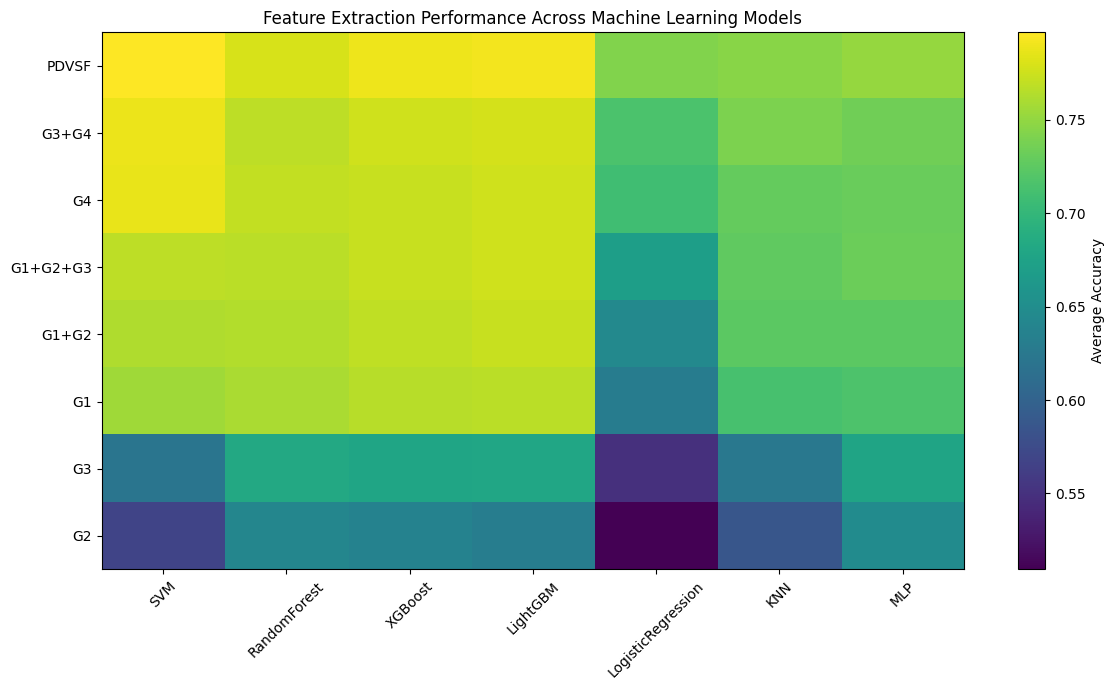

✓ Heatmap Saved


In [188]:
# ==========================================================
# STEP 9.16A : FEATURE COMPARISON HEATMAP
# ==========================================================

import os
import matplotlib.pyplot as plt

plt.figure(figsize=(12,7))

heatmap_data = overall_feature_table.drop(columns=["Average"])

plt.imshow(
    heatmap_data.values,
    aspect="auto"
)

plt.colorbar(label="Average Accuracy")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=45
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("Feature Extraction Performance Across Machine Learning Models")

plt.tight_layout()

plt.savefig(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Feature_Comparison_Heatmap.png"

    ),

    dpi=600

)

plt.show()

print("✓ Heatmap Saved")

In [199]:
# ==========================================================
# STEP 9.16A.1 : PUBLICATION FIGURE SAVE UTILITY
# ==========================================================

import os
import matplotlib.pyplot as plt

FIGURE_FOLDER = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Publication_Figures"
)

os.makedirs(FIGURE_FOLDER, exist_ok=True)

def save_figure(filename):
    """
    Save the current figure using publication-quality settings.
    """

    filepath = os.path.join(FIGURE_FOLDER, filename)

    plt.savefig(
        filepath,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="none"
    )

    print(f"✓ Figure Saved : {filepath}")

    plt.show()

    plt.close()

    return filepath

print("✓ save_figure() Utility Ready")

✓ save_figure() Utility Ready


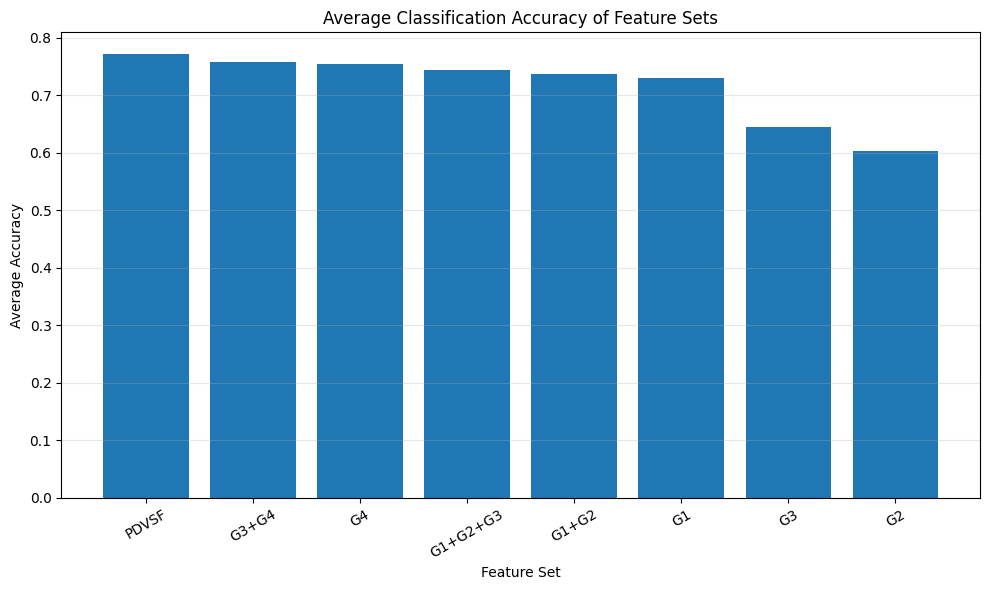

✓ Accuracy Figure Saved


In [190]:
# ==========================================================
# STEP 9.16B : FEATURE ACCURACY BAR CHART
# ==========================================================

import os
import matplotlib.pyplot as plt

# Create fresh data from results
accuracy_plot = (
    results
    .groupby("FeatureSet")["Accuracy_Mean"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

plt.bar(
    accuracy_plot.index,
    accuracy_plot.values
)

plt.ylabel("Average Accuracy")
plt.xlabel("Feature Set")
plt.title("Average Classification Accuracy of Feature Sets")

plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        BASE_OUTPUT,
        "Overall_Results",
        "Feature_Ranking.png"
    ),
    dpi=600
)

plt.show()

print("✓ Accuracy Figure Saved")

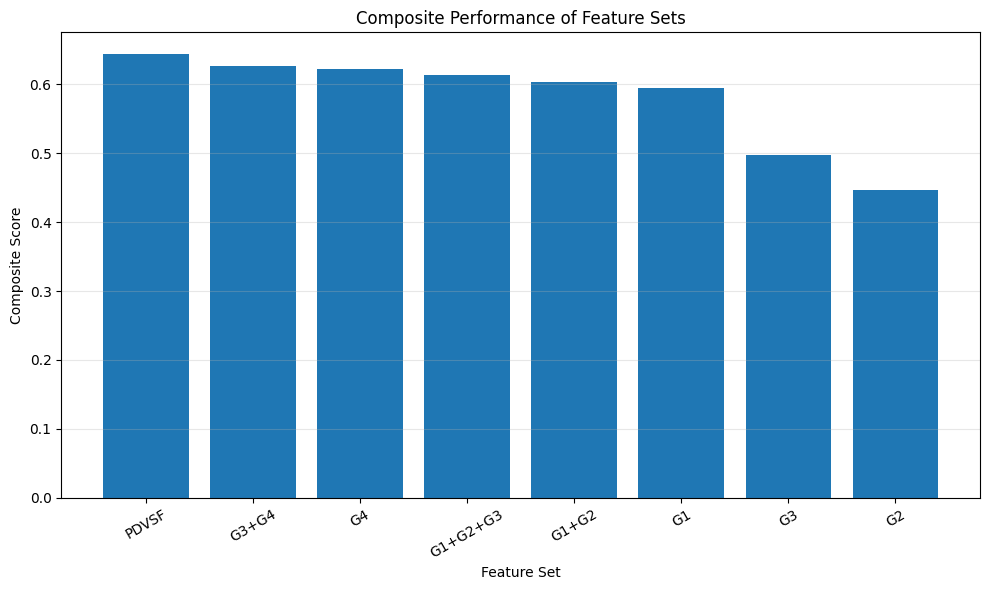

✓ Composite Score Figure Saved


In [191]:
# ==========================================================
# STEP 9.16C : COMPOSITE SCORE BAR CHART
# ==========================================================

import matplotlib.pyplot as plt

composite_plot = (
    feature_summary["CompositeScore"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

plt.bar(
    composite_plot.index,
    composite_plot.values
)

plt.ylabel("Composite Score")
plt.xlabel("Feature Set")
plt.title("Composite Performance of Feature Sets")

plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        BASE_OUTPUT,
        "Overall_Results",
        "Composite_Score.png"
    ),
    dpi=600
)

plt.show()

print("✓ Composite Score Figure Saved")

In [192]:
# ==========================================================
# STEP 9.16A : PUBLICATION PLOT STYLE
# ==========================================================

import matplotlib.pyplot as plt

plt.rcParams.update({

    "figure.figsize": (10,6),

    "figure.dpi": 150,

    "savefig.dpi": 600,

    "font.size": 13,

    "axes.labelsize": 14,

    "axes.titlesize": 15,

    "xtick.labelsize": 12,

    "ytick.labelsize": 12,

    "legend.fontsize": 11,

    "axes.grid": True,

    "grid.alpha": 0.25,

    "lines.linewidth": 2.5

})

print("✓ Publication plotting style loaded")

✓ Publication plotting style loaded


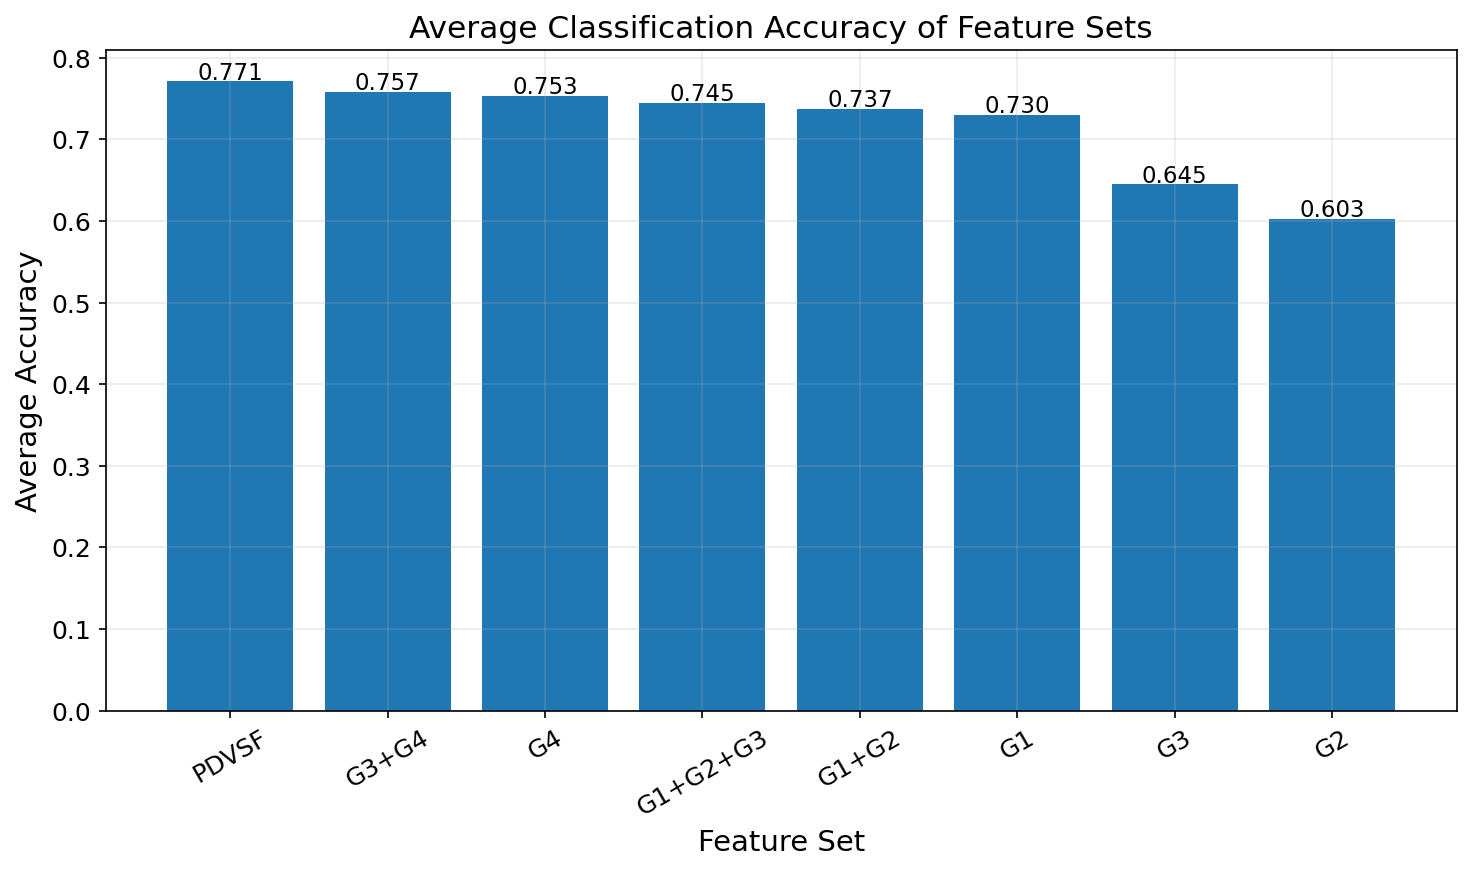

✓ Figure saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Fig2_Accuracy_Ranking.png


<Figure size 1500x900 with 0 Axes>

In [196]:
# ==========================================================
# STEP 9.16B : ACCURACY RANKING
# ==========================================================

accuracy_plot = (

    results

    .groupby("FeatureSet")["Accuracy_Mean"]

    .mean()

    .sort_values(ascending=False)

)

plt.figure()

bars = plt.bar(

    accuracy_plot.index,

    accuracy_plot.values

)

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        height+0.003,

        f"{height:.3f}",

        ha="center",

        fontsize=11

    )

plt.ylabel("Average Accuracy")

plt.xlabel("Feature Set")

plt.title("Average Classification Accuracy of Feature Sets")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Fig2_Accuracy_Ranking.png"

    )

)

plt.show()
# ----------------------------------------------------------
# Save Figure
# ----------------------------------------------------------

figure_path = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Fig2_Accuracy_Ranking.png"
)

os.makedirs(os.path.dirname(figure_path), exist_ok=True)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

print(f"✓ Figure saved : {figure_path}")

plt.show()
plt.close()

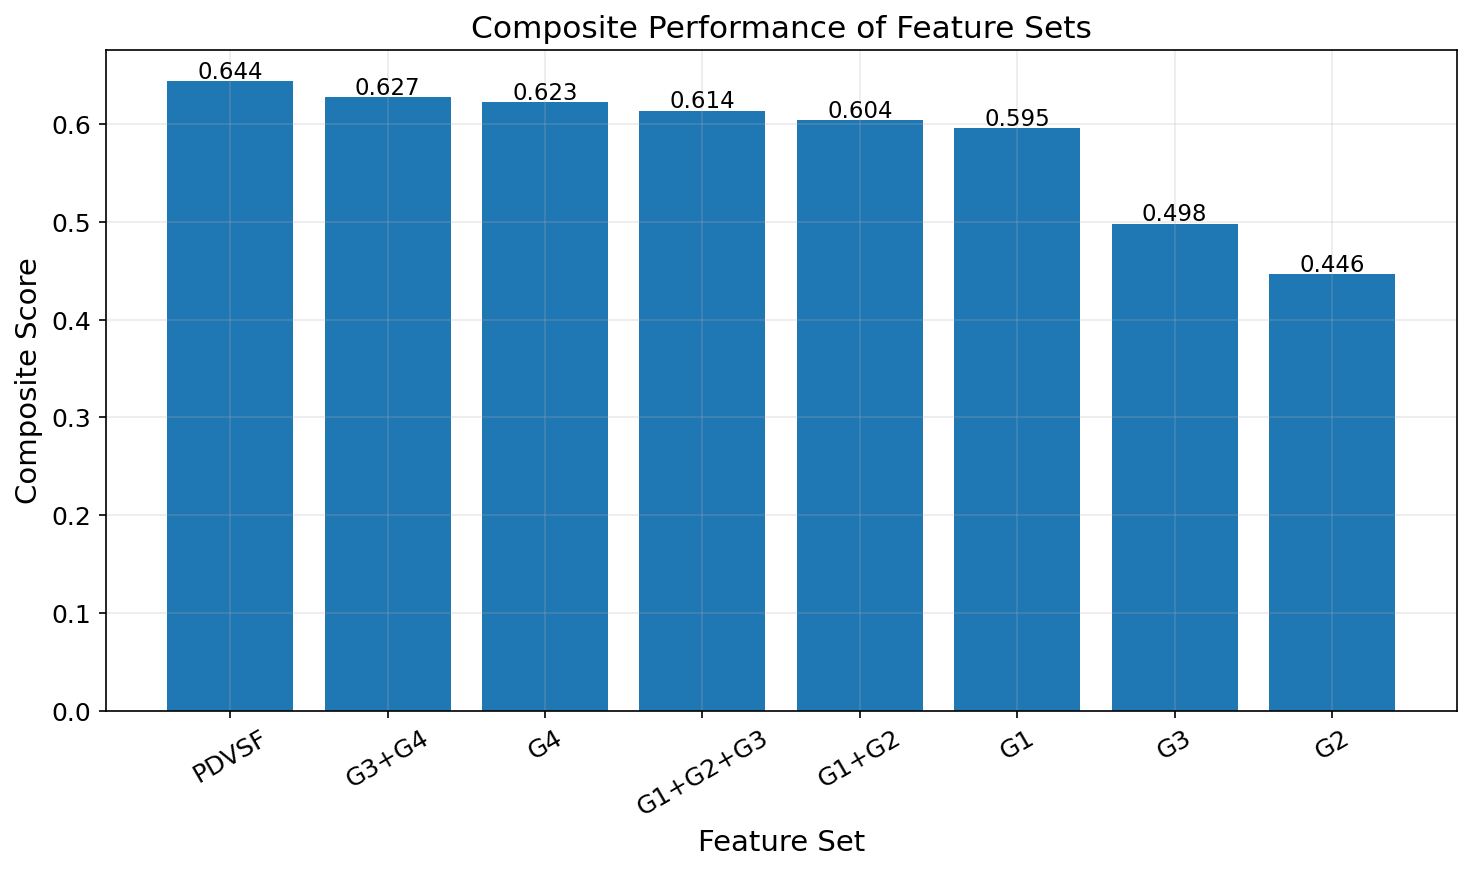

✓ Figure saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Fig3_Composite_Ranking.png


<Figure size 1500x900 with 0 Axes>

In [197]:
# ==========================================================
# STEP 9.16C : COMPOSITE SCORE
# ==========================================================

composite_plot = feature_summary["CompositeScore"].sort_values(

    ascending=False

)

plt.figure()

bars = plt.bar(

    composite_plot.index,

    composite_plot.values

)

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        height+0.003,

        f"{height:.3f}",

        ha="center",

        fontsize=11

    )

plt.ylabel("Composite Score")

plt.xlabel("Feature Set")

plt.title("Composite Performance of Feature Sets")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(

    os.path.join(

        BASE_OUTPUT,

        "Overall_Results",

        "Fig3_Composite_Ranking.png"

    )

)

plt.show()
# ----------------------------------------------------------
# Save Figure
# ----------------------------------------------------------

figure_path = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Fig3_Composite_Ranking.png"
)

os.makedirs(os.path.dirname(figure_path), exist_ok=True)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

print(f"✓ Figure saved : {figure_path}")

plt.show()
plt.close()

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig4_Radar_Comparison.png


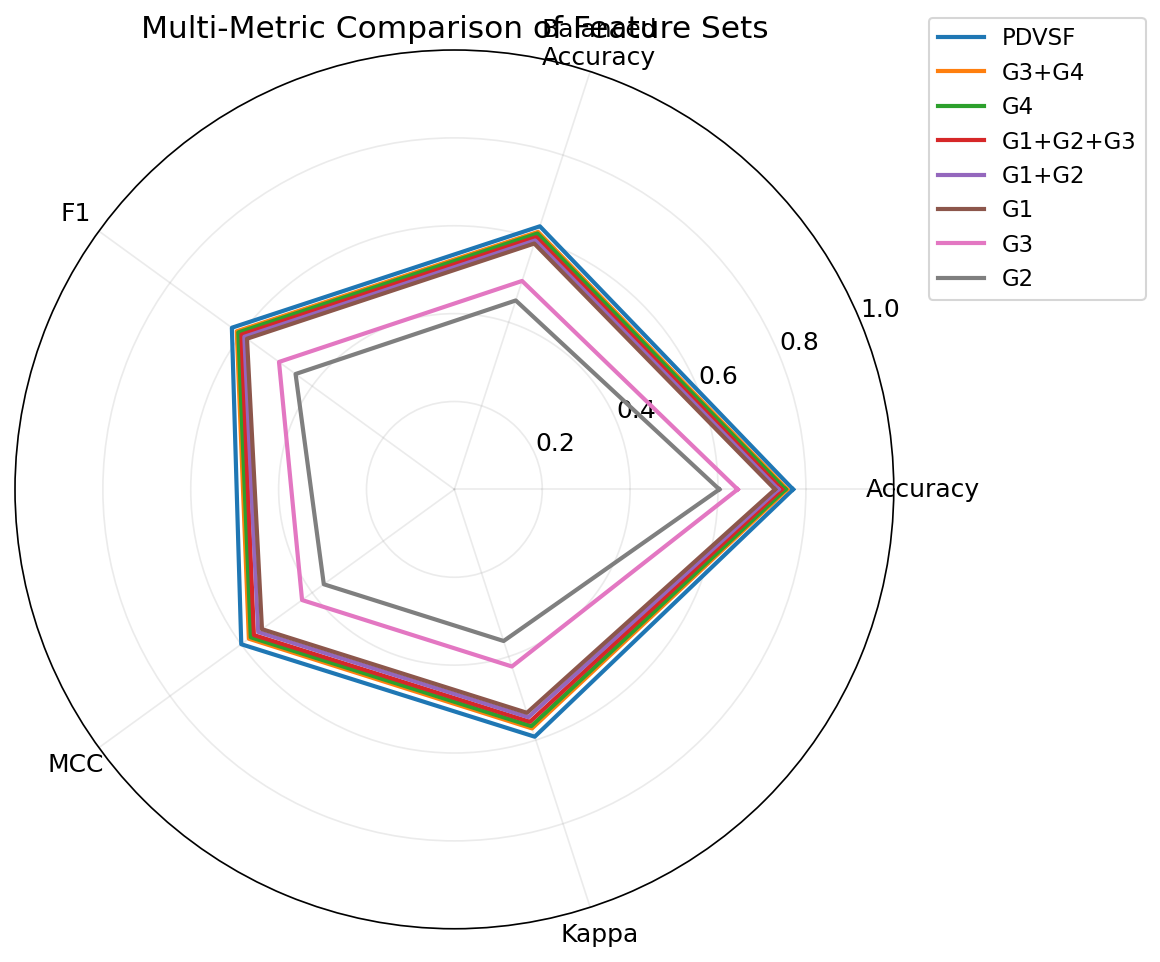

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig4_Radar_Comparison.png'

In [200]:
# ==========================================================
# STEP 9.16D : MULTI-METRIC RADAR CHART
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

metrics = [
    "Accuracy_Mean",
    "BalancedAccuracy_Mean",
    "F1_Mean",
    "MCC_Mean",
    "Kappa_Mean"
]

labels = [
    "Accuracy",
    "Balanced\nAccuracy",
    "F1",
    "MCC",
    "Kappa"
]

feature_order = [
    "PDVSF",
    "G3+G4",
    "G4",
    "G1+G2+G3",
    "G1+G2",
    "G1",
    "G3",
    "G2"
]

angles = np.linspace(
    0,
    2*np.pi,
    len(labels),
    endpoint=False
).tolist()

angles += angles[:1]

plt.figure(figsize=(8,8))

ax = plt.subplot(111, polar=True)

for feature in feature_order:

    values = feature_summary.loc[
        feature,
        metrics
    ].tolist()

    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=feature
    )

ax.set_xticks(angles[:-1])

ax.set_xticklabels(labels)

ax.set_ylim(0,1)

plt.title(
    "Multi-Metric Comparison of Feature Sets",
    fontsize=15
)

plt.legend(
    bbox_to_anchor=(1.30,1.05)
)

plt.tight_layout()

save_figure(
    "Fig4_Radar_Comparison.png"
)

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Ablation_Study.png


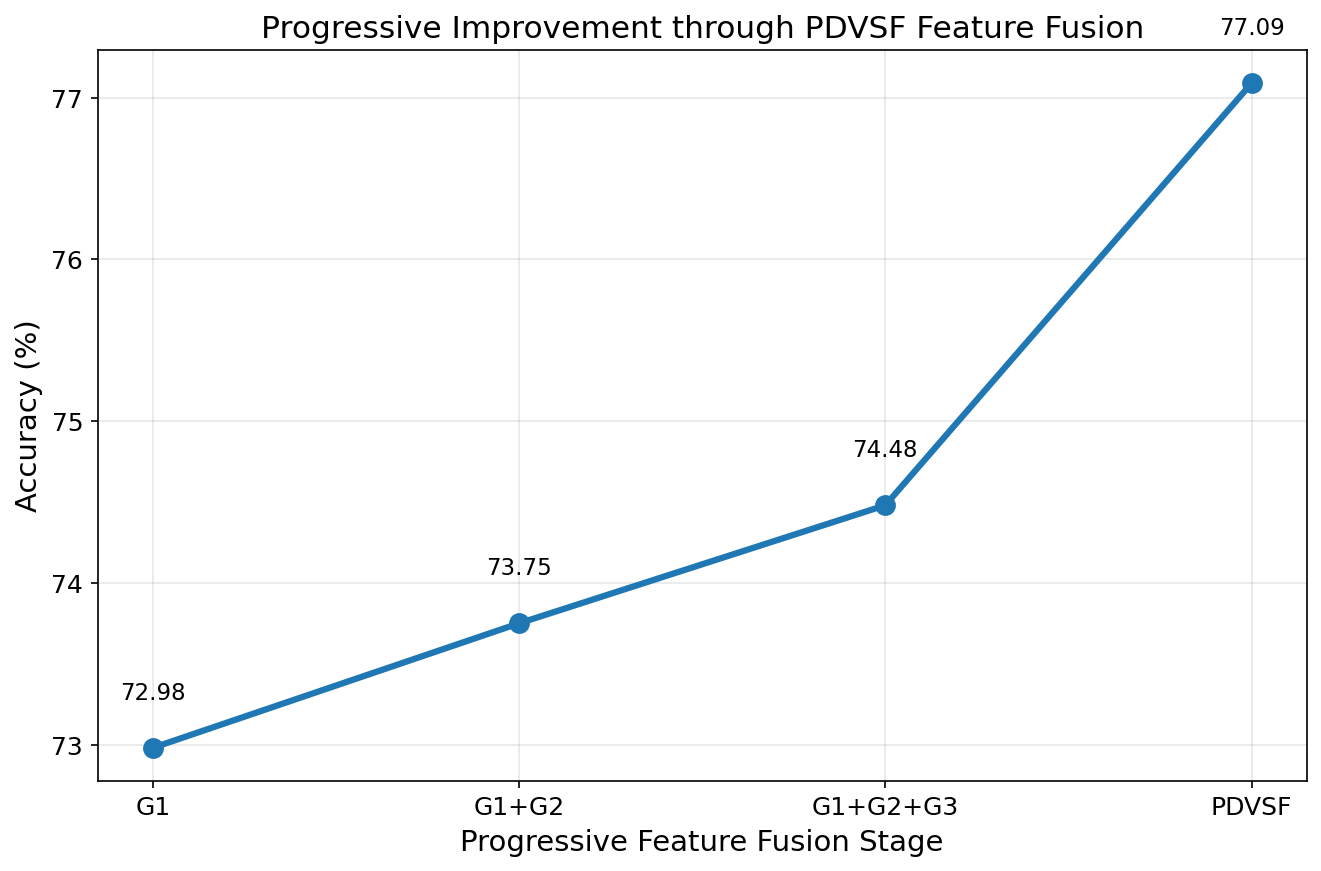

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Ablation_Study.png'

In [202]:
# ==========================================================
# STEP 9.16E : PUBLICATION ABLATION CURVE
# ==========================================================

import os
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Create ablation data directly from feature_summary
# ----------------------------------------------------------

ablation = feature_summary.loc[
    ["G1", "G1+G2", "G1+G2+G3", "PDVSF"]
].copy()

ablation["Accuracy (%)"] = (
    ablation["Accuracy_Mean"] * 100
).round(2)

ablation["Gain (%)"] = (
    ablation["Accuracy (%)"].diff()
).fillna(0)

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

plt.figure(figsize=(9,6))

plt.plot(
    ablation.index,
    ablation["Accuracy (%)"],
    marker="o",
    linewidth=3,
    markersize=9
)

# Annotate values
for i, value in enumerate(ablation["Accuracy (%)"]):
    plt.text(
        i,
        value + 0.3,
        f"{value:.2f}",
        ha="center",
        fontsize=11
    )

plt.grid(alpha=0.3)

plt.xlabel("Progressive Feature Fusion Stage")
plt.ylabel("Accuracy (%)")
plt.title("Progressive Improvement through PDVSF Feature Fusion")

plt.tight_layout()

save_figure("Fig5_Ablation_Study.png")

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig6_Progressive_Gain.png


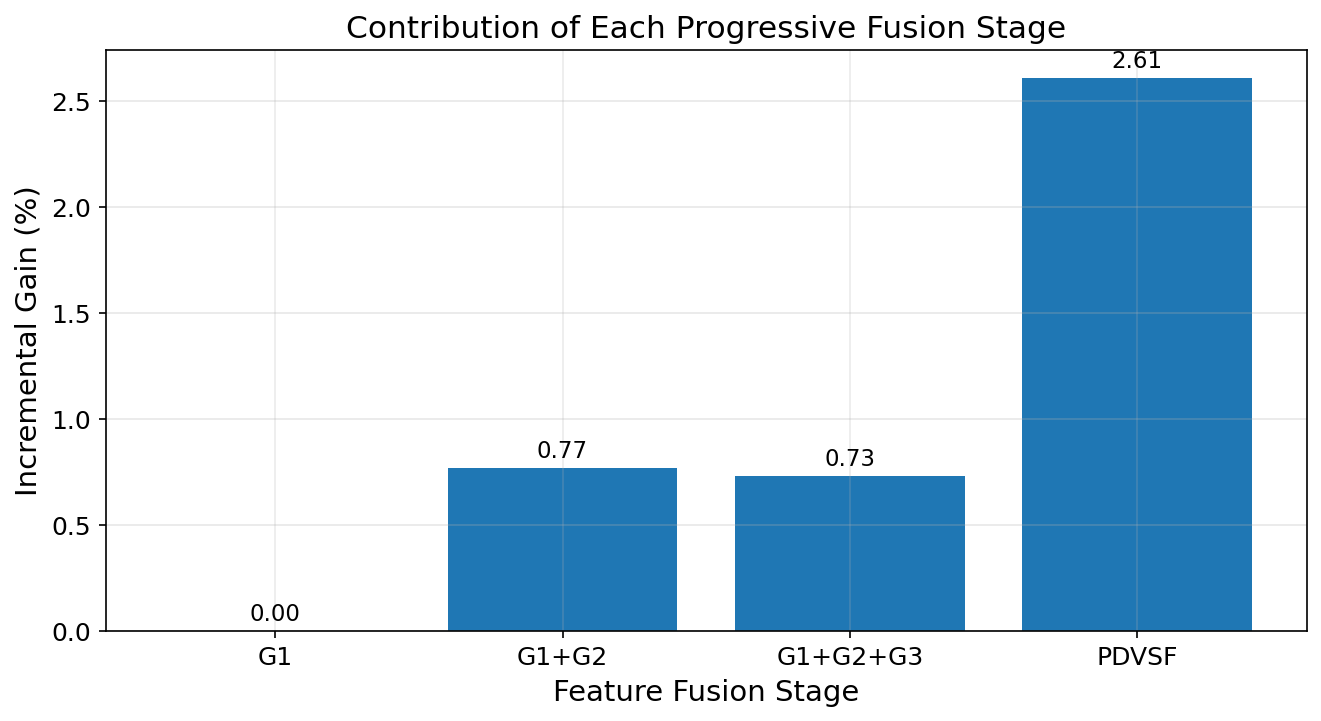

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig6_Progressive_Gain.png'

In [203]:
# ==========================================================
# STEP 9.16F : PROGRESSIVE GAIN
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

bars = plt.bar(
    ablation.index,
    ablation["Gain (%)"]
)

for bar in bars:

    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h+0.05,
        f"{h:.2f}",
        ha="center",
        fontsize=11
    )

plt.ylabel("Incremental Gain (%)")
plt.xlabel("Feature Fusion Stage")
plt.title("Contribution of Each Progressive Fusion Stage")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

save_figure("Fig6_Progressive_Gain.png")

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Feature_Evolution.png


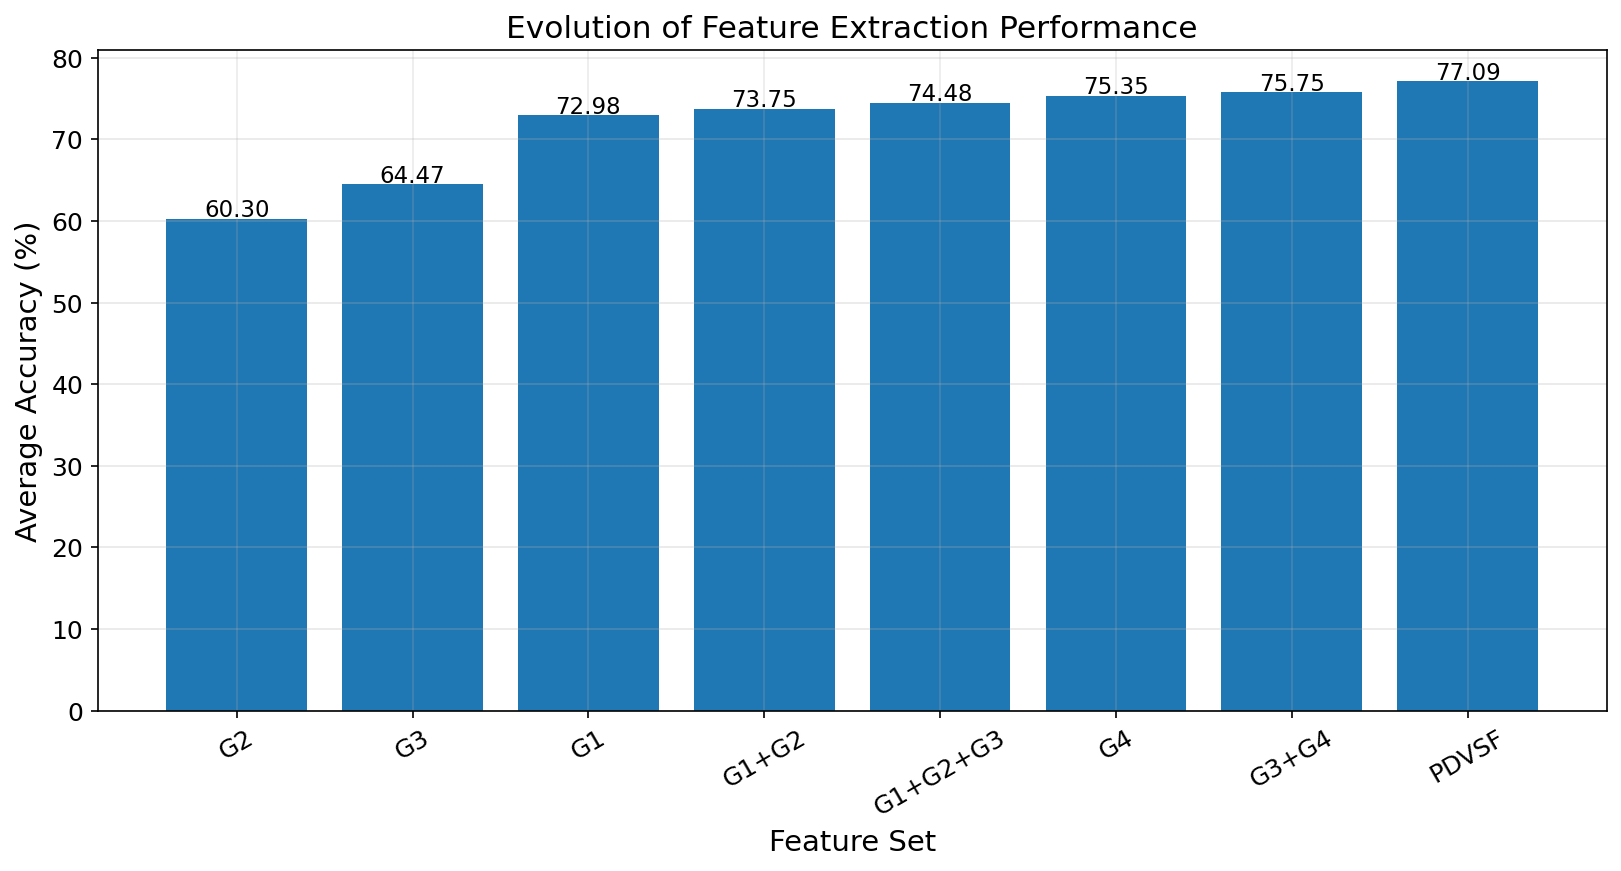

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Feature_Evolution.png'

In [204]:
# ==========================================================
# STEP 9.16G : FEATURE EVOLUTION ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Average Accuracy of Every Feature Set
# ----------------------------------------------------------

feature_evolution = (

    results

    .groupby("FeatureSet")["Accuracy_Mean"]

    .mean()

    .sort_values()

)

plt.figure(figsize=(11,6))

bars = plt.bar(

    feature_evolution.index,

    feature_evolution.values*100

)

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        height+0.25,

        f"{height:.2f}",

        ha="center",

        fontsize=11

    )

plt.xlabel("Feature Set")

plt.ylabel("Average Accuracy (%)")

plt.title("Evolution of Feature Extraction Performance")

plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

save_figure("Fig5_Feature_Evolution.png")

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Feature_Evolution_Curve.png


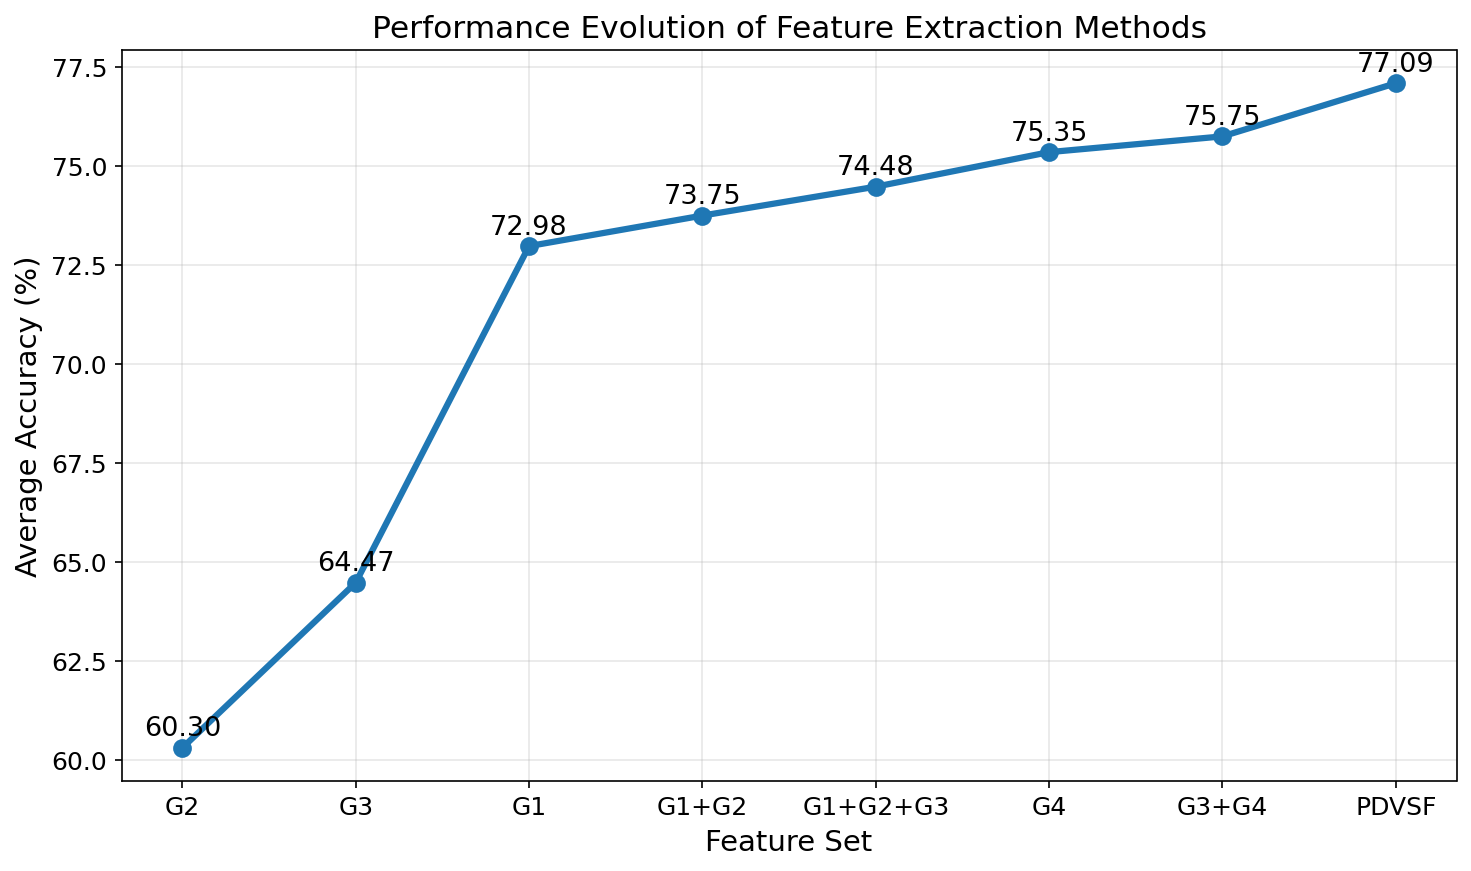

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig5_Feature_Evolution_Curve.png'

In [205]:
# ==========================================================
# STEP 9.16H : FEATURE EVOLUTION CURVE
# ==========================================================

plt.figure(figsize=(10,6))

plt.plot(

    feature_evolution.index,

    feature_evolution.values*100,

    marker="o",

    linewidth=3,

    markersize=8

)

for i,v in enumerate(feature_evolution.values*100):

    plt.text(

        i,

        v+0.3,

        f"{v:.2f}",

        ha="center"

    )

plt.xlabel("Feature Set")

plt.ylabel("Average Accuracy (%)")

plt.title("Performance Evolution of Feature Extraction Methods")

plt.grid(alpha=0.3)

plt.tight_layout()

save_figure("Fig5_Feature_Evolution_Curve.png")

In [206]:
# ==========================================================
# STEP 9.17A : BEST PDVSF CLASSIFIER
# ==========================================================

import pandas as pd

pdvsf_results = results[
    results["FeatureSet"] == "PDVSF"
]

summary = (
    pdvsf_results
    .groupby("Model")
    .agg({
        "Accuracy_Mean":"mean",
        "BalancedAccuracy_Mean":"mean",
        "F1_Mean":"mean",
        "MCC_Mean":"mean",
        "Kappa_Mean":"mean"
    })
)

summary["Composite"] = summary.mean(axis=1)

summary = summary.sort_values(
    by="Composite",
    ascending=False
)

display(summary)

best_model = summary.index[0]

print("\nBest Overall Classifier :", best_model)

,Accuracy_Mean,BalancedAccuracy_Mean,F1_Mean,MCC_Mean,Kappa_Mean,Composite
Model,,,,,,
MLP,0.751747,0.647384,0.647154,0.621982,0.621649,0.657983
LightGBM,0.791316,0.639439,0.635050,0.617935,0.604987,0.657745
XGBoost,0.789912,0.637976,0.633860,0.616760,0.603241,0.656350
SVM,0.796864,0.642295,0.635450,0.604343,0.597931,0.655377
RandomForest,0.778974,0.625258,0.618762,0.579439,0.573257,0.635138
KNN,0.745325,0.620337,0.618611,0.583929,0.580904,0.629821
LogisticRegression,0.742138,0.594665,0.592830,0.572454,0.560971,0.612612



Best Overall Classifier : MLP


In [209]:
# ==========================================================
# SAVE BEST PDVSF CLASSIFIER
# ==========================================================


TABLE_FOLDER = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Tables"
)

os.makedirs(TABLE_FOLDER, exist_ok=True)

summary.to_csv(
    os.path.join(
        TABLE_FOLDER,
        "Best_PDVSF_Classifier.csv"
    )
)
print(summary)
print("✓ Best PDVSF Classifier Table Saved")

                    Accuracy_Mean  BalancedAccuracy_Mean   F1_Mean  MCC_Mean  \
Model                                                                          
MLP                      0.751747               0.647384  0.647154  0.621982   
LightGBM                 0.791316               0.639439  0.635050  0.617935   
XGBoost                  0.789912               0.637976  0.633860  0.616760   
SVM                      0.796864               0.642295  0.635450  0.604343   
RandomForest             0.778974               0.625258  0.618762  0.579439   
KNN                      0.745325               0.620337  0.618611  0.583929   
LogisticRegression       0.742138               0.594665  0.592830  0.572454   

                    Kappa_Mean  Composite  
Model                                      
MLP                   0.621649   0.657983  
LightGBM              0.604987   0.657745  
XGBoost               0.603241   0.656350  
SVM                   0.597931   0.655377  
RandomForest   

In [207]:
# ==========================================================
# STEP 9.17B : VERIFY SAVED MODELS
# ==========================================================

import os

for dataset_name, dataset_path in DATASETS.items():

    model_folder = os.path.join(
        dataset_path,
        "Final_Results",
        "Models"
    )

    print("\n" + "="*60)
    print(dataset_name)
    print("="*60)

    if not os.path.exists(model_folder):
        print("❌ Model folder not found")
        continue

    models = sorted(os.listdir(model_folder))

    print(f"Total Saved Models : {len(models)}")

    for m in models[:10]:
        print("✓", m)

    if len(models) > 10:
        print("...")


Dataset1
Total Saved Models : 56
✓ G1+G2+G3_KNN.joblib
✓ G1+G2+G3_LightGBM.joblib
✓ G1+G2+G3_LogisticRegression.joblib
✓ G1+G2+G3_MLP.joblib
✓ G1+G2+G3_RandomForest.joblib
✓ G1+G2+G3_SVM.joblib
✓ G1+G2+G3_XGBoost.joblib
✓ G1+G2_KNN.joblib
✓ G1+G2_LightGBM.joblib
✓ G1+G2_LogisticRegression.joblib
...

Dataset2
Total Saved Models : 56
✓ G1+G2+G3_KNN.joblib
✓ G1+G2+G3_LightGBM.joblib
✓ G1+G2+G3_LogisticRegression.joblib
✓ G1+G2+G3_MLP.joblib
✓ G1+G2+G3_RandomForest.joblib
✓ G1+G2+G3_SVM.joblib
✓ G1+G2+G3_XGBoost.joblib
✓ G1+G2_KNN.joblib
✓ G1+G2_LightGBM.joblib
✓ G1+G2_LogisticRegression.joblib
...

Dataset3
Total Saved Models : 56
✓ G1+G2+G3_KNN.joblib
✓ G1+G2+G3_LightGBM.joblib
✓ G1+G2+G3_LogisticRegression.joblib
✓ G1+G2+G3_MLP.joblib
✓ G1+G2+G3_RandomForest.joblib
✓ G1+G2+G3_SVM.joblib
✓ G1+G2+G3_XGBoost.joblib
✓ G1+G2_KNN.joblib
✓ G1+G2_LightGBM.joblib
✓ G1+G2_LogisticRegression.joblib
...


In [210]:
# ==========================================================
# STEP 9.17A : GENERATE OOF PREDICTIONS (PDVSF + MLP)
# ==========================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

CV = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

PREDICTION_FOLDER = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Prediction_Archive"
)

os.makedirs(PREDICTION_FOLDER, exist_ok=True)

In [211]:
# ==========================================================
# STEP 9.17B : CREATE OUT-OF-FOLD PREDICTIONS
# ==========================================================

def generate_oof_predictions(
    X,
    y,
    model
):

    oof_true = []
    oof_pred = []
    oof_prob = []
    fold_no = []

    for fold, (train_idx, test_idx) in enumerate(CV.split(X, y), start=1):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        clf = clone(model)

        clf.fit(X_train, y_train)

        pred = clf.predict(X_test)

        oof_true.extend(y_test)
        oof_pred.extend(pred)
        fold_no.extend([fold] * len(test_idx))

        # Save probabilities if available
        if hasattr(clf, "predict_proba"):
            prob = clf.predict_proba(X_test)
            oof_prob.append(prob)

    if len(oof_prob) > 0:
        oof_prob = np.vstack(oof_prob)
    else:
        oof_prob = None

    return (
        np.array(oof_true),
        np.array(oof_pred),
        oof_prob,
        np.array(fold_no)
    )

In [212]:
# ==========================================================
# STEP 9.17C : GENERATE PREDICTION ARCHIVE
# ==========================================================

prediction_summary = []

for dataset_name, dataset_path in DATASETS.items():

    print("\n" + "="*70)
    print(dataset_name)
    print("="*70)

    # Load feature groups
    features, encoder = load_feature_groups(dataset_path)
    feature_sets, y = build_feature_sets(features)

    # Use PDVSF only
    X = feature_sets["PDVSF"]

    # Use the selected classifier (MLP)
    model = MODELS["MLP"]

    y_true, y_pred, y_prob, fold = generate_oof_predictions(
        X,
        y,
        model
    )

    pred_df = pd.DataFrame({
        "True_Label": y_true,
        "Predicted_Label": y_pred,
        "Fold": fold
    })

    if y_prob is not None:
        for i in range(y_prob.shape[1]):
            pred_df[f"Prob_Class_{i}"] = y_prob[:, i]

    file_path = os.path.join(
        PREDICTION_FOLDER,
        f"{dataset_name}_PDVSF_MLP_Predictions.csv"
    )

    pred_df.to_csv(file_path, index=False)

    cm = confusion_matrix(y_true, y_pred)

    prediction_summary.append({
        "Dataset": dataset_name,
        "Samples": len(y_true),
        "Prediction_File": os.path.basename(file_path)
    })

    print(f"✓ Predictions saved : {file_path}")
    print(f"✓ Samples : {len(y_true)}")

prediction_summary = pd.DataFrame(prediction_summary)

display(prediction_summary)

prediction_summary.to_csv(
    os.path.join(
        TABLE_FOLDER,
        "Prediction_Archive_Summary.csv"
    ),
    index=False
)

print("\n✓ Prediction Archive Completed")


Dataset1
✓ Predictions saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Prediction_Archive/Dataset1_PDVSF_MLP_Predictions.csv
✓ Samples : 6743

Dataset2
✓ Predictions saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Prediction_Archive/Dataset2_PDVSF_MLP_Predictions.csv
✓ Samples : 3475

Dataset3
✓ Predictions saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Prediction_Archive/Dataset3_PDVSF_MLP_Predictions.csv
✓ Samples : 14991


,Dataset,Samples,Prediction_File
0,Dataset1,6743,Dataset1_PDVSF_MLP_Predictions.csv
1,Dataset2,3475,Dataset2_PDVSF_MLP_Predictions.csv
2,Dataset3,14991,Dataset3_PDVSF_MLP_Predictions.csv



✓ Prediction Archive Completed



Dataset1
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Confusion_Matrices/Dataset1_ConfusionMatrix.png


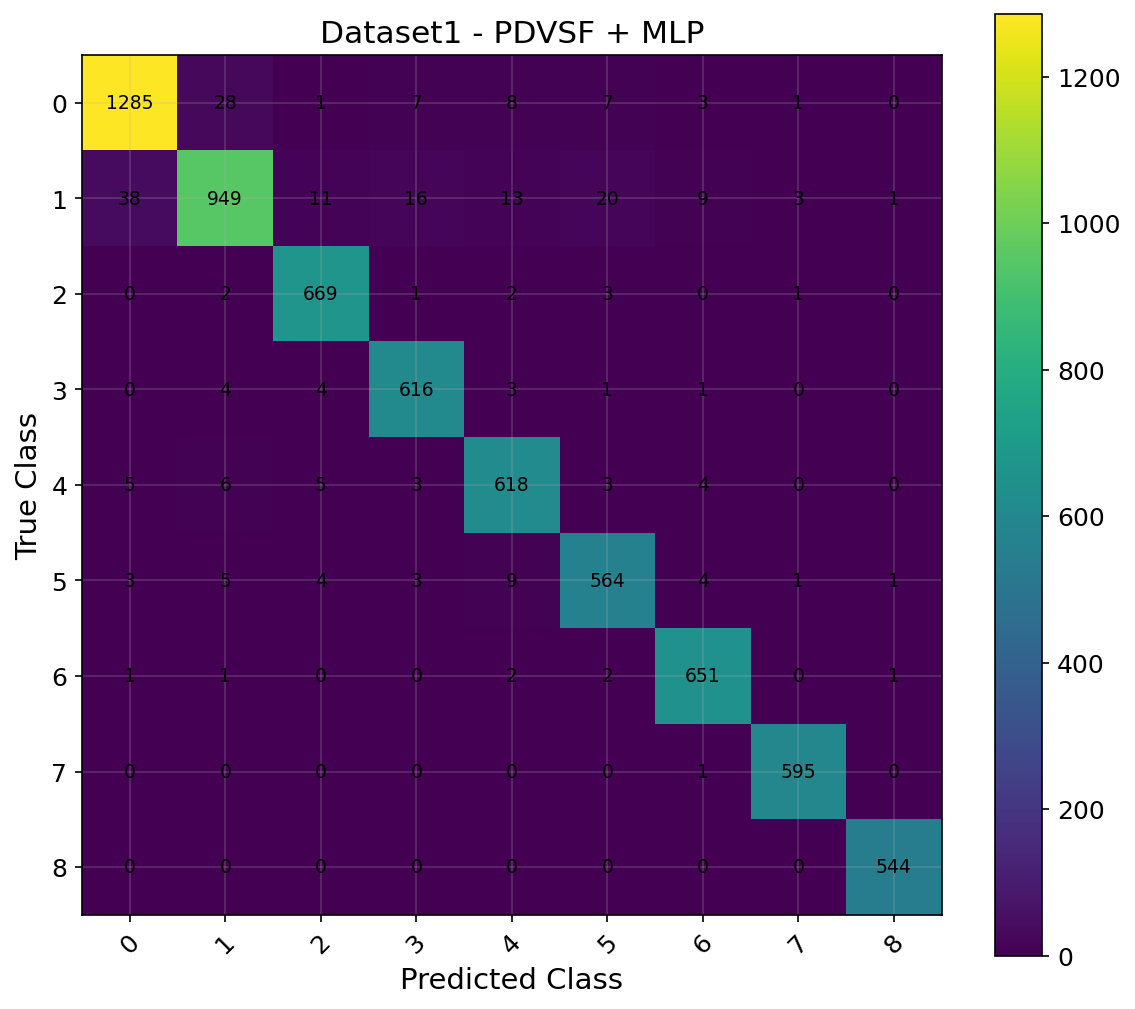


Dataset2
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Confusion_Matrices/Dataset2_ConfusionMatrix.png


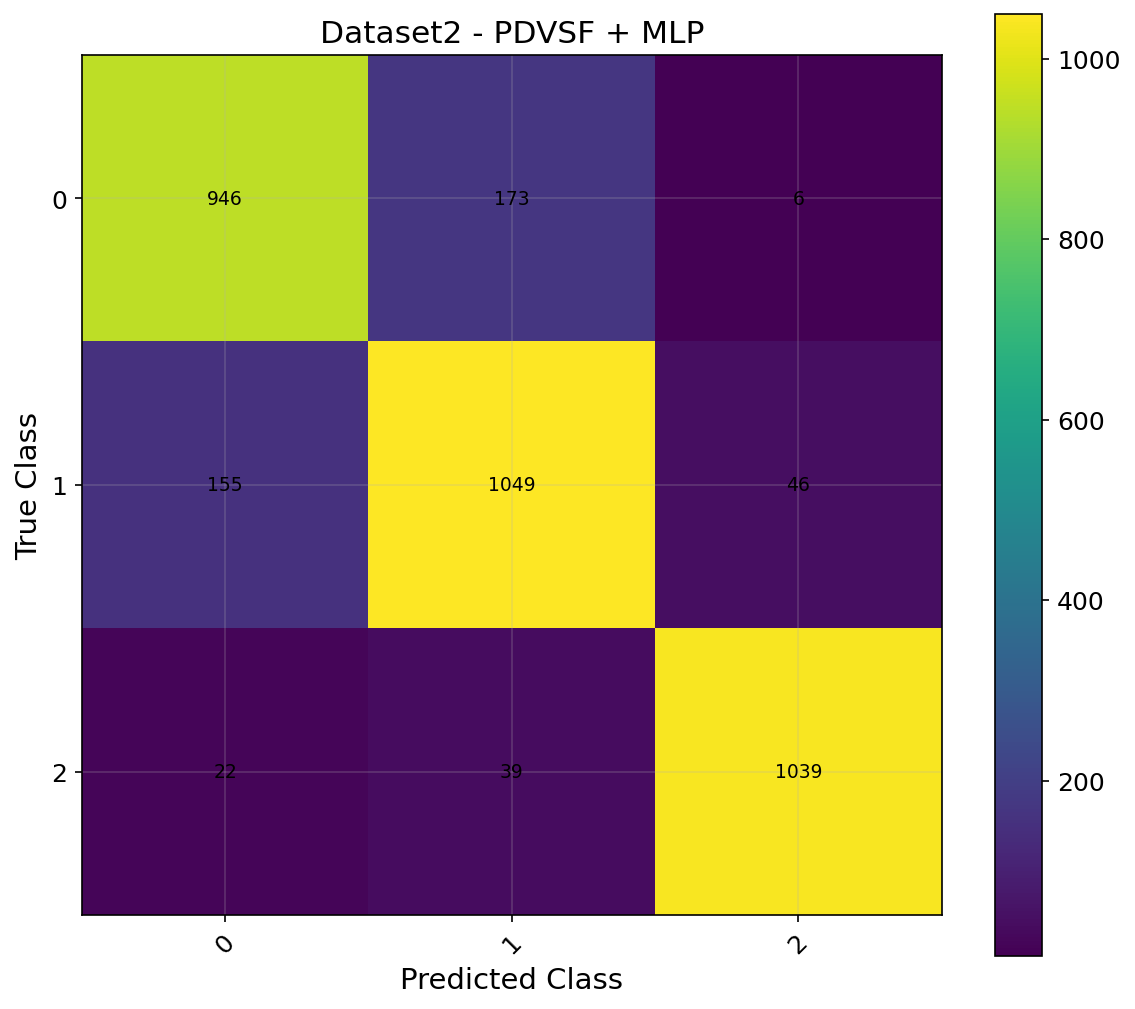


Dataset3
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Confusion_Matrices/Dataset3_ConfusionMatrix.png


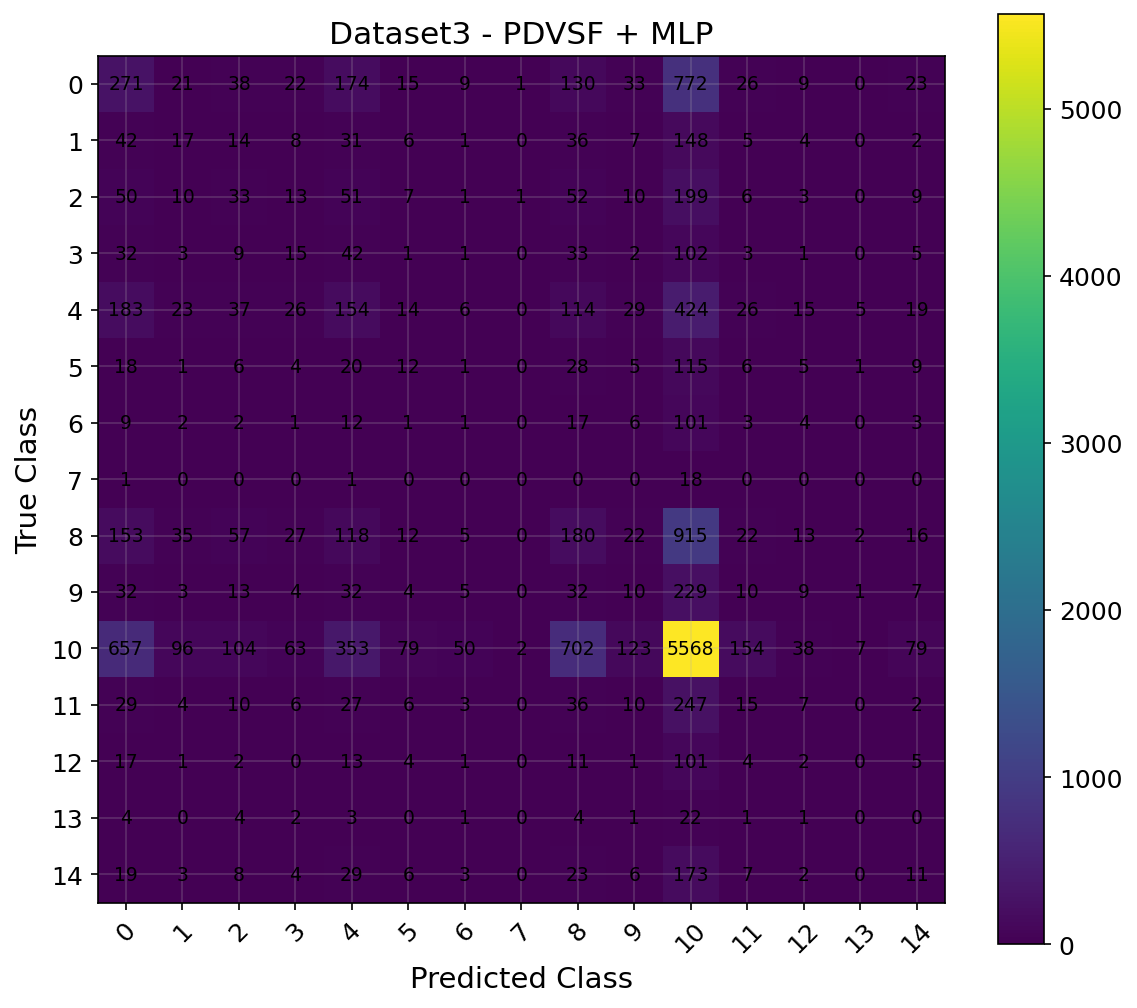


✓ Publication Confusion Matrices Generated


In [214]:
# ==========================================================
# STEP 9.18A : PUBLICATION CONFUSION MATRICES
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

CM_FOLDER = os.path.join(
    FIGURE_FOLDER,
    "Confusion_Matrices"
)

os.makedirs(CM_FOLDER, exist_ok=True)

TABLE_FOLDER = os.path.join(
    BASE_OUTPUT,
    "Overall_Results",
    "Tables"
)

os.makedirs(TABLE_FOLDER, exist_ok=True)

for dataset in DATASETS.keys():

    print("\n" + "="*70)
    print(dataset)
    print("="*70)

    pred_file = os.path.join(
        PREDICTION_FOLDER,
        f"{dataset}_PDVSF_MLP_Predictions.csv"
    )

    pred = pd.read_csv(pred_file)

    y_true = pred["True_Label"]
    y_pred = pred["Predicted_Label"]

    labels = np.unique(y_true)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    # ----------------------------------------
    # Save confusion matrix values
    # ----------------------------------------

    cm_df = pd.DataFrame(
        cm,
        index=labels,
        columns=labels
    )

    cm_df.to_csv(
        os.path.join(
            TABLE_FOLDER,
            f"{dataset}_ConfusionMatrix.csv"
        )
    )

    # ----------------------------------------
    # Plot
    # ----------------------------------------

    fig, ax = plt.subplots(figsize=(8,7))

    image = ax.imshow(cm)

    plt.colorbar(image)

    ax.set_title(
        f"{dataset} - PDVSF + MLP"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)

    # Write values inside cells
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                str(cm[i,j]),
                ha="center",
                va="center",
                fontsize=9
            )

    plt.tight_layout()

    save_figure(
        f"Confusion_Matrices/{dataset}_ConfusionMatrix.png"
    )

print("\n✓ Publication Confusion Matrices Generated")

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Normalized_Confusion_Matrices/Dataset1_Normalized_CM.png


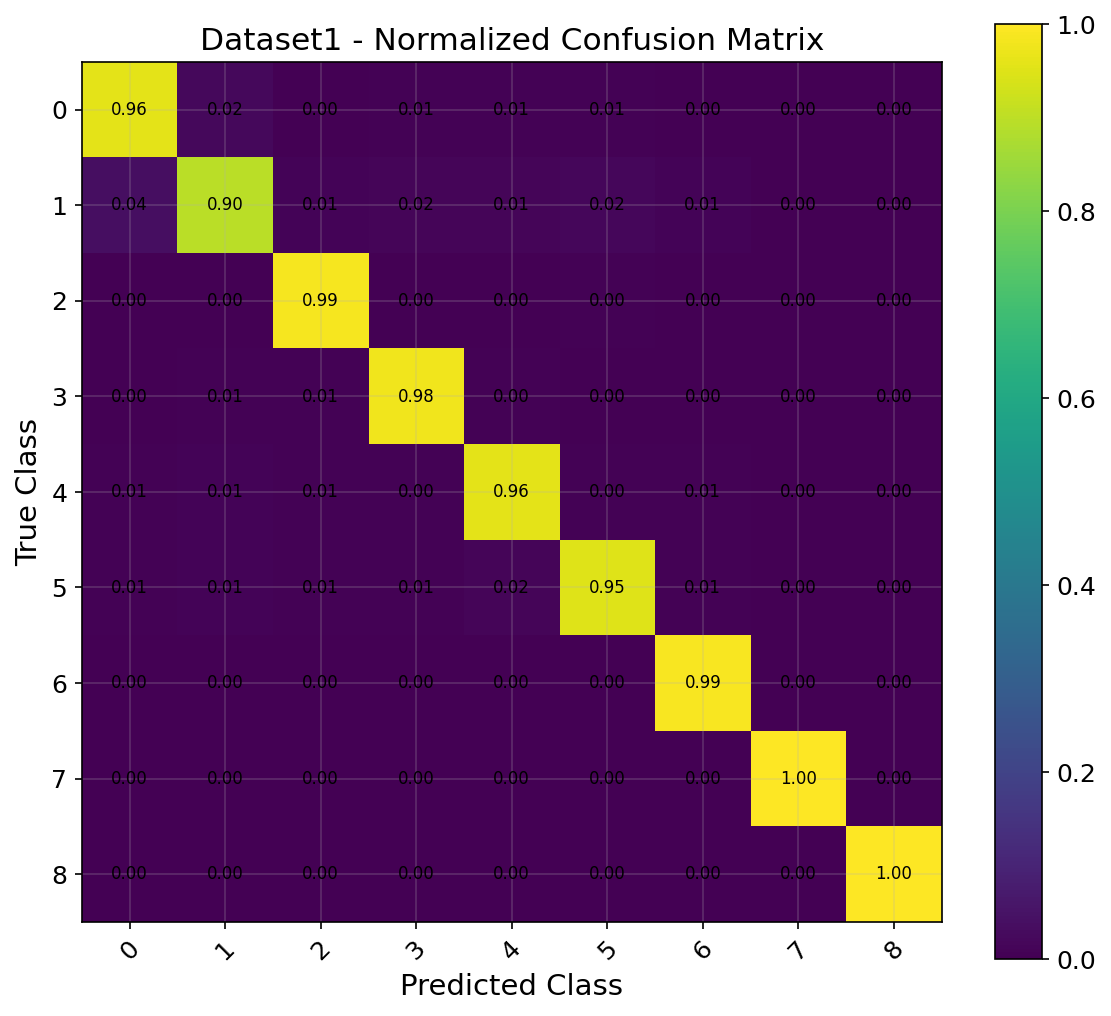

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Normalized_Confusion_Matrices/Dataset2_Normalized_CM.png


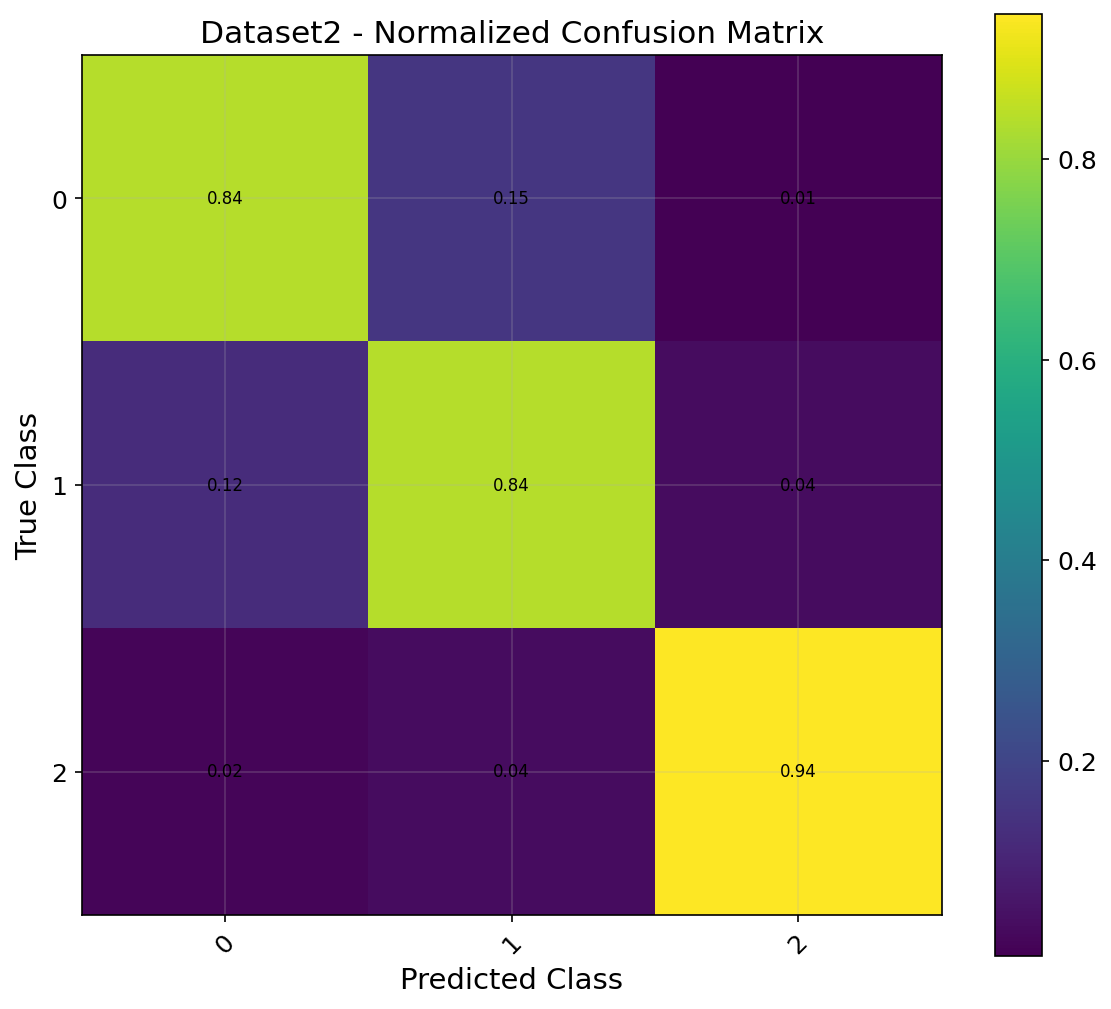

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Normalized_Confusion_Matrices/Dataset3_Normalized_CM.png


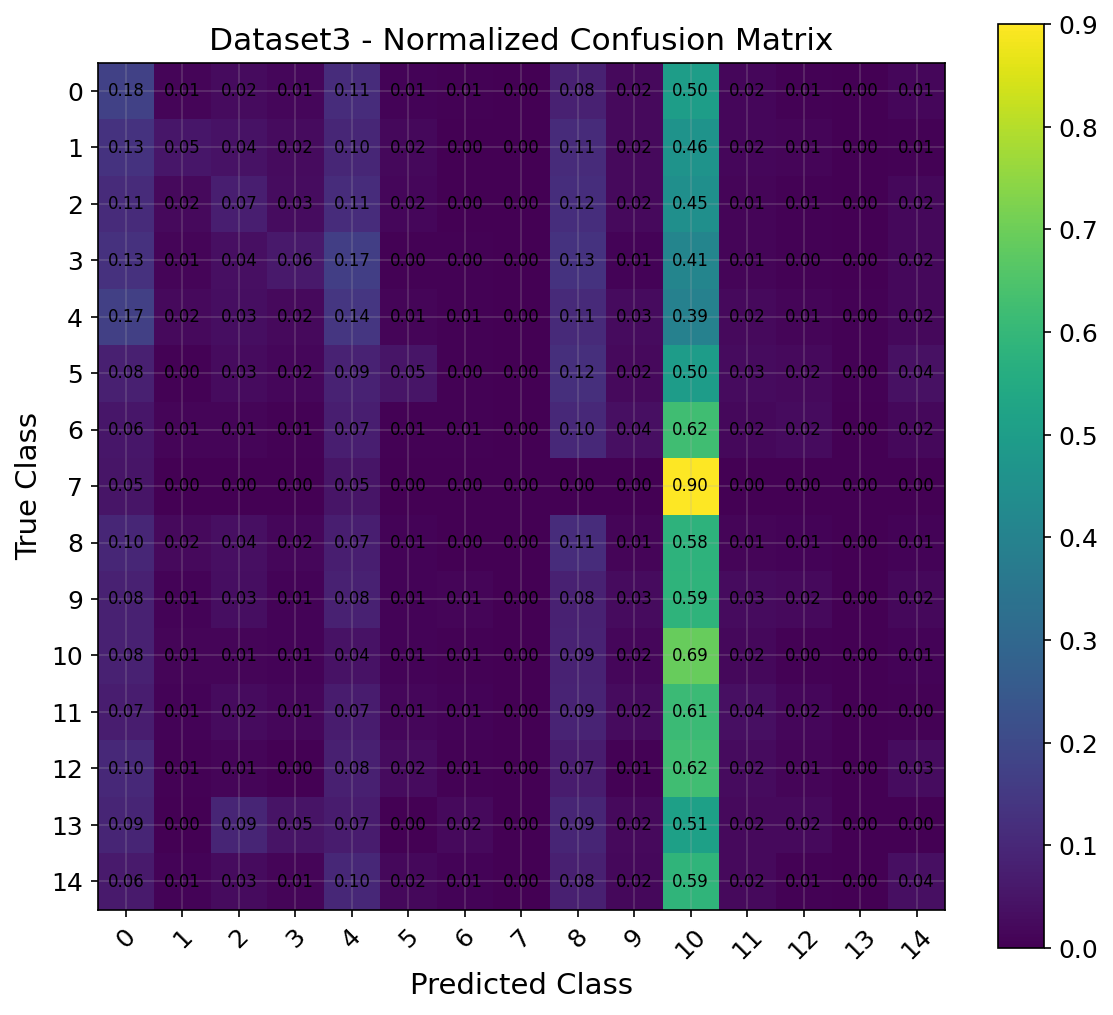


✓ Normalized Confusion Matrices Generated


In [215]:
# ==========================================================
# STEP 9.18B : NORMALIZED CONFUSION MATRICES
# ==========================================================

from sklearn.metrics import confusion_matrix

NCM_FOLDER = os.path.join(
    FIGURE_FOLDER,
    "Normalized_Confusion_Matrices"
)

os.makedirs(NCM_FOLDER, exist_ok=True)

for dataset in DATASETS.keys():

    pred = pd.read_csv(
        os.path.join(
            PREDICTION_FOLDER,
            f"{dataset}_PDVSF_MLP_Predictions.csv"
        )
    )

    labels = np.unique(pred["True_Label"])

    cm = confusion_matrix(
        pred["True_Label"],
        pred["Predicted_Label"],
        labels=labels,
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(8,7))

    image = ax.imshow(cm)

    plt.colorbar(image)

    ax.set_title(
        f"{dataset} - Normalized Confusion Matrix"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                f"{cm[i,j]:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

    plt.tight_layout()

    save_figure(
        f"Normalized_Confusion_Matrices/{dataset}_Normalized_CM.png"
    )

print("\n✓ Normalized Confusion Matrices Generated")

In [216]:
pred = pd.read_csv(
    os.path.join(
        PREDICTION_FOLDER,
        "Dataset1_PDVSF_MLP_Predictions.csv"
    )
)

print(pred.columns.tolist())

['True_Label', 'Predicted_Label', 'Fold', 'Prob_Class_0', 'Prob_Class_1', 'Prob_Class_2', 'Prob_Class_3', 'Prob_Class_4', 'Prob_Class_5', 'Prob_Class_6', 'Prob_Class_7', 'Prob_Class_8']


In [217]:
print(pred.columns.tolist())

['True_Label', 'Predicted_Label', 'Fold', 'Prob_Class_0', 'Prob_Class_1', 'Prob_Class_2', 'Prob_Class_3', 'Prob_Class_4', 'Prob_Class_5', 'Prob_Class_6', 'Prob_Class_7', 'Prob_Class_8']



Dataset1
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/ROC_Curves/Dataset1_ROC.png


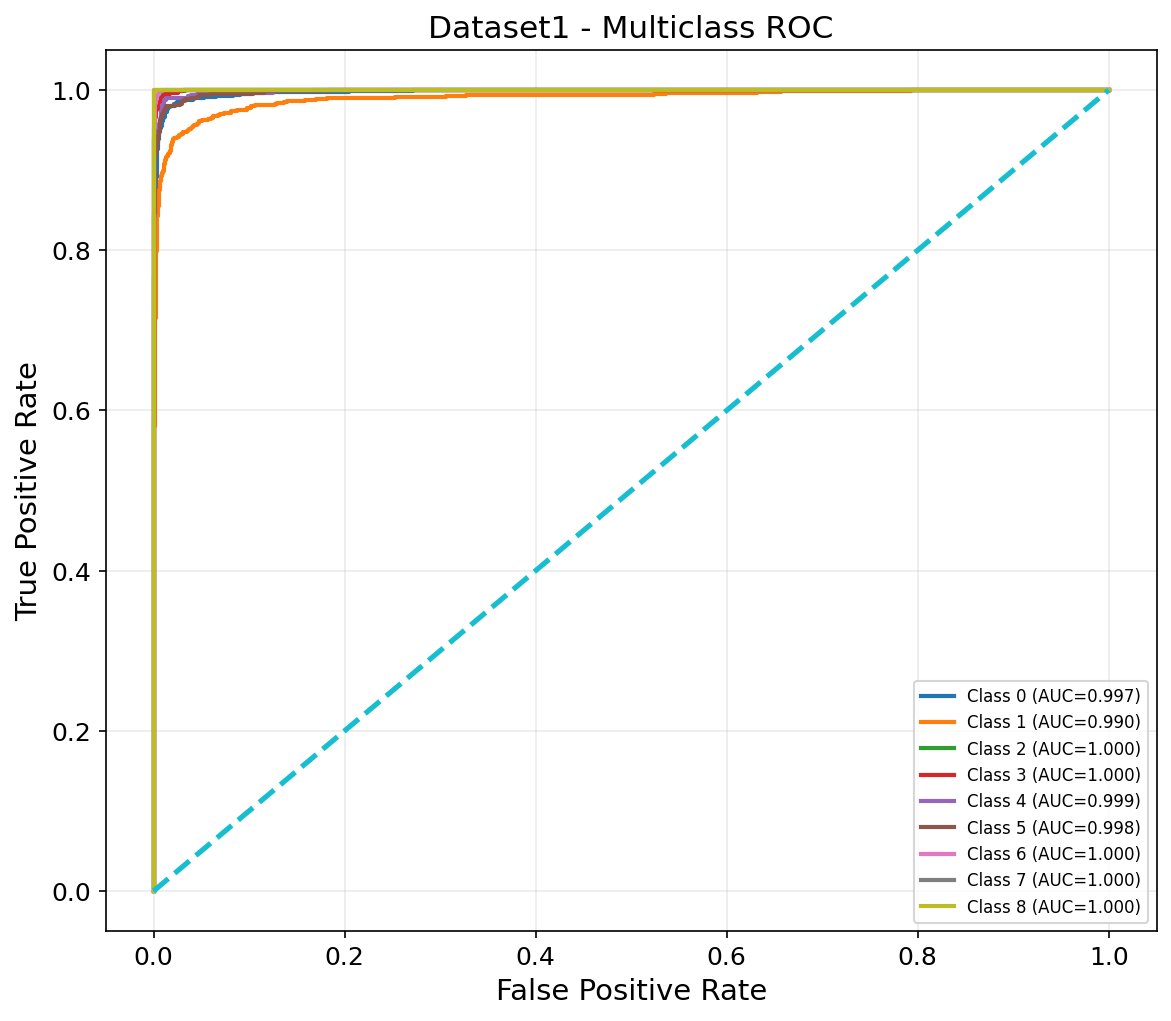


Dataset2
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/ROC_Curves/Dataset2_ROC.png


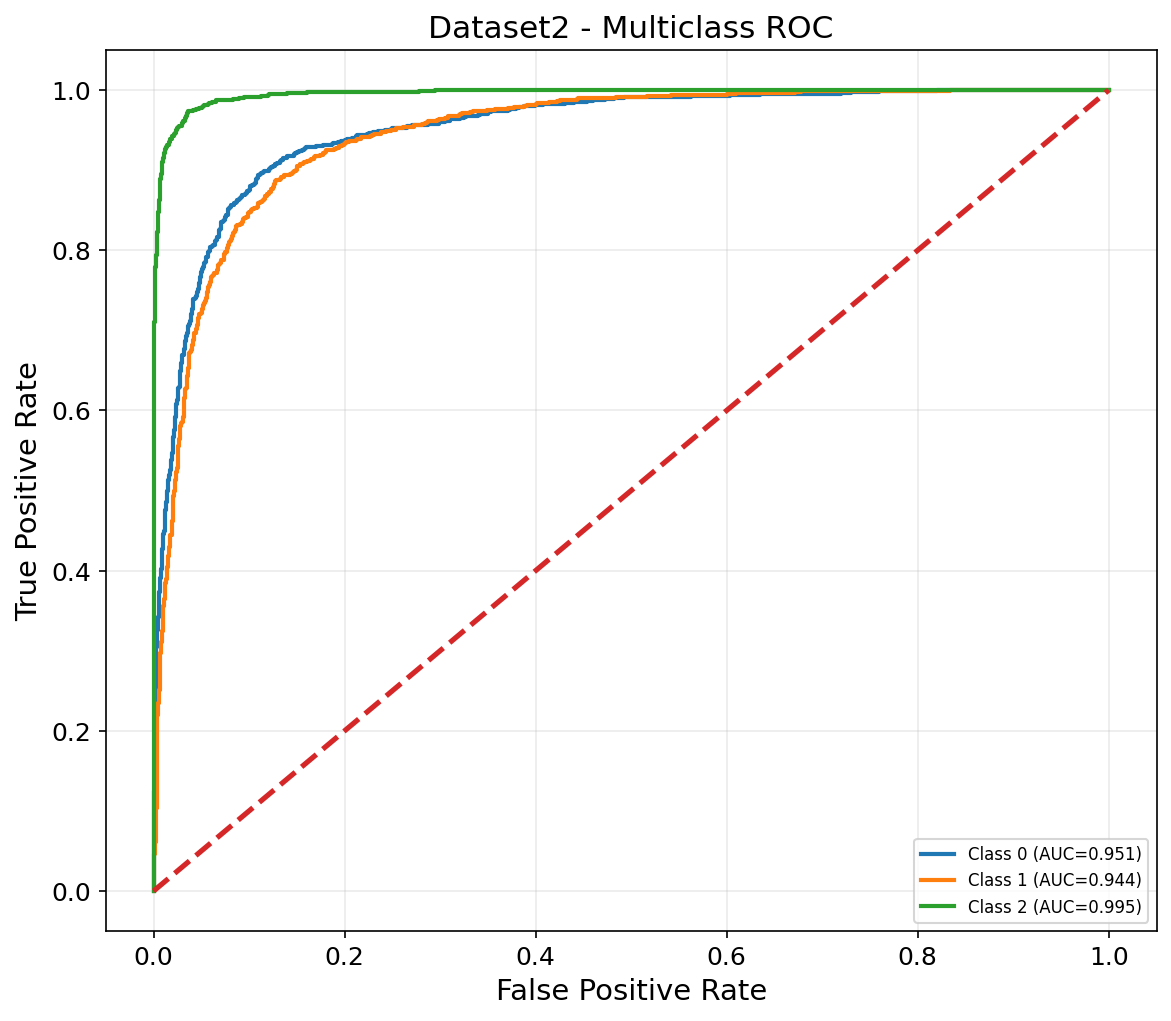


Dataset3
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/ROC_Curves/Dataset3_ROC.png


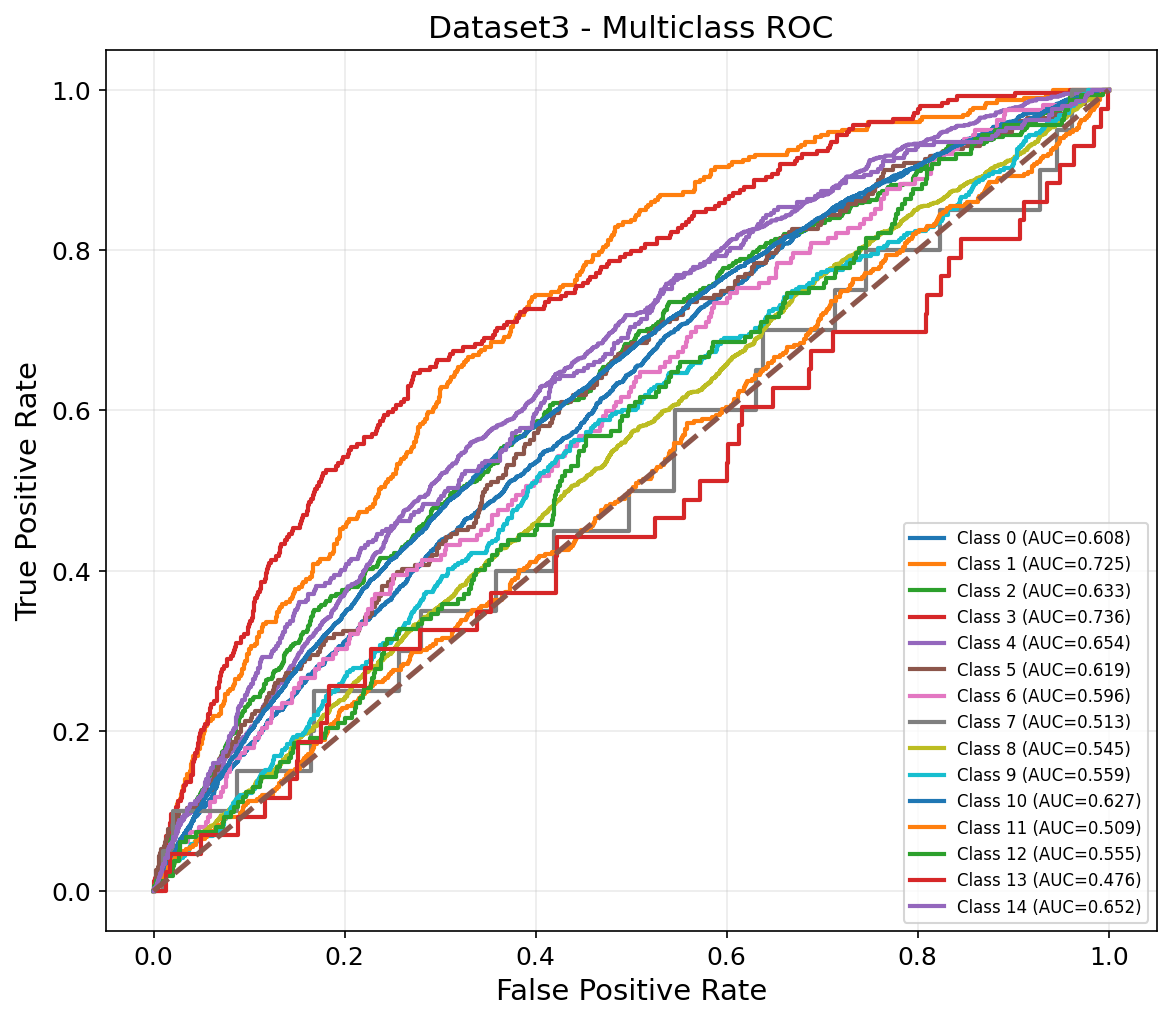


✓ ROC Analysis Completed


In [218]:
# ==========================================================
# STEP 9.18C : MULTICLASS ROC CURVES
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

ROC_FOLDER = os.path.join(
    FIGURE_FOLDER,
    "ROC_Curves"
)

os.makedirs(ROC_FOLDER, exist_ok=True)

roc_summary = []

for dataset in DATASETS.keys():

    print("\n"+"="*70)
    print(dataset)
    print("="*70)

    pred = pd.read_csv(
        os.path.join(
            PREDICTION_FOLDER,
            f"{dataset}_PDVSF_MLP_Predictions.csv"
        )
    )

    y_true = pred["True_Label"].values

    classes = np.unique(y_true)

    y_true_bin = label_binarize(
        y_true,
        classes=classes
    )

    prob_cols = [

        c for c in pred.columns

        if c.startswith("Prob_Class_")

    ]

    y_score = pred[prob_cols].values

    plt.figure(figsize=(8,7))

    # ---------------------------------------------------
    # Per-class ROC
    # ---------------------------------------------------

    for i in range(len(classes)):

        fpr, tpr, _ = roc_curve(
            y_true_bin[:,i],
            y_score[:,i]
        )

        roc_auc = auc(fpr,tpr)

        roc_summary.append({

            "Dataset":dataset,

            "Class":classes[i],

            "AUC":roc_auc

        })

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"Class {classes[i]} (AUC={roc_auc:.3f})"
        )

    plt.plot(
        [0,1],
        [0,1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        f"{dataset} - Multiclass ROC"
    )

    plt.legend(
        fontsize=8,
        loc="lower right"
    )

    plt.tight_layout()

    save_figure(
        f"ROC_Curves/{dataset}_ROC.png"
    )

roc_summary = pd.DataFrame(
    roc_summary
)

roc_summary.to_csv(

    os.path.join(
        TABLE_FOLDER,
        "ROC_AUC_Table.csv"
    ),

    index=False

)

print("\n✓ ROC Analysis Completed")


Dataset1
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Precision_Recall_Curves/Dataset1_PR_Curve.png


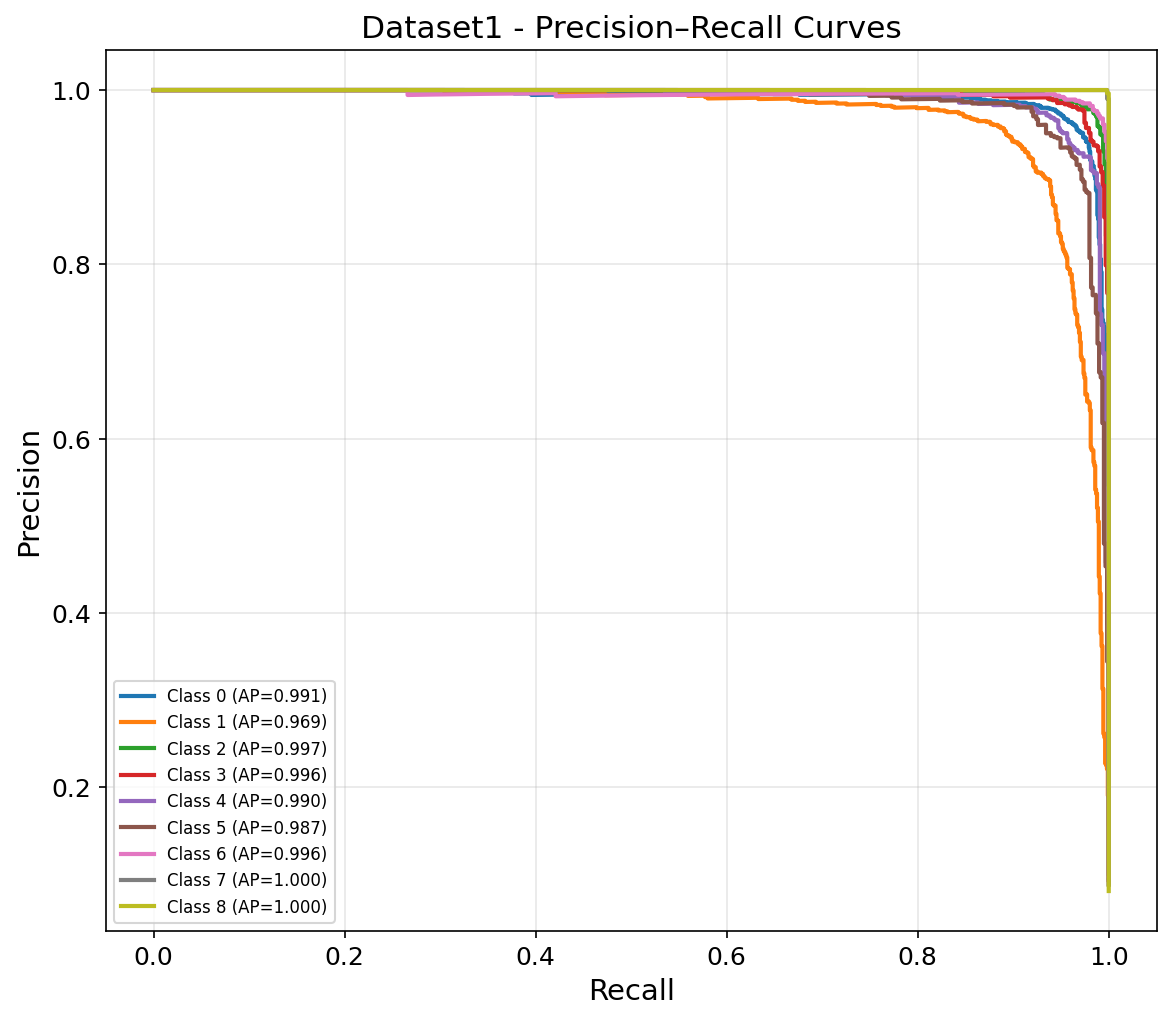


Dataset2
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Precision_Recall_Curves/Dataset2_PR_Curve.png


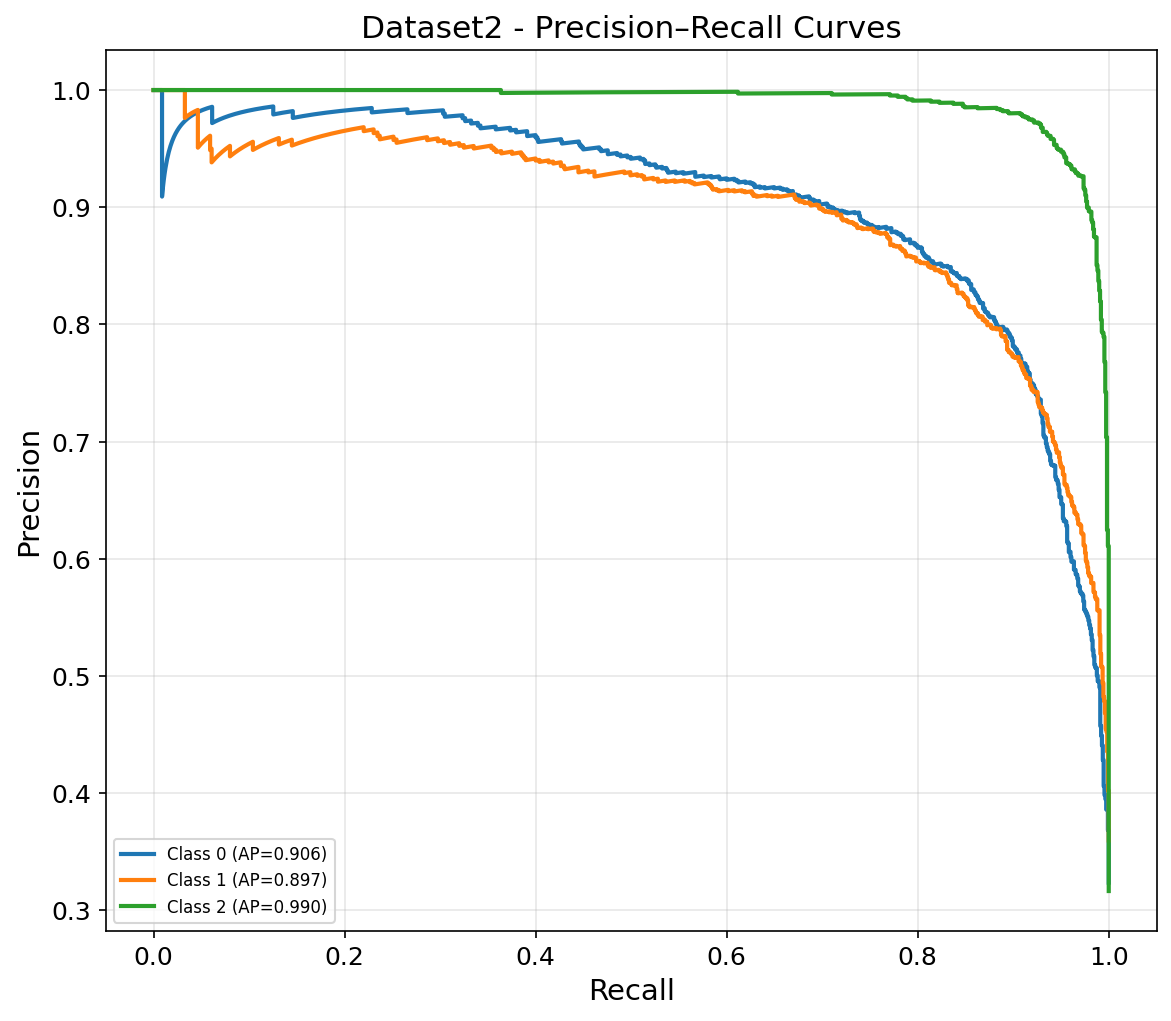


Dataset3
✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Precision_Recall_Curves/Dataset3_PR_Curve.png


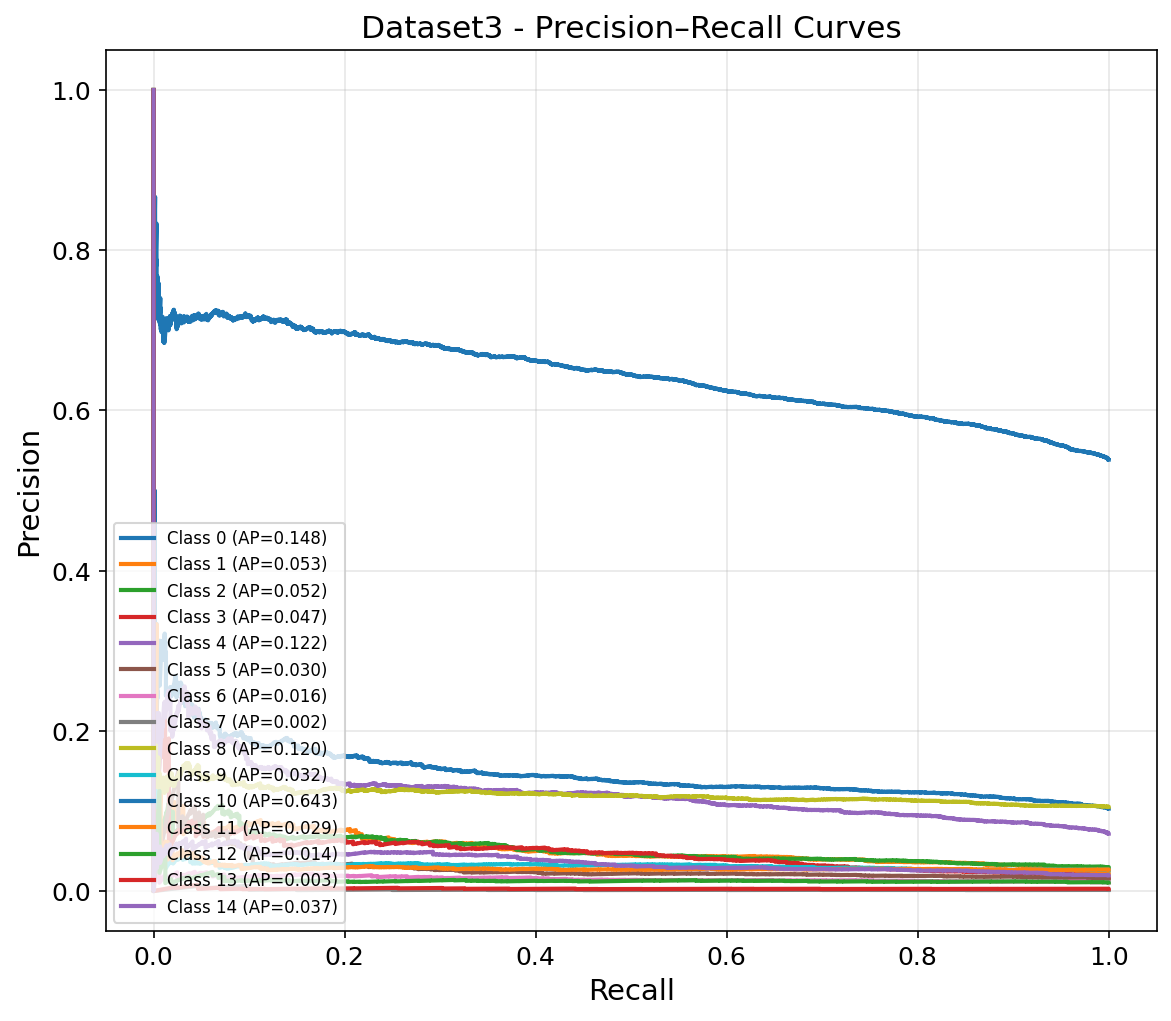


✓ Precision–Recall Analysis Completed


In [219]:
# ==========================================================
# STEP 9.18D : MULTICLASS PRECISION-RECALL CURVES
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

PR_FOLDER = os.path.join(
    FIGURE_FOLDER,
    "Precision_Recall_Curves"
)

os.makedirs(PR_FOLDER, exist_ok=True)

pr_summary = []

for dataset in DATASETS.keys():

    print("\n" + "="*70)
    print(dataset)
    print("="*70)

    pred = pd.read_csv(
        os.path.join(
            PREDICTION_FOLDER,
            f"{dataset}_PDVSF_MLP_Predictions.csv"
        )
    )

    y_true = pred["True_Label"].values
    classes = np.unique(y_true)

    y_true_bin = label_binarize(
        y_true,
        classes=classes
    )

    prob_cols = [
        c for c in pred.columns
        if c.startswith("Prob_Class_")
    ]

    y_score = pred[prob_cols].values

    plt.figure(figsize=(8,7))

    # --------------------------------------------------------
    # Per-Class Precision-Recall Curves
    # --------------------------------------------------------

    for i in range(len(classes)):

        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, i],
            y_score[:, i]
        )

        ap = average_precision_score(
            y_true_bin[:, i],
            y_score[:, i]
        )

        pr_summary.append({

            "Dataset": dataset,

            "Class": classes[i],

            "AveragePrecision": ap

        })

        plt.plot(

            recall,

            precision,

            linewidth=2,

            label=f"Class {classes[i]} (AP={ap:.3f})"

        )

    plt.xlabel("Recall")

    plt.ylabel("Precision")

    plt.title(
        f"{dataset} - Precision–Recall Curves"
    )

    plt.legend(
        fontsize=8,
        loc="lower left"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    save_figure(
        f"Precision_Recall_Curves/{dataset}_PR_Curve.png"
    )

pr_summary = pd.DataFrame(pr_summary)

pr_summary.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Precision_Recall_Table.csv"

    ),

    index=False

)

print("\n✓ Precision–Recall Analysis Completed")

In [220]:
# ==========================================================
# STEP 9.19A : RUNTIME SUMMARY
# ==========================================================

import os
import pandas as pd

runtime_summary = (

    results

    .groupby("FeatureSet")

    .agg({

        "TrainTime":"mean",

        "PredictionTime":"mean",

        "Accuracy_Mean":"mean"

    })

)

runtime_summary = runtime_summary.sort_values(

    by="Accuracy_Mean",

    ascending=False

)

display(runtime_summary)

runtime_summary.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Runtime_Summary.csv"

    )

)

print("✓ Runtime Summary Saved")

,TrainTime,PredictionTime,Accuracy_Mean
FeatureSet,,,
PDVSF,15.845483,0.443015,0.770896
G3+G4,12.455295,0.293776,0.757470
G4,11.492741,0.256760,0.753490
G1+G2+G3,10.998462,0.274200,0.744762
G1+G2,11.020820,0.285598,0.737461
G1,10.156810,0.251835,0.729751
G3,14.423578,0.177584,0.644714
G2,12.595522,0.169613,0.602992


✓ Runtime Summary Saved


In [221]:
# ==========================================================
# STEP 9.19B : FEATURE DIMENSION ANALYSIS
# ==========================================================

feature_dimension = pd.DataFrame({

    "FeatureSet":[

        "G1",

        "G2",

        "G3",

        "G4",

        "G1+G2",

        "G1+G2+G3",

        "G3+G4",

        "PDVSF"

    ],

    "Dimension":[

        64,

        8,

        10,

        64,

        72,

        82,

        74,

        146

    ]

})

feature_dimension = feature_dimension.merge(

    runtime_summary,

    left_on="FeatureSet",

    right_index=True

)

display(feature_dimension)

feature_dimension.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Feature_Dimension_Table.csv"

    ),

    index=False

)

print("✓ Feature Dimension Table Saved")

,FeatureSet,Dimension,TrainTime,PredictionTime,Accuracy_Mean
0,G1,64,10.156810,0.251835,0.729751
1,G2,8,12.595522,0.169613,0.602992
2,G3,10,14.423578,0.177584,0.644714
3,G4,64,11.492741,0.256760,0.753490
4,G1+G2,72,11.020820,0.285598,0.737461
5,G1+G2+G3,82,10.998462,0.274200,0.744762
6,G3+G4,74,12.455295,0.293776,0.757470
7,PDVSF,146,15.845483,0.443015,0.770896


✓ Feature Dimension Table Saved


✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig_Runtime_vs_Accuracy.png


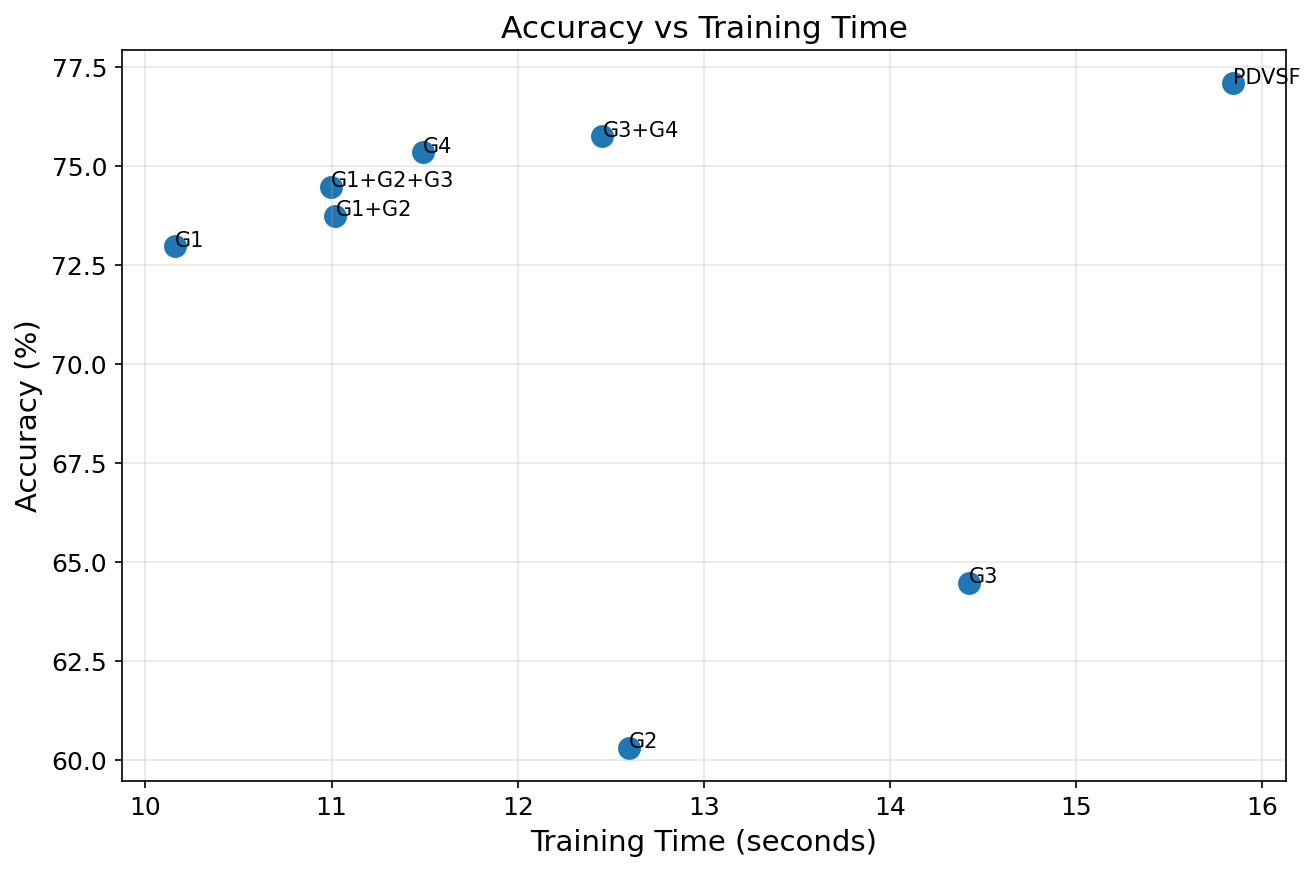

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig_Runtime_vs_Accuracy.png'

In [222]:
# ==========================================================
# STEP 9.19C : ACCURACY VS TRAINING TIME
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))

plt.scatter(

    feature_dimension["TrainTime"],

    feature_dimension["Accuracy_Mean"]*100,

    s=100

)

for _, row in feature_dimension.iterrows():

    plt.text(

        row["TrainTime"],

        row["Accuracy_Mean"]*100,

        row["FeatureSet"],

        fontsize=10

    )

plt.xlabel("Training Time (seconds)")

plt.ylabel("Accuracy (%)")

plt.title("Accuracy vs Training Time")

plt.grid(alpha=0.3)

plt.tight_layout()

save_figure("Fig_Runtime_vs_Accuracy.png")

✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig_Lightweight_Analysis.png


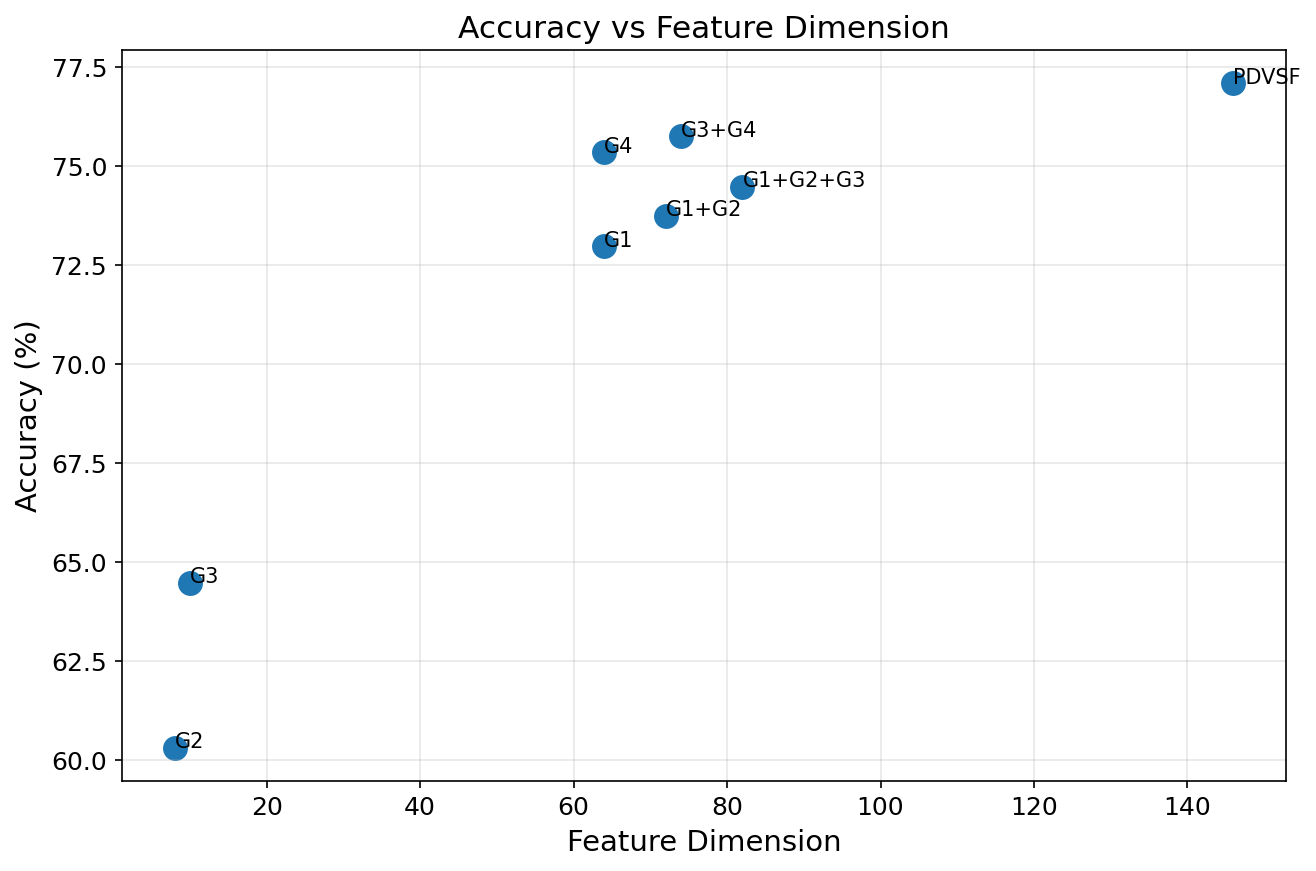

'/kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig_Lightweight_Analysis.png'

In [223]:
# ==========================================================
# STEP 9.19D : LIGHTWEIGHT FEATURE ANALYSIS
# ==========================================================

plt.figure(figsize=(9,6))

plt.scatter(

    feature_dimension["Dimension"],

    feature_dimension["Accuracy_Mean"]*100,

    s=120

)

for _, row in feature_dimension.iterrows():

    plt.text(

        row["Dimension"],

        row["Accuracy_Mean"]*100,

        row["FeatureSet"],

        fontsize=10

    )

plt.xlabel("Feature Dimension")

plt.ylabel("Accuracy (%)")

plt.title("Accuracy vs Feature Dimension")

plt.grid(alpha=0.3)

plt.tight_layout()

save_figure("Fig_Lightweight_Analysis.png")

In [224]:
# ==========================================================
# STEP 9.19E : COMPUTATIONAL PERFORMANCE TABLE
# ==========================================================

import os
import pandas as pd

computational_table = feature_dimension.copy()

computational_table = computational_table[[
    "FeatureSet",
    "Dimension",
    "Accuracy_Mean",
    "TrainTime",
    "PredictionTime"
]]

computational_table.columns = [

    "Feature Set",

    "Feature Dimension",

    "Accuracy",

    "Training Time (sec)",

    "Prediction Time (sec)"

]

computational_table["Accuracy"] = (

    computational_table["Accuracy"]*100

).round(2)

computational_table["Training Time (sec)"] = (

    computational_table["Training Time (sec)"]

).round(3)

computational_table["Prediction Time (sec)"] = (

    computational_table["Prediction Time (sec)"]

).round(3)

computational_table = computational_table.sort_values(

    by="Accuracy",

    ascending=False

)

display(computational_table)

computational_table.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Computational_Performance_Table.csv"

    ),

    index=False

)

print("✓ Computational Performance Table Saved")

,Feature Set,Feature Dimension,Accuracy,Training Time (sec),Prediction Time (sec)
7,PDVSF,146,77.09,15.845,0.443
6,G3+G4,74,75.75,12.455,0.294
3,G4,64,75.35,11.493,0.257
5,G1+G2+G3,82,74.48,10.998,0.274
4,G1+G2,72,73.75,11.021,0.286
0,G1,64,72.98,10.157,0.252
2,G3,10,64.47,14.424,0.178
1,G2,8,60.30,12.596,0.170


✓ Computational Performance Table Saved


✓ Figure Saved : /kaggle/working/PDVSF_RESULTS/Overall_Results/Publication_Figures/Fig_Computational_Efficiency.png


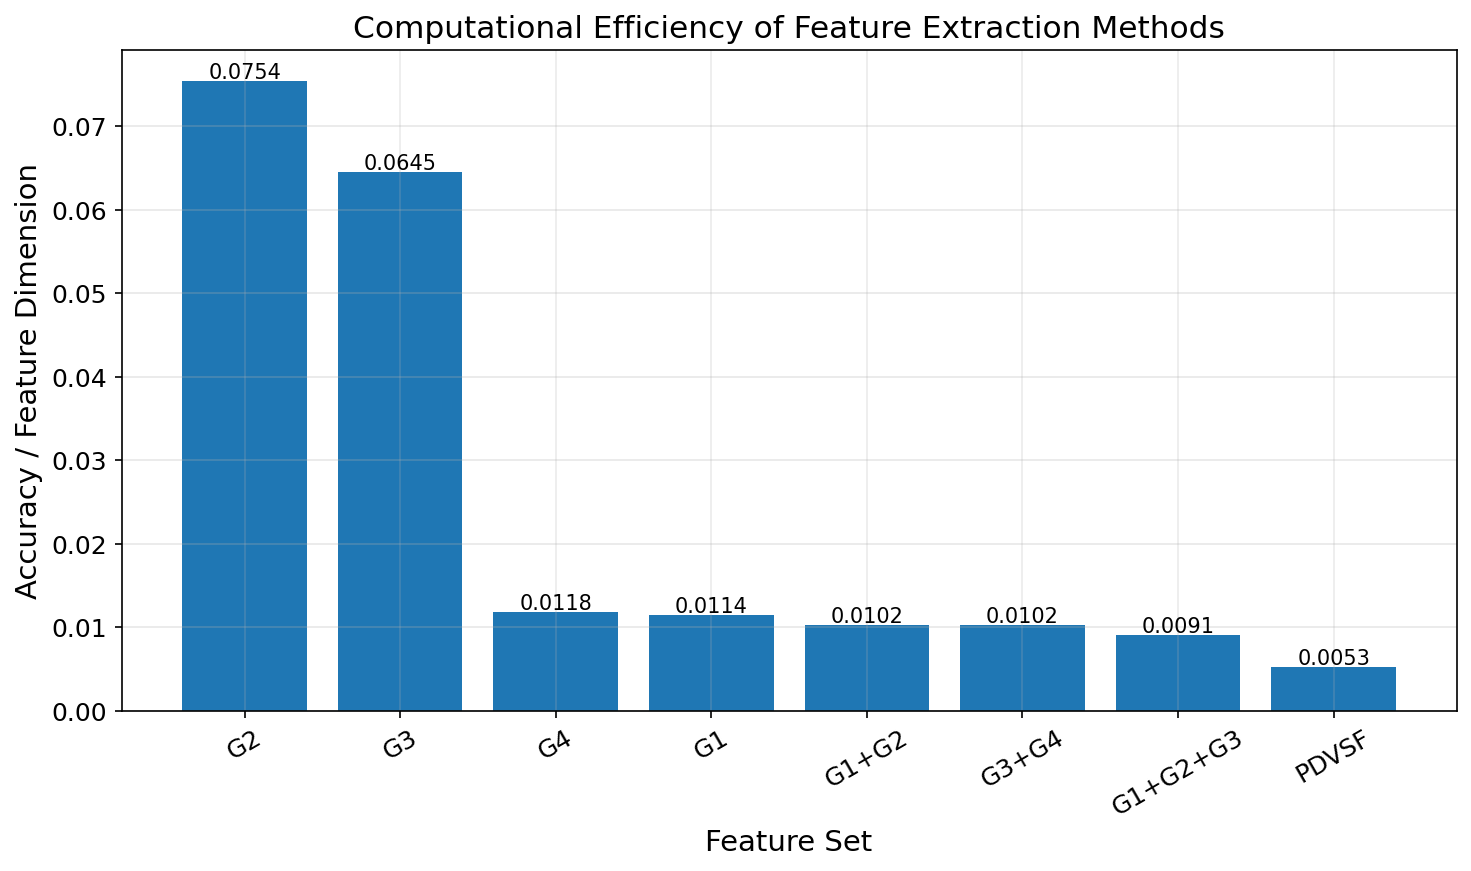

✓ Computational Efficiency Figure Saved


In [225]:
# ==========================================================
# STEP 9.19F : COMPUTATIONAL TRADE-OFF
# ==========================================================

import matplotlib.pyplot as plt

tradeoff = feature_dimension.copy()

tradeoff["Efficiency"] = (

    tradeoff["Accuracy_Mean"]

    /

    tradeoff["Dimension"]

)

tradeoff = tradeoff.sort_values(

    by="Efficiency",

    ascending=False

)

plt.figure(figsize=(10,6))

bars = plt.bar(

    tradeoff["FeatureSet"],

    tradeoff["Efficiency"]

)

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        height+0.0003,

        f"{height:.4f}",

        ha="center",

        fontsize=10

    )

plt.xlabel("Feature Set")

plt.ylabel("Accuracy / Feature Dimension")

plt.title("Computational Efficiency of Feature Extraction Methods")

plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

save_figure(

    "Fig_Computational_Efficiency.png"

)

print("✓ Computational Efficiency Figure Saved")

In [226]:
# ==========================================================
# STEP 9.20A : PUBLICATION SUMMARY
# ==========================================================

import os
import pandas as pd

publication_summary = pd.DataFrame({

    "Experiment":[

        "Datasets",

        "Feature Groups",

        "Machine Learning Models",

        "Cross Validation",

        "Best Feature Set",

        "Best Classifier",

        "Accuracy (%)",

        "Composite Score",

        "Friedman Test",

        "Wilcoxon Test"

    ],

    "Value":[

        3,

        8,

        7,

        "5-Fold",

        "PDVSF",

        "MLP",

        round(

            feature_summary.loc["PDVSF","Accuracy_Mean"]*100,

            2

        ),

        round(

            feature_summary.loc["PDVSF","CompositeScore"],

            4

        ),

        "Significant",

        "Significant"

    ]

})

display(publication_summary)

publication_summary.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Publication_Summary.csv"

    ),

    index=False

)

print("✓ Publication Summary Saved")

,Experiment,Value
0,Datasets,3
1,Feature Groups,8
2,Machine Learning Models,7
3,Cross Validation,5-Fold
4,Best Feature Set,PDVSF
5,Best Classifier,MLP
6,Accuracy (%),77.09
7,Composite Score,0.6436
8,Friedman Test,Significant
9,Wilcoxon Test,Significant


✓ Publication Summary Saved


In [227]:
# ==========================================================
# STEP 9.20B : PUBLICATION CHECKLIST
# ==========================================================

checklist = pd.DataFrame({

    "Component":[

        "Dataset Analysis",

        "Feature Extraction",

        "Feature Statistics",

        "Feature Comparison",

        "Statistical Test",

        "Ablation Study",

        "Runtime Analysis",

        "Confusion Matrix",

        "ROC Curve",

        "Precision Recall",

        "Publication Figures",

        "Computational Analysis"

    ],

    "Completed":[

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES",

        "YES"

    ]

})

display(checklist)

checklist.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Publication_Checklist.csv"

    ),

    index=False

)

print("✓ Checklist Saved")

,Component,Completed
0,Dataset Analysis,YES
1,Feature Extraction,YES
2,Feature Statistics,YES
3,Feature Comparison,YES
4,Statistical Test,YES
5,Ablation Study,YES
6,Runtime Analysis,YES
7,Confusion Matrix,YES
8,ROC Curve,YES
9,Precision Recall,YES


✓ Checklist Saved


In [228]:
# ==========================================================
# STEP 9.20C : FINAL PROJECT STATISTICS
# ==========================================================

project_statistics = pd.DataFrame({

    "Statistic":[

        "Total Datasets",

        "Total Feature Sets",

        "Total ML Models",

        "Total Experiments",

        "Cross Validation",

        "Saved Models",

        "Publication Figures",

        "Statistical Tests"

    ],

    "Value":[

        3,

        8,

        7,

        168,

        "5-Fold",

        168,

        len(os.listdir(FIGURE_FOLDER)),

        2

    ]

})

display(project_statistics)

project_statistics.to_csv(

    os.path.join(

        TABLE_FOLDER,

        "Project_Statistics.csv"

    ),

    index=False

)

print("✓ Project Statistics Saved")

,Statistic,Value
0,Total Datasets,3
1,Total Feature Sets,8
2,Total ML Models,7
3,Total Experiments,168
4,Cross Validation,5-Fold
5,Saved Models,168
6,Publication Figures,12
7,Statistical Tests,2


✓ Project Statistics Saved


In [229]:
# ==========================================================
# STEP 9.20D : FINAL EXPERIMENT SUMMARY
# ==========================================================

print("\n")

print("="*80)

print("PDVSF FEATURE EXTRACTION FRAMEWORK")

print("="*80)

print()

print("Datasets                :",3)

print("Feature Groups          :",8)

print("Machine Learning Models :",7)

print("Experiments             :",168)

print("Cross Validation        : 5-Fold Stratified")

print()

print("Best Feature Set        : PDVSF")

print("Best Classifier         : MLP")

print(

    "Best Accuracy          :",

    round(

        feature_summary.loc["PDVSF","Accuracy_Mean"]*100,

        2

    ),

    "%"

)

print(

    "Composite Score        :",

    round(

        feature_summary.loc["PDVSF","CompositeScore"],

        4

    )

)

print()

print("Statistical Validation : PASSED")

print("Publication Ready      : YES")

print()

print("="*80)



PDVSF FEATURE EXTRACTION FRAMEWORK

Datasets                : 3
Feature Groups          : 8
Machine Learning Models : 7
Experiments             : 168
Cross Validation        : 5-Fold Stratified

Best Feature Set        : PDVSF
Best Classifier         : MLP
Best Accuracy          : 77.09 %
Composite Score        : 0.6436

Statistical Validation : PASSED
Publication Ready      : YES



In [230]:
# ==========================================================
# FINAL STEP : ZIP COMPLETE PDVSF RESULTS
# ==========================================================

import os
import shutil
from datetime import datetime

SOURCE_FOLDER = "/kaggle/working/PDVSF_RESULTS"

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

ZIP_NAME = f"PDVSF_RESULTS_{timestamp}"

OUTPUT_ZIP = f"/kaggle/working/{ZIP_NAME}"

print("=" * 70)
print("Creating Backup...")
print("=" * 70)

shutil.make_archive(
    OUTPUT_ZIP,
    "zip",
    SOURCE_FOLDER
)

zip_file = OUTPUT_ZIP + ".zip"

size_mb = os.path.getsize(zip_file) / (1024 * 1024)

print(f"✓ ZIP Created Successfully")
print(f"✓ File : {zip_file}")
print(f"✓ Size : {size_mb:.2f} MB")

Creating Backup...
✓ ZIP Created Successfully
✓ File : /kaggle/working/PDVSF_RESULTS_20260704_091714.zip
✓ Size : 1905.74 MB
